<img src="https://raw.githubusercontent.com/Mika1904/sentinel/main/Project_Code/figures/Sentinel_Logo.png" width="160" alt="Team Sentinel Logo">

# Sentinel: Predicting Cancer Drug Sensitivity from Tumor Genomics
Veritas AI International High School Hackathon 2026 | AI + Health track

*This project is a prototype and is not medical advice. All data comes from cancer cell lines grown in the lab, not from patients.*

**How to run it.** Every output is already saved, so you can just scroll through. To run it yourself, open it in Google Colab and use *Runtime → Run all*. It takes around 15–25 minutes on free Colab, mostly because of a 1.3 GB gene expression download and three stability checks. Setting `RUN_STABILITY_CHECKS = False` in Section 1 skips those checks and cuts the time by about 40%. The app is in Section 29, and you can also try it online at [sentinel-rb92.onrender.com](https://sentinel-rb92.onrender.com) (the free server sleeps when idle, so the first load can take about a minute).

**Who it is for.** A cancer researcher with a new cell line can usually test only a handful of the hundreds of available drugs. Sentinel helps choose which ones to test first. The researcher enters the cell line's tissue and which of 84 common cancer genes are mutated, and Sentinel ranks 286 drugs (295 drug IDs), flags the ones predicted to be sensitive, gives each a confidence level and shows which genes move each prediction. Held-out example cell lines also use their RNA-seq gene expression; for a new cell line without it, the app uses that tissue's average and says so.

**Result.** On 192 cell lines the models never saw, 52.1% of Sentinel's top 10 drugs were truly sensitive, against 20.3% for drugs picked at random. The final model explains 28.4% of the differences between cell lines on the same drug (within-drug R² 0.284), against 17.7% for a simple per-drug + tissue average, and it beat our earlier model on all 10 repeated random splits.

**Why it matters for health.** Before a cancer drug can help patients, researchers need to find out which tumors it works on, mostly by testing it on cancer cells grown in the lab. Running the most promising experiments first gets those answers sooner, and doctors later use them to match treatments to a patient's tumor. Sentinel does not make treatment decisions and has not been tested on patient samples.

**How this notebook is organized**

| Part | Sections | What happens |
|---|---|---|
| Data | 1–7 | Download, check, explore and clean the data |
| First model | 8–20 | Split by cell line, baselines, LightGBM, missed cases and false alarms, sex and age groups, failures, drug shortlist |
| Stress test and fix | 21–23 | Test the app on known drug–gene pairs, find that it ignores mutations, fix it with a model for each drug |
| Gene expression | 24–28 | Add RNA-seq expression: a first attempt that failed our check, then the final model |
| App and summary | 29–31 | The Sentinel app, summary and sources |

Every model choice is made by cross-validation on the 766 training cell lines; the 192 test cell lines are only used to report results. Each improvement had to pass a rule we wrote down before running it, and earlier models are kept so the whole path is visible.


## 1. Setup
`RUN_STABILITY_CHECKS` controls the three repeated-split checks (Sections 18, 23 and 28), which retrain the models 10 times each. Their results are described in the text either way; set it to `False` for a faster run.

In [1]:
RUN_STABILITY_CHECKS = True  # False skips the repeated-split checks in Sections 18, 23 and 28 (about 40% of the run time)

import os
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")

os.makedirs("data/raw", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 2. Download the data
All files come from the Wellcome Sanger Institute (Cell Model Passports). Sanger's usage policy doesn't allow us to re-share the files, so the notebook downloads them directly instead of keeping them in our repository. Sources and citations are listed in `data/DATA_SOURCES.md`.

In [2]:
FILES = {
    "GDSC2_fitted_dose_response_27Oct23.xlsx": "https://cmp.cog.sanger.ac.uk/download/GDSC2_fitted_dose_response_27Oct23.xlsx",
    "model_list_20261013.csv": "https://cog.sanger.ac.uk/cmp/download/model_list_20261013.csv",
    "mutations_summary_20260724.zip": "https://cog.sanger.ac.uk/cmp/download/mutations_summary_20260724.zip",
    "model_dataset_availability_20260727.csv": "https://cog.sanger.ac.uk/cmp/download/model_dataset_availability_20260727.csv",
    "rnaseq_merged_20260323.zip": "https://cog.sanger.ac.uk/cmp/download/rnaseq_merged_20260323.zip",
}

for name, url in FILES.items():
    path = "data/raw/" + name
    if not os.path.exists(path):  # skip files we already downloaded
        print("downloading", name)
        urllib.request.urlretrieve(url, path)

## 3. Load the tables

In [3]:
response = pd.read_excel("data/raw/GDSC2_fitted_dose_response_27Oct23.xlsx")   # drug responses (LN_IC50)
models = pd.read_csv("data/raw/model_list_20261013.csv", low_memory=False)     # cell line info (tissue, sex, age)
mutations = pd.read_csv("data/raw/mutations_summary_20260724.zip")              # driver mutations per cell line
available = pd.read_csv("data/raw/model_dataset_availability_20260727.csv")     # which cell lines were sequenced

for name, table in [("response", response), ("models", models), ("mutations", mutations), ("available", available)]:
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")

response.head(3)

response: 242,036 rows, 16 columns
models: 2,292 rows, 110 columns
mutations: 15,025 rows, 20 columns
available: 2,039 rows, 25 columns


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,CELL_LINE_NAME,SANGER_MODEL_ID,CANCER_TYPE,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,343,15946310,PFSK-1,SIDM01132,Other Solid Cancers,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-1.463887,0.930220,0.089052,0.433123
1,GDSC2,343,15946548,A673,SIDM00848,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-4.869455,0.614970,0.111351,-1.421100
2,GDSC2,343,15946830,ES5,SIDM00263,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-3.360586,0.791072,0.142855,-0.599569


## 4. Data checks
GDSC2 calls the cell line ID `SANGER_MODEL_ID`; the other files call it `model_id`. We only keep cell lines that were sequenced, because for an unsequenced cell line a missing mutation doesn't mean the gene is normal.

In [4]:
print("cell lines:", response["SANGER_MODEL_ID"].nunique())
print("drug IDs:", response["DRUG_ID"].nunique())
print("missing LN_IC50 values:", response["LN_IC50"].isna().sum())
print("duplicate cell line + drug pairs:", response.duplicated(["SANGER_MODEL_ID", "DRUG_ID"]).sum())

ids = response["SANGER_MODEL_ID"].drop_duplicates()
print("cell lines found in the model list:", ids.isin(models["model_id"]).sum())

seq_columns = ["Mutation Sanger Cell Lines (WES)", "Mutation Broad Cell Lines (WES)", "Mutation Sanger Cell Lines (WGS)"]
sequenced = available[available[seq_columns].any(axis=1)]["model_id"]
print("cell lines that were sequenced:", ids.isin(sequenced).sum())

# a few cell lines are not cancer cell lines - we remove them before modelling
non_cancer = models[models["cancer_type"].str.contains("Non-Cancerous", na=False) & models["model_id"].isin(ids)]
print("non-cancer cell lines:", len(non_cancer), list(non_cancer["model_name"]))

# some drugs were screened twice under different IDs, so DRUG_ID is used as the key, not the name
ids_per_name = response.groupby("DRUG_NAME")["DRUG_ID"].nunique()
print("drug names with more than one ID:", list(ids_per_name[ids_per_name > 1].index))

cell lines: 969
drug IDs: 295
missing LN_IC50 values: 0
duplicate cell line + drug pairs: 0
cell lines found in the model list: 969
cell lines that were sequenced: 965
non-cancer cell lines: 7 ['BPH-1', 'Hs-445', 'ARH-77', 'IM-9', 'PWR-1E', 'RPMI-6666', 'WIL2-NS']
drug names with more than one ID: ['Acetalax', 'Dactinomycin', 'Docetaxel', 'Fulvestrant', 'GSK343', 'Oxaliplatin', 'Selumetinib', 'Ulixertinib', 'Uprosertib']


## 5. Build the clean table

In [5]:
data = response[response["SANGER_MODEL_ID"].isin(sequenced)]

tissue = models[["model_id", "tissue"]].rename(columns={"model_id": "SANGER_MODEL_ID"})
data = data.merge(tissue, on="SANGER_MODEL_ID", how="left")
print("cell lines kept:", data["SANGER_MODEL_ID"].nunique(), "| missing tissue:", data["tissue"].isna().sum())

# mutation matrix: one row per cell line, one column per gene, 1 = mutated
cell_lines = data["SANGER_MODEL_ID"].unique()
mut = mutations[mutations["model_id"].isin(cell_lines)]
mut_matrix = pd.crosstab(mut["model_id"], mut["gene_symbol"]).clip(upper=1)
mut_matrix = mut_matrix.reindex(cell_lines, fill_value=0)  # sequenced lines with no listed mutations get all zeros
mut_matrix.index.name = "SANGER_MODEL_ID"
print("mutation matrix:", mut_matrix.shape[0], "cell lines x", mut_matrix.shape[1], "genes")


cell lines kept: 965 | missing tissue: 0
mutation matrix: 965 cell lines x 597 genes


## 6. Exploring the data
### Cell lines per tissue

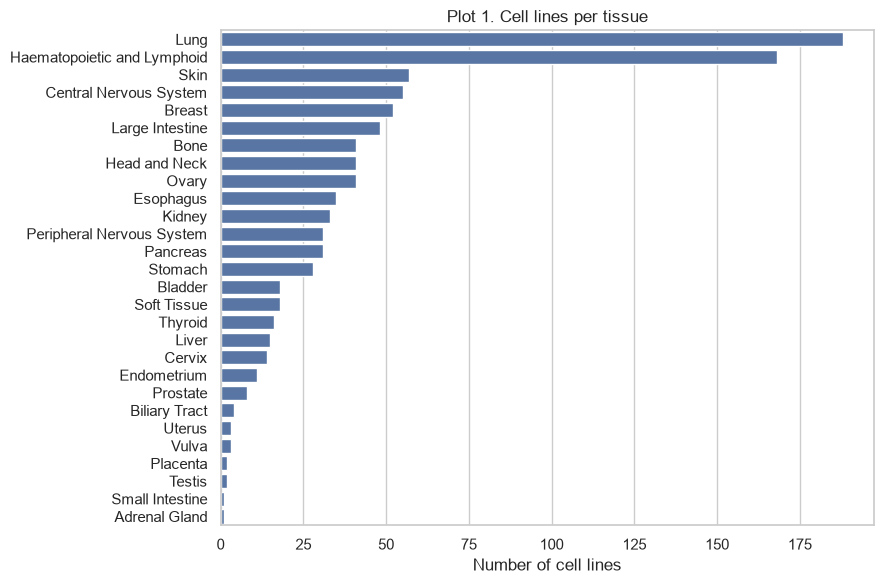

tissue
Lung                           188
Haematopoietic and Lymphoid    168
Skin                            57
Central Nervous System          55
Breast                          52
Large Intestine                 48
Bone                            41
Head and Neck                   41
Ovary                           41
Esophagus                       35
Kidney                          33
Peripheral Nervous System       31
Pancreas                        31
Stomach                         28
Bladder                         18
Soft Tissue                     18
Thyroid                         16
Liver                           15
Cervix                          14
Endometrium                     11
Prostate                         8
Biliary Tract                    4
Uterus                           3
Vulva                            3
Placenta                         2
Testis                           2
Small Intestine                  1
Adrenal Gland                    1


In [6]:
tissue_counts = data.drop_duplicates("SANGER_MODEL_ID")["tissue"].value_counts()

plt.figure(figsize=(9, 6))
sns.barplot(x=tissue_counts.values, y=tissue_counts.index)
plt.xlabel("Number of cell lines")
plt.ylabel("")
plt.title("Plot 1. Cell lines per tissue")
plt.tight_layout()
plt.savefig("figures/plot1_cell_lines_per_tissue.png", dpi=150)
plt.show()

print(tissue_counts.to_string())

Lung (188) and blood cancers (168) make up the largest groups. Breast (52) and large intestine/colorectal (48) also have enough cell lines for case studies. Some tissues have very few cell lines (prostate 8, biliary tract 4), so any result for those tissues on their own won't be reliable.

### Distribution of drug sensitivity (ln IC50)

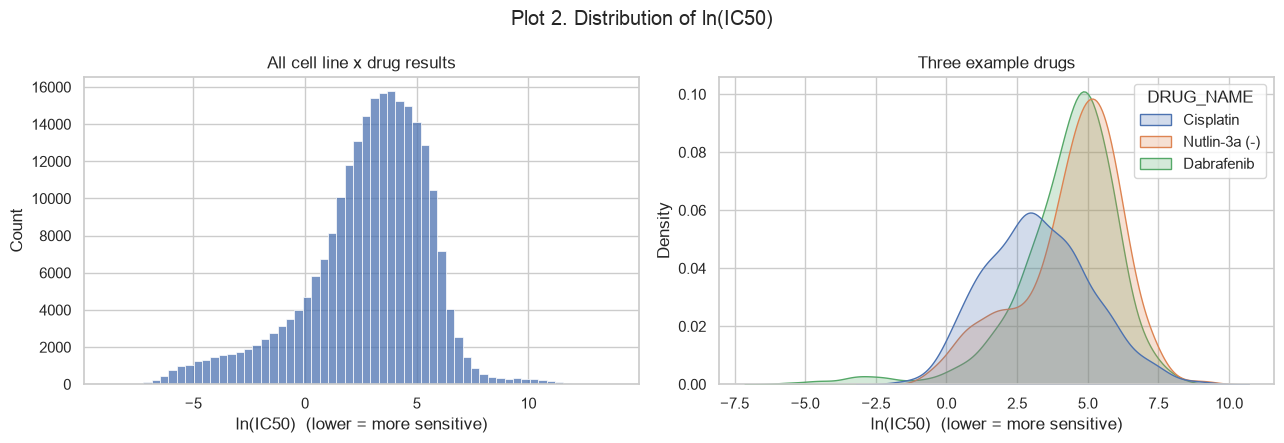

count    241030.00
mean          2.82
std           2.76
min          -8.75
25%           1.51
50%           3.24
75%           4.70
max          13.82
DRUG_NAME
Cisplatin        3.23
Dabrafenib       4.25
Nutlin-3a (-)    4.42
results above the highest tested dose: 71.8 %


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data["LN_IC50"], bins=60, ax=axes[0])
axes[0].set_title("All cell line x drug results")
axes[0].set_xlabel("ln(IC50)  (lower = more sensitive)")

# 1373 = Dabrafenib, 1047 = Nutlin-3a, 1005 = Cisplatin
examples = data[data["DRUG_ID"].isin([1373, 1047, 1005])]
sns.kdeplot(data=examples, x="LN_IC50", hue="DRUG_NAME", fill=True, ax=axes[1])
axes[1].set_title("Three example drugs")
axes[1].set_xlabel("ln(IC50)  (lower = more sensitive)")

fig.suptitle("Plot 2. Distribution of ln(IC50)")
plt.tight_layout()
plt.savefig("figures/plot2_ln_ic50_distribution.png", dpi=150)
plt.show()

print(data["LN_IC50"].describe().round(2).to_string())
print(examples.groupby("DRUG_NAME")["LN_IC50"].mean().round(2).to_string())

# IC50 above the highest tested dose means the value was extrapolated from the fitted curve
above_max = data["LN_IC50"] > np.log(data["MAX_CONC"])
print("results above the highest tested dose:", round(above_max.mean() * 100, 1), "%")

Across 241,030 results, ln(IC50) ranges from about -8.8 to 13.8 with a median of 3.24; the middle half lies between 1.51 and 4.70. Each drug has its own typical range (mean 3.23 for Cisplatin, 4.25 for Dabrafenib, 4.42 for Nutlin-3a) because every drug was tested at its own doses. So raw values shouldn't be compared directly across drugs, and any baseline has to at least predict each drug's average.

In 71.8% of results the IC50 is above the highest dose actually tested, meaning 50% inhibition wasn't reached and the value is an estimate from the fitted curve. We keep these results but treat them as less certain.

### Most frequently mutated genes

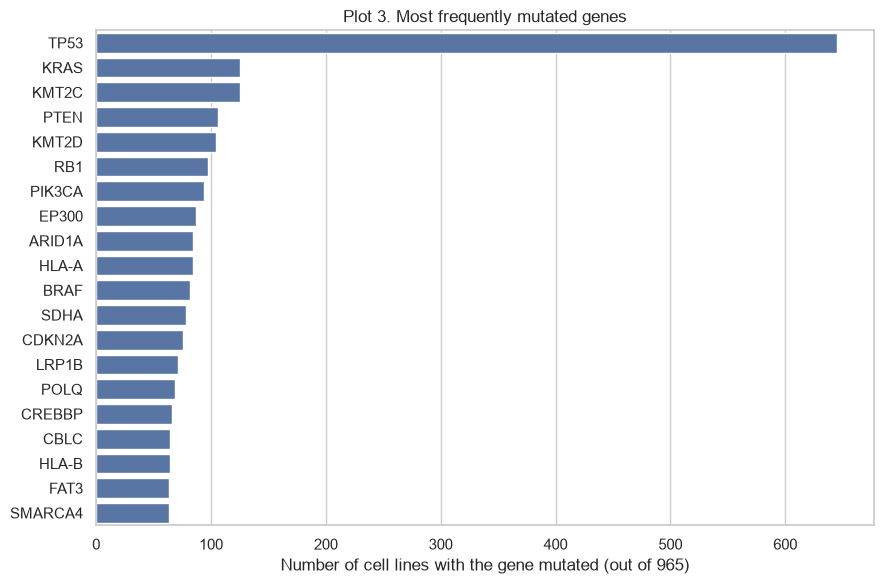

gene_symbol
TP53       645
KRAS       125
KMT2C      125
PTEN       106
KMT2D      104
RB1         97
PIK3CA      94
EP300       87
ARID1A      84
HLA-A       84
BRAF        82
SDHA        78
CDKN2A      76
LRP1B       71
POLQ        69
CREBBP      66
CBLC        64
HLA-B       64
FAT3        63
SMARCA4     63
EGFR: 21
TP53: p.? in 60 of 645 cell lines
KRAS: p.G12D in 32 of 125 cell lines
KMT2C: p.A1685S in 69 of 125 cell lines
PTEN: p.? in 18 of 106 cell lines
KMT2D: p.P2354fs*30 in 7 of 104 cell lines
RB1: p.? in 29 of 97 cell lines
PIK3CA: p.E545K in 22 of 94 cell lines
EP300: p.? in 14 of 87 cell lines
ARID1A: p.D1850fs*4 in 8 of 84 cell lines
HLA-A: p.Q78R in 43 of 84 cell lines
BRAF: p.V600E in 65 of 82 cell lines
SDHA: p.L649fs*4 in 69 of 78 cell lines
CDKN2A: p.R80* in 9 of 76 cell lines
LRP1B: p.? in 22 of 71 cell lines
POLQ: p.V310G in 47 of 69 cell lines
CREBBP: p.? in 11 of 66 cell lines
CBLC: p.Q419fs*81 in 59 of 64 cell lines
HLA-B: p.E69G in 34 of 64 cell lines
FAT3: p.Q

In [8]:
gene_counts = mut_matrix.sum().sort_values(ascending=False)
top20 = gene_counts.head(20)

plt.figure(figsize=(9, 6))
sns.barplot(x=top20.values, y=top20.index)
plt.xlabel(f"Number of cell lines with the gene mutated (out of {len(mut_matrix)})")
plt.ylabel("")
plt.title("Plot 3. Most frequently mutated genes")
plt.tight_layout()
plt.savefig("figures/plot3_mutation_frequency.png", dpi=150)
plt.show()

print(top20.to_string())
print("EGFR:", gene_counts["EGFR"])

# how many cell lines share the single most common change in each gene?
for gene in top20.index:
    changes = mut[mut["gene_symbol"] == gene].drop_duplicates(["model_id", "protein_mutation"])
    top_change = changes["protein_mutation"].value_counts()
    print(f"{gene}: {top_change.index[0]} in {top_change.iloc[0]} of {top20[gene]} cell lines")

TP53 is mutated in 645 of the 965 cell lines, followed by KRAS (125), PTEN (106), PIK3CA (94) and BRAF (82). EGFR is mutated in only 21, so any result involving EGFR rests on few examples.

Some of these counts are misleading. For SDHA, CBLC, POLQ, KMT2C, HLA-A and HLA-B, most of the "mutations" are the exact same change shared by many unrelated cell lines, which usually points to an inherited variant or a sequencing artefact rather than a cancer mutation. We leave these genes out of the model (section 7).

### Do mutations change drug response?
Two well-known examples: Dabrafenib targets mutated BRAF, so BRAF-mutant cell lines should be more sensitive (Hauschild et al. 2012). Nutlin-3a blocks MDM2, the protein that switches off normal p53, so it should work better when TP53 is *not* mutated (Vassilev et al. 2004).

Dabrafenib - median ln(IC50) by BRAF status:
         count  median
mutated               
no         870    4.71
yes         80    1.61 

Nutlin-3a (-) - median ln(IC50) by TP53 status:
         count  median
mutated               
no         319    2.76
yes        645    5.16 



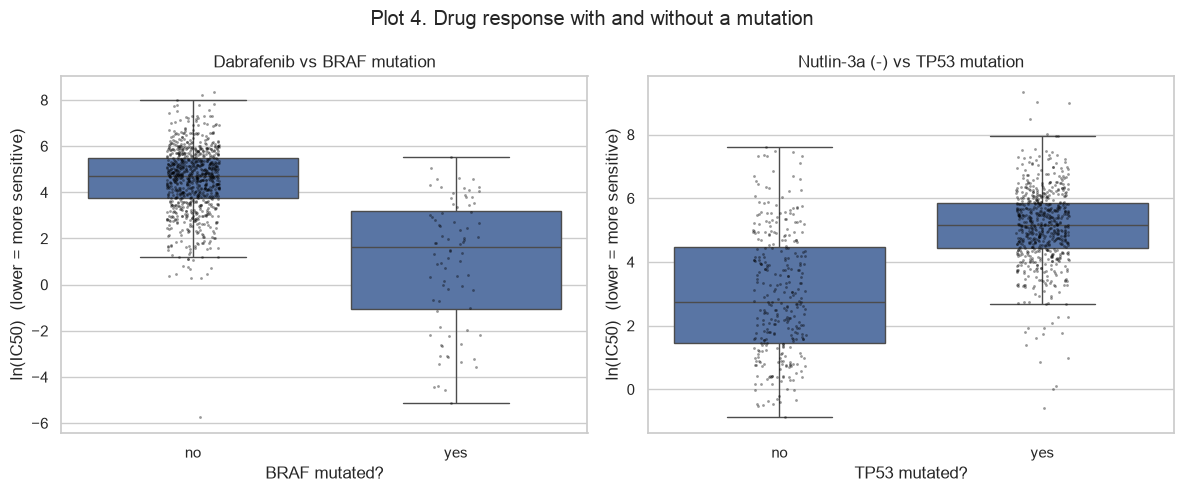

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, drug_id, gene in [(axes[0], 1373, "BRAF"), (axes[1], 1047, "TP53")]:
    d = data[data["DRUG_ID"] == drug_id].copy()
    d["mutated"] = d["SANGER_MODEL_ID"].map(mut_matrix[gene]).map({0: "no", 1: "yes"})
    sns.boxplot(data=d, x="mutated", y="LN_IC50", order=["no", "yes"], showfliers=False, ax=ax)
    sns.stripplot(data=d, x="mutated", y="LN_IC50", order=["no", "yes"], color="black", size=2, alpha=0.4, ax=ax)
    drug = d["DRUG_NAME"].iloc[0]
    ax.set_title(f"{drug} vs {gene} mutation")
    ax.set_xlabel(f"{gene} mutated?")
    ax.set_ylabel("ln(IC50)  (lower = more sensitive)")
    print(drug, f"- median ln(IC50) by {gene} status:")
    print(d.groupby("mutated")["LN_IC50"].agg(["count", "median"]).round(2).to_string(), "\n")

fig.suptitle("Plot 4. Drug response with and without a mutation")
plt.tight_layout()
plt.savefig("figures/plot4_mutation_vs_response.png", dpi=150)
plt.show()

Both examples go in the direction biology predicts. BRAF-mutant cell lines (80) have a median ln(IC50) of 1.61 for Dabrafenib against 4.71 for the other 870. For Nutlin-3a, cell lines without a TP53 mutation (319) have a median of 2.76 against 5.16 for TP53-mutant lines (645).

This is an association in lab data rather than proof of cause, and the groups still overlap, so a single mutation isn't enough to predict response. That is the gap a model combining several genes and the tissue type could help with.

## 7. Exclusions and gene features
We remove the 7 non-cancer cell lines. We also leave out genes where most "mutations" are one identical change shared by many unrelated cell lines (likely inherited variants or sequencing artefacts): the six found in section 6, plus PABPC1 and CLTCL1, which show the same pattern. The loop below prints the evidence. Of the remaining genes, we use those mutated in at least 20 cell lines so each one has enough examples.

In [10]:
columns = ["SANGER_MODEL_ID", "CELL_LINE_NAME", "tissue", "DRUG_ID", "DRUG_NAME", "PUTATIVE_TARGET", "LN_IC50"]
data = data[columns]

non_cancer = models.loc[models["cancer_type"].str.contains("Non-Cancerous", na=False), "model_id"]
data = data[~data["SANGER_MODEL_ID"].isin(non_cancer)].reset_index(drop=True)
mut_matrix = mut_matrix[~mut_matrix.index.isin(non_cancer)]
print("cell lines:", data["SANGER_MODEL_ID"].nunique(), "| results:", len(data))

UNRELIABLE_GENES = ["SDHA", "CBLC", "POLQ", "KMT2C", "HLA-A", "HLA-B", "PABPC1", "CLTCL1"]
# how many cell lines share the single most common change in each gene?
# (DNA-level changes are used here because some protein changes are only recorded as "p.?")
for gene in UNRELIABLE_GENES:
    rows = mutations[(mutations["gene_symbol"] == gene) & mutations["model_id"].isin(mut_matrix.index)]
    rows = rows.drop_duplicates(["model_id", "cdna_mutation"])
    top = rows["cdna_mutation"].value_counts()
    print(f"{gene}: {top.index[0]} in {top.iloc[0]} of {rows['model_id'].nunique()} cell lines")

gene_counts = mut_matrix.sum()
GENES = [g for g in gene_counts.index if gene_counts[g] >= 20 and g not in UNRELIABLE_GENES]
GENES = sorted(GENES, key=lambda g: -gene_counts[g])  # most frequently mutated first
print("\ngene features:", len(GENES))
print(GENES)
print("EGFR is mutated in", gene_counts["EGFR"], "cell lines")

data = data.merge(mut_matrix[GENES], left_on="SANGER_MODEL_ID", right_index=True, how="left")

cell lines: 958 | results: 239081
SDHA: c.1944_1945delTT in 69 of 78 cell lines


CBLC: c.1253_1254insC in 59 of 64 cell lines
POLQ: c.929T>G in 47 of 69 cell lines
KMT2C: c.5053G>T in 69 of 124 cell lines
HLA-A: c.233A>G in 42 of 83 cell lines
HLA-B: c.206A>G in 33 of 63 cell lines
PABPC1: c.999delA in 30 of 38 cell lines
CLTCL1: c.4041+5C>T in 21 of 30 cell lines

gene features: 84
['TP53', 'KRAS', 'PTEN', 'KMT2D', 'RB1', 'PIK3CA', 'EP300', 'ARID1A', 'BRAF', 'CDKN2A', 'LRP1B', 'CREBBP', 'FAT3', 'SMARCA4', 'NRAS', 'NF1', 'RPL22', 'APC', 'FBXW7', 'ACVR2A', 'MSH6', 'SMAD4', 'BAX', 'ZFHX3', 'KMT2B', 'NBEA', 'NIPBL', 'HERC2', 'STK11', 'PIK3R1', 'UBR5', 'BRCA2', 'ATM', 'HSPG2', 'BCORL1', 'CTCF', 'FAT1', 'FAT4', 'SETD2', 'ASXL1', 'CASP8', 'FBN2', 'MLH1', 'PTPRT', 'BIRC6', 'CDH1', 'MGA', 'NF2', 'NFE2L2', 'PBRM1', 'RNF43', 'VHL', 'ARID2', 'BCOR', 'KDM6A', 'TRRAP', 'ARID1B', 'STAG2', 'KEAP1', 'NOTCH1', 'ZNF208', 'ATF7IP', 'BCL9L', 'CRTC1', 'RHOA', 'BRCA1', 'MYH9', 'PARP4', 'PTPN13', 'SPEN', 'MSH2', 'PRDM2', 'TGFBR2', 'EPHA3', 'EZH2', 'GRIN2A', 'PTPRB', 'B2M', 'EGFR', 'EPHA7

After removing the non-cancer cell lines we have 958 cell lines and 239,081 results. 84 genes pass the filter, from TP53 down to DDX3X. EGFR only just makes it (21 cell lines), so anything involving EGFR rests on few examples.

## 8. Train/test split by cell line
We hold back 20% of the cell lines as a test set. All results for a test cell line stay in the test set, so every score below is measured on cell lines the models have never seen. The test set isn't used for any decisions.

In [11]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(data, groups=data["SANGER_MODEL_ID"]))
train = data.iloc[train_idx]
test = data.iloc[test_idx]

print("train:", train["SANGER_MODEL_ID"].nunique(), "cell lines,", len(train), "results")
print("test: ", test["SANGER_MODEL_ID"].nunique(), "cell lines,", len(test), "results")

overlap = set(train["SANGER_MODEL_ID"]) & set(test["SANGER_MODEL_ID"])
print("cell lines in both sets:", len(overlap))
assert len(overlap) == 0, "a cell line appears in both train and test"

train: 766 cell lines, 191613 results
test:  192 cell lines, 47468 results
cell lines in both sets: 0


## 9. Evaluation metrics
- **RMSE**: the typical size of a prediction error, in ln(IC50) units (lower is better).
- **R²**: the share of all variation that the predictions explain.
- **Within-drug R²**: knowing *which drug* already explains a lot, because drugs differ so much from each other. This score only looks at differences between cell lines for the same drug, which is what tissue and mutations should add. It is measured against each drug's average in the test set, so a method using training-set averages can score slightly below 0.

In [12]:
y_test = test["LN_IC50"]
drug_mean_test = test.groupby("DRUG_ID")["LN_IC50"].transform("mean")

def score(name, pred):
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    # 1 - model error / error of always predicting each drug's test-set average
    within_drug_r2 = 1 - ((y_test - pred) ** 2).sum() / ((y_test - drug_mean_test) ** 2).sum()
    return {"method": name, "RMSE": round(float(rmse), 3), "R2": round(float(r2), 3),
            "within-drug R2": round(float(within_drug_r2), 3)}

results = []

## 10. Baselines
All averages are calculated on the training set only.
1. **Per-drug average**: predict the drug's average ln(IC50).
2. **Per-drug + tissue average**: predict the average for that drug in that tissue, falling back to the drug average when the combination doesn't appear in training.
3. **Linear regression** on drug, tissue and the gene features.

In [13]:
# per-drug average
drug_avg = train.groupby("DRUG_ID")["LN_IC50"].mean()
pred_drug = test["DRUG_ID"].map(drug_avg)
results.append(score("Per-drug average", pred_drug))

# per-drug + tissue average
drug_tissue_avg = train.groupby(["DRUG_ID", "tissue"])["LN_IC50"].mean().rename("avg").reset_index()
pred_drug_tissue = test[["DRUG_ID", "tissue"]].merge(drug_tissue_avg, on=["DRUG_ID", "tissue"], how="left")["avg"]
print("test results without a matching drug + tissue average:", pred_drug_tissue.isna().sum(),
      "| with a tissue never seen in training:", (~test["tissue"].isin(train["tissue"])).sum())
pred_drug_tissue = pred_drug_tissue.fillna(pred_drug.reset_index(drop=True)).values
results.append(score("Per-drug + tissue average", pred_drug_tissue))

# linear regression (drug and tissue one-hot encoded, genes are already 0/1)
encoder = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["DRUG_ID", "tissue"])],
                            remainder="passthrough")
X_train_lr = encoder.fit_transform(train[["DRUG_ID", "tissue"] + GENES])
X_test_lr = encoder.transform(test[["DRUG_ID", "tissue"] + GENES])
linear = LinearRegression().fit(X_train_lr, train["LN_IC50"])
pred_linear = linear.predict(X_test_lr)
results.append(score("Linear regression", pred_linear))

# same linear model without the gene features, for comparison
encoder_ng = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["DRUG_ID", "tissue"])])
linear_ng = LinearRegression().fit(encoder_ng.fit_transform(train[["DRUG_ID", "tissue"]]), train["LN_IC50"])
pred_linear_ng = linear_ng.predict(encoder_ng.transform(test[["DRUG_ID", "tissue"]]))
print("linear regression without genes - within-drug R2:", score("no genes", pred_linear_ng)["within-drug R2"])

pd.DataFrame(results)

test results without a matching drug + tissue average: 551 | with a tissue never seen in training: 534


linear regression without genes - within-drug R2: 0.121


,method,RMSE,R2,within-drug R2
0,Per-drug average,1.464,0.716,-0.007
1,Per-drug + tissue average,1.324,0.768,0.177
2,Linear regression,1.403,0.739,0.076


## 11. LightGBM
LightGBM builds many small decision trees, each correcting the errors of the previous ones, so unlike linear regression it can pick up combinations such as a mutation that only matters for certain drugs. This first version uses the default settings (Ke et al. 2017; gradient boosting: Friedman 2001).

In [14]:
features = ["DRUG_ID", "tissue"] + GENES
X_train = train[features].copy()
X_test = test[features].copy()

# LightGBM needs drug and tissue as categorical columns with the same categories in train and test.
# Tissues that never appear in training are set to missing.
for col in ["DRUG_ID", "tissue"]:
    categories = sorted(train[col].unique())
    X_train[col] = pd.Categorical(X_train[col], categories=categories)
    X_test[col] = pd.Categorical(X_test[col].where(X_test[col].isin(categories)), categories=categories)

model = lgb.LGBMRegressor(random_state=42, verbose=-1)
model.fit(X_train, train["LN_IC50"])
pred_lgbm = model.predict(X_test)
results.append(score("LightGBM", pred_lgbm))

results_table = pd.DataFrame(results)
results_table

,method,RMSE,R2,within-drug R2
0,Per-drug average,1.464,0.716,-0.007
1,Per-drug + tissue average,1.324,0.768,0.177
2,Linear regression,1.403,0.739,0.076
3,LightGBM,1.339,0.763,0.159


Results on the 192 test cell lines (47,468 results):

| Method | RMSE | R² | Within-drug R² |
|---|---|---|---|
| Per-drug average | 1.464 | 0.716 | -0.007 |
| Per-drug + tissue average | 1.324 | 0.768 | 0.177 |
| Linear regression | 1.403 | 0.739 | 0.076 |
| LightGBM | 1.339 | 0.763 | 0.159 |

Knowing the drug alone already gives R² = 0.716, which is why within-drug R² is the more useful number here. Adding tissue clearly helps: the per-drug + tissue average explains 17.7% of the differences between cell lines for the same drug, and it is the best method so far. **Our first LightGBM model comes close but does not beat it** (0.159 vs 0.177), although it does beat the per-drug average and linear regression.

Linear regression does worse than the per-drug + tissue average, probably because it applies the same tissue effect to every drug. Adding the gene features to it actually made it worse (within-drug R² 0.121 without genes, 0.076 with them). 551 test results had no matching drug + tissue combination in training (534 of them from tissues not in the training set) and used the drug average instead.

## 12. Comparison plots

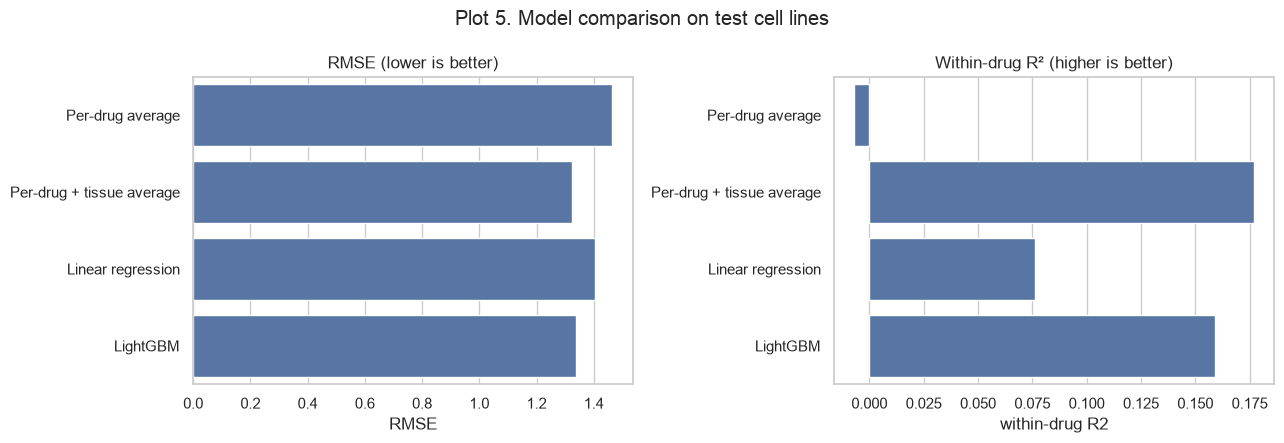

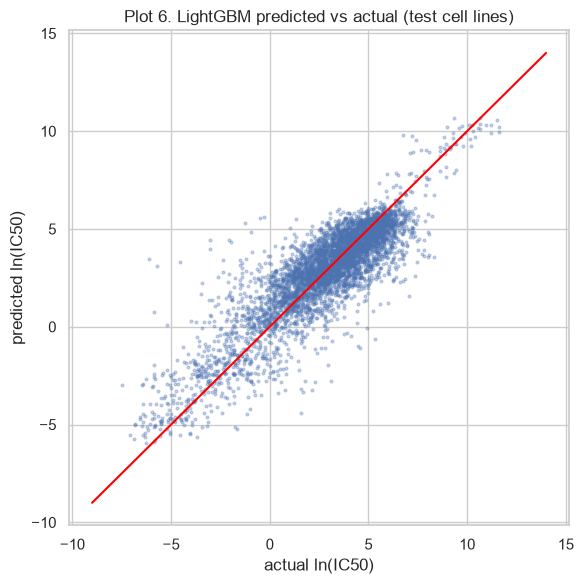

spread of actual vs predicted values (standard deviation): 2.75 2.41


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=results_table, x="RMSE", y="method", ax=axes[0])
axes[0].set_title("RMSE (lower is better)")
axes[0].set_ylabel("")
sns.barplot(data=results_table, x="within-drug R2", y="method", ax=axes[1])
axes[1].set_title("Within-drug R² (higher is better)")
axes[1].set_ylabel("")
fig.suptitle("Plot 5. Model comparison on test cell lines")
plt.tight_layout()
plt.savefig("figures/plot5_model_comparison.png", dpi=150)
plt.show()

# 5,000 random test points to keep the scatter plot readable
sample = np.random.RandomState(0).choice(len(y_test), 5000, replace=False)
plt.figure(figsize=(6, 6))
plt.scatter(y_test.values[sample], pred_lgbm[sample], s=4, alpha=0.3)
plt.plot([-9, 14], [-9, 14], color="red")  # perfect predictions
plt.xlabel("actual ln(IC50)")
plt.ylabel("predicted ln(IC50)")
plt.title("Plot 6. LightGBM predicted vs actual (test cell lines)")
plt.tight_layout()
plt.savefig("figures/plot6_predicted_vs_actual.png", dpi=150)
plt.show()

print("spread of actual vs predicted values (standard deviation):", round(float(y_test.std()), 2), round(float(pred_lgbm.std()), 2))

Most points follow the red line, but the predictions are pulled towards the middle (their spread is 2.41 against 2.75 for the actual values): very sensitive results (far left) tend to be predicted as less sensitive than they are, and very resistant ones as less resistant. Extreme responses are the hardest to predict.

## 13. Improving the model
The first LightGBM model came out slightly behind the per-drug + tissue average. We tried two changes:
- **Centering by drug**: subtract each drug's training average before fitting LightGBM and add it back afterwards, so the trees can focus on differences between cell lines instead of learning 295 drug averages.
- **Blending**: average the per-drug + tissue prediction with the LightGBM prediction (either version).

To choose between them without touching the test set, we compare them with 3-fold cross-validation inside the 766 training cell lines (again split by cell line). Only after choosing do we score the test set.

In [16]:
def make_features(fit_part, part):
    # drug and tissue as categorical columns, using only the categories seen in fit_part
    X = part[features].copy()
    for col in ["DRUG_ID", "tissue"]:
        categories = sorted(fit_part[col].unique())
        X[col] = pd.Categorical(X[col].where(X[col].isin(categories)), categories=categories)
    return X

def predict_all(fit_part, part):
    # every average and model below is fitted on fit_part only
    d_avg = fit_part.groupby("DRUG_ID")["LN_IC50"].mean()
    base = part["DRUG_ID"].map(d_avg).values
    dt_avg = fit_part.groupby(["DRUG_ID", "tissue"])["LN_IC50"].mean().rename("avg").reset_index()
    p_dt = part[["DRUG_ID", "tissue"]].merge(dt_avg, on=["DRUG_ID", "tissue"], how="left")["avg"]
    p_dt = p_dt.fillna(pd.Series(base)).values

    X_fit, X_part = make_features(fit_part, fit_part), make_features(fit_part, part)
    lgbm = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(X_fit, fit_part["LN_IC50"])
    p_lgbm = lgbm.predict(X_part)
    centered = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(X_fit, fit_part["LN_IC50"] - fit_part["DRUG_ID"].map(d_avg))
    p_centered = base + centered.predict(X_part)

    return {
        "Per-drug + tissue average": p_dt,
        "LightGBM": p_lgbm,
        "LightGBM (centered by drug)": p_centered,
        "Blend (tissue average + LightGBM)": 0.5 * p_dt + 0.5 * p_lgbm,
        "Blend (tissue average + centered LightGBM)": 0.5 * p_dt + 0.5 * p_centered,
    }

def within_drug_r2(part, pred):
    drug_mean = part.groupby("DRUG_ID")["LN_IC50"].transform("mean")
    return 1 - ((part["LN_IC50"] - pred) ** 2).sum() / ((part["LN_IC50"] - drug_mean) ** 2).sum()

# 3-fold cross-validation on the training cell lines only
cv_rows = []
folds = GroupKFold(n_splits=3).split(train, groups=train["SANGER_MODEL_ID"])
for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    for name, pred in predict_all(fit_part, val_part).items():
        rmse = np.sqrt(mean_squared_error(val_part["LN_IC50"], pred))
        cv_rows.append({"method": name, "fold": fold, "RMSE": rmse, "within-drug R2": within_drug_r2(val_part, pred)})

cv_table = pd.DataFrame(cv_rows).groupby("method", sort=False)[["RMSE", "within-drug R2"]].mean().round(3)
print("Cross-validation on training cell lines (average of 3 folds):")
print(cv_table.to_string())

FINAL = cv_table["within-drug R2"].idxmax()
print("\nchosen from cross-validation:", FINAL)

Cross-validation on training cell lines (average of 3 folds):
                                             RMSE  within-drug R2
method                                                           
Per-drug + tissue average                   1.324           0.185
LightGBM                                    1.349           0.154
LightGBM (centered by drug)                 1.335           0.172
Blend (tissue average + LightGBM)           1.315           0.197
Blend (tissue average + centered LightGBM)  1.310           0.202

chosen from cross-validation: Blend (tissue average + centered LightGBM)


In cross-validation the per-drug + tissue average scores a within-drug R² of 0.185. LightGBM on its own is behind it (0.154), and centering by drug helps (0.172) but still isn't enough. Blending is what makes the difference: the blend with the centered LightGBM is best (RMSE 1.310, within-drug R² 0.202), so that is the model we take forward as our **final model**. The 50/50 weight was fixed in advance rather than tuned.

### Test results for all methods

In [17]:
test_preds = predict_all(train, test)
assert np.allclose(test_preds["LightGBM"], pred_lgbm)  # same model as section 11

for name in ["LightGBM (centered by drug)", "Blend (tissue average + LightGBM)",
             "Blend (tissue average + centered LightGBM)"]:
    results.append(score(name, test_preds[name]))
pred_final = test_preds[FINAL]

results_table = pd.DataFrame(results)
results_table

,method,RMSE,R2,within-drug R2
0,Per-drug average,1.464,0.716,-0.007
1,Per-drug + tissue average,1.324,0.768,0.177
2,Linear regression,1.403,0.739,0.076
3,LightGBM,1.339,0.763,0.159
4,LightGBM (centered by drug),1.318,0.770,0.185
5,Blend (tissue average + LightGBM),1.310,0.773,0.194
6,Blend (tissue average + centered LightGBM),1.302,0.775,0.204


On the 192 test cell lines the final model reaches RMSE 1.302 and within-drug R² 0.204, against 1.324 and 0.177 for the per-drug + tissue average. The order of the methods on the test set is the same as in cross-validation, which suggests the choice wasn't a lucky one. The improvement is real but modest: the final model explains about 20% of the differences between cell lines for the same drug, so most of that variation is still unexplained.

### What do the gene features add?
We refit the centered LightGBM without the 84 gene features (drug and tissue only) and compare, overall and for the two example drugs from Plot 4. This is a check on the test set, not a way of choosing the model.

In [18]:
d_avg = train.groupby("DRUG_ID")["LN_IC50"].mean()
base_test = test["DRUG_ID"].map(d_avg).values
no_genes = lgb.LGBMRegressor(random_state=42, verbose=-1)
no_genes.fit(X_train[["DRUG_ID", "tissue"]], train["LN_IC50"] - train["DRUG_ID"].map(d_avg))
pred_no_genes = base_test + no_genes.predict(X_test[["DRUG_ID", "tissue"]])
pred_with_genes = test_preds["LightGBM (centered by drug)"]

print("all drugs - within-drug R2 without genes:", score("", pred_no_genes)["within-drug R2"],
      "| with genes:", score("", pred_with_genes)["within-drug R2"])

for drug_id, name in [(1373, "Dabrafenib"), (1047, "Nutlin-3a (-)")]:
    rows = (test["DRUG_ID"] == drug_id).values
    actual = y_test.values[rows]
    total = ((actual - actual.mean()) ** 2).sum()
    r2_without = 1 - ((actual - pred_no_genes[rows]) ** 2).sum() / total
    r2_with = 1 - ((actual - pred_with_genes[rows]) ** 2).sum() / total
    print(f"{name}: R2 without genes {r2_without:.3f} | with genes {r2_with:.3f}")

all drugs - within-drug R2 without genes: 0.184 | with genes: 0.185
Dabrafenib: R2 without genes 0.326 | with genes 0.359
Nutlin-3a (-): R2 without genes 0.283 | with genes 0.324


This is the most sobering result in the notebook. Across all drugs, the 84 gene features add almost nothing: within-drug R² is 0.184 without them and 0.185 with them. Nearly all of what the model knows about a cell line comes from its tissue.

The genes do help for specific drugs where a known target is involved: for Dabrafenib R² goes from 0.326 to 0.359, and for Nutlin-3a from 0.283 to 0.324. So mutation features matter for some drugs, but 0/1 mutation flags for 84 genes are not enough to improve predictions in general.

This also says something about where the final model's advantage over the per-drug + tissue average comes from. On this test split, the centered LightGBM *without* any gene features already scores 0.184, above the per-drug + tissue average (0.177), so here most of the gain comes from how LightGBM combines drug and tissue information rather than from the mutations. Section 18 checks this on 10 more splits, where the genes do add a small amount.


## 14. Missed cases and false alarms
For a researcher choosing which drugs to test, two mistakes matter in different ways. A **missed case** means skipping a drug the cell line would have responded to. A **false alarm** means spending lab time on a drug that doesn't work.

ln(IC50) is a continuous number, so we call a result **sensitive** if it falls in the lowest 20% of ln(IC50) values for that drug. The cutoffs are calculated on the training set only.

not sensitive results: 37834


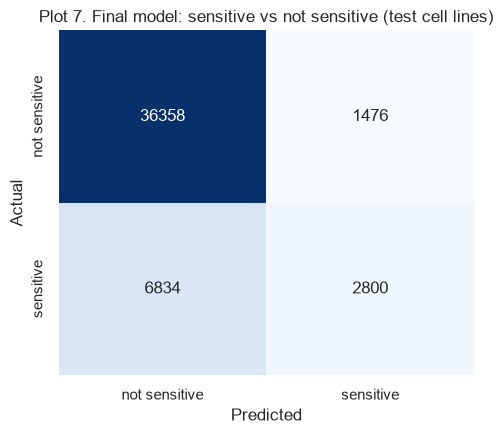

,method,sensitive results,found,missed,false alarms,found (%),false alarm rate (%)
0,Per-drug average,9634,0,9634,0,0.0,0.0
1,Per-drug + tissue average,9634,2824,6810,1566,29.3,4.1
2,LightGBM,9634,2503,7131,1594,26.0,4.2
3,Blend (tissue average + centered LightGBM),9634,2800,6834,1476,29.1,3.9


In [19]:
cutoff = train.groupby("DRUG_ID")["LN_IC50"].quantile(0.20)
test_cutoff = test["DRUG_ID"].map(cutoff).values
actual_sensitive = (y_test.values <= test_cutoff).astype(int)

def sensitivity_row(name, pred):
    predicted_sensitive = (np.asarray(pred) <= test_cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual_sensitive, predicted_sensitive, labels=[0, 1]).ravel()
    return {"method": name, "sensitive results": int(tp + fn), "found": int(tp), "missed": int(fn),
            "false alarms": int(fp), "found (%)": round(float(tp / (tp + fn) * 100), 1),
            "false alarm rate (%)": round(float(fp / (fp + tn) * 100), 1)}

methods = {"Per-drug average": pred_drug, "Per-drug + tissue average": pred_drug_tissue, "LightGBM": pred_lgbm}
methods[FINAL] = pred_final
sens_table = pd.DataFrame([sensitivity_row(name, pred) for name, pred in methods.items()])
print("not sensitive results:", int((actual_sensitive == 0).sum()))

final_sensitive = (pred_final <= test_cutoff).astype(int)
plt.figure(figsize=(5, 4.5))
sns.heatmap(confusion_matrix(actual_sensitive, final_sensitive), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["not sensitive", "sensitive"], yticklabels=["not sensitive", "sensitive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Plot 7. Final model: sensitive vs not sensitive (test cell lines)")
plt.tight_layout()
plt.savefig("figures/plot7_sensitivity_confusion_matrix.png", dpi=150)
plt.show()

sens_table

Of the 47,468 test results, 9,634 are sensitive by this definition and 37,834 are not. The per-drug average never predicts a value in a drug's lowest 20%, so it misses every sensitive result.

The final model finds 2,800 of the 9,634 sensitive results (29.1%) and misses 6,834, with 1,476 false alarms (3.9% of the not-sensitive results). That is fewer false alarms than the per-drug + tissue average (1,566) but about the same number of sensitive results found (2,824 for the average). In other words, **the model misses about 7 in 10 sensitive results**. It is cautious: when it does flag a result as sensitive it is usually right, but it should not be used to rule drugs out.

## 15. Results by sex and age group
The cell lines were derived from patients of different sexes and ages. Sex and age are not used as model features, but we check whether the final model works equally well for each group. Unknown values are kept as their own group.

    sex  test cell lines  RMSE  within-drug R2  sensitive found (%)  blood cancer lines
 Female               66 1.313           0.211                 24.6                   7
   Male              122 1.280           0.201                 31.7                  21
Unknown                4 1.690           0.189                 10.4                   0 

age group  test cell lines  RMSE  within-drug R2  sensitive found (%)  blood cancer lines
 under 18               23 1.178           0.421                 48.8                  10
    18-65              101 1.338           0.185                 27.0                  14
  over 65               22 1.243           0.149                  6.0                   0
  Unknown               46 1.310           0.142                 18.4                   4

sensitive found (%) without blood cancers, by sex: {'Female': 2.9, 'Male': 3.9, 'Unknown': 10.4}

sensitive found (%) without blood cancers, by age group: {'18-65': 2.8, 'Unknown': 3.8, 'over 65'

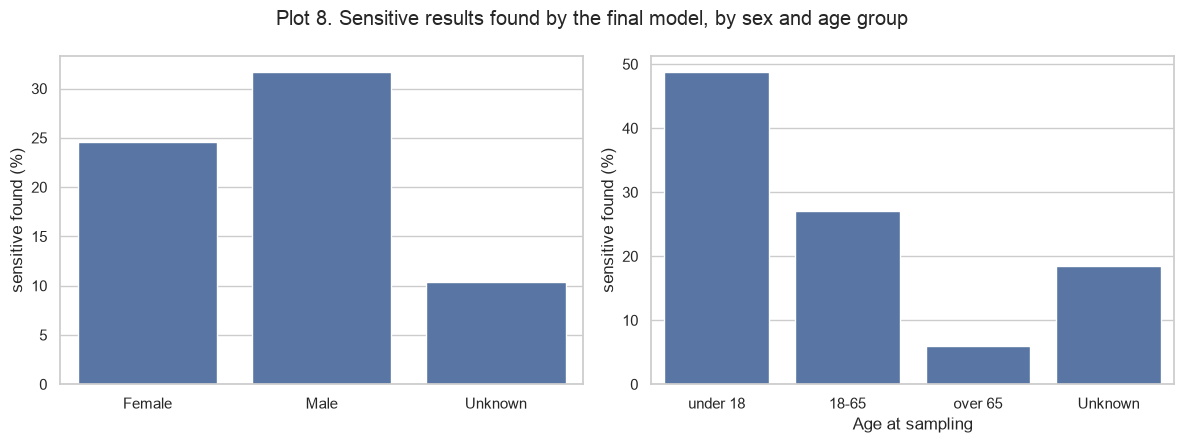

In [20]:
info = models.set_index("model_id")[["gender", "age_at_sampling"]]
check = test[["SANGER_MODEL_ID", "DRUG_ID", "DRUG_NAME", "tissue", "EGFR", "LN_IC50"]].copy()
check["sex"] = check["SANGER_MODEL_ID"].map(info["gender"]).fillna("Unknown")
age = check["SANGER_MODEL_ID"].map(info["age_at_sampling"])
check["age group"] = np.where(age.isna(), "Unknown", np.where(age < 18, "under 18", np.where(age <= 65, "18-65", "over 65")))
check["pred"] = pred_final
check["sq_error"] = (check["LN_IC50"] - check["pred"]) ** 2
check["sq_from_drug_mean"] = (check["LN_IC50"] - drug_mean_test) ** 2
check["actual_sensitive"] = actual_sensitive
check["found"] = actual_sensitive * final_sensitive

def group_table(column, order):
    rows = []
    for name in order:
        g = check[check[column] == name]
        lines = g.drop_duplicates("SANGER_MODEL_ID")
        rows.append({
            column: name,
            "test cell lines": len(lines),
            "RMSE": round(float(np.sqrt(g["sq_error"].mean())), 3),
            "within-drug R2": round(float(1 - g["sq_error"].sum() / g["sq_from_drug_mean"].sum()), 3),
            "sensitive found (%)": round(float(g["found"].sum() / g["actual_sensitive"].sum() * 100), 1),
            "blood cancer lines": int((lines["tissue"] == "Haematopoietic and Lymphoid").sum()),
        })
    return pd.DataFrame(rows)

sex_table = group_table("sex", ["Female", "Male", "Unknown"])
age_table = group_table("age group", ["under 18", "18-65", "over 65", "Unknown"])
print(sex_table.to_string(index=False), "\n")
print(age_table.to_string(index=False))

# the same check with blood cancers left out
solid = check[check["tissue"] != "Haematopoietic and Lymphoid"]
for column in ["sex", "age group"]:
    found = (solid.groupby(column)["found"].sum() / solid.groupby(column)["actual_sensitive"].sum() * 100).round(1)
    print(f"\nsensitive found (%) without blood cancers, by {column}:", found.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=sex_table, x="sex", y="sensitive found (%)", ax=axes[0])
axes[0].set_xlabel("")
sns.barplot(data=age_table, x="age group", y="sensitive found (%)", ax=axes[1])
axes[1].set_xlabel("Age at sampling")
fig.suptitle("Plot 8. Sensitive results found by the final model, by sex and age group")
plt.tight_layout()
plt.savefig("figures/plot8_fairness_audit.png", dpi=150)
plt.show()

The overall error is similar for female and male cell lines (RMSE 1.313 and 1.280), but the share of sensitive results found is not: 24.6% for female lines against 31.7% for male lines. The gap between age groups is much larger, from 48.8% for cell lines from donors under 18 down to 6.0% for donors over 65. The 4 cell lines with unknown sex are too few to say anything about.

These gaps follow the mix of cancer types in each group. Blood cancers make up 10 of the 23 under-18 test lines and none of the 22 over-65 lines; 21 of the 122 male lines and 7 of the 66 female lines. When blood cancers are left out, the model finds only 2.8% to 6.0% of sensitive results in every sex and age group (apart from the 4 unknown-sex lines), and the differences between groups mostly disappear.

So the model does not treat groups differently because of sex or age, but its results are still unequal in practice: it is mainly good at recognising that blood cancer cell lines are sensitive to many drugs, and for solid tumors it finds very few sensitive results for anyone.

## 16. Where the model fails
We look at the final model's results by tissue, by drug and for a rare mutation. Drugs are compared by within-drug R² rather than RMSE, because each drug has its own ln(IC50) scale.

tissues in the test set: 27 | tissues in the whole dataset: 28

Largest tissues in the test set:
                     tissue  test cell lines  train cell lines  RMSE  within-drug R2
                       Lung               39               149 1.319           0.077
Haematopoietic and Lymphoid               28               135 1.241           0.554
                     Breast               13                39 1.416           0.089
            Large Intestine               11                37 1.333           0.164
                     Kidney                9                24 1.618           0.073
                       Skin                9                48 1.228           0.216

Tissues with a single test cell line:
         tissue  test cell lines  train cell lines  RMSE  within-drug R2
         Testis                1                 1 1.537          -0.535
  Adrenal Gland                1                 0 1.259          -0.037
Small Intestine                1                 0

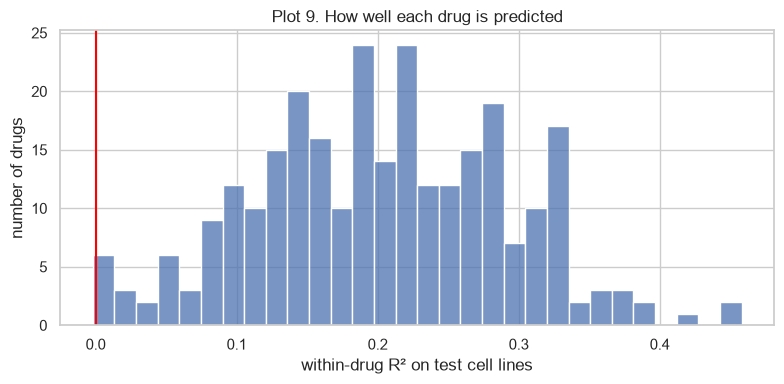

EGFR-mutant cell lines - train: 19 | test: 2

Gefitinib on test cell lines, by EGFR status (1 = mutated):
     LN_IC50        pred      
       count  mean count  mean
EGFR                          
0        188  3.03   188  3.16
1          2 -0.11     2  2.58


In [21]:
# by tissue
tissue_rows = []
for name, g in check.groupby("tissue"):
    tissue_rows.append({"tissue": name, "test cell lines": g["SANGER_MODEL_ID"].nunique(),
                        "train cell lines": train.loc[train["tissue"] == name, "SANGER_MODEL_ID"].nunique(),
                        "RMSE": round(float(np.sqrt(g["sq_error"].mean())), 3),
                        "within-drug R2": round(float(1 - g["sq_error"].sum() / g["sq_from_drug_mean"].sum()), 3)})
tissue_table = pd.DataFrame(tissue_rows).sort_values("test cell lines", ascending=False)
print("tissues in the test set:", len(tissue_table), "| tissues in the whole dataset:", data["tissue"].nunique())
print("\nLargest tissues in the test set:")
print(tissue_table.head(6).to_string(index=False))
print("\nTissues with a single test cell line:")
print(tissue_table[tissue_table["test cell lines"] == 1].to_string(index=False))

# by drug (drugs with at least 100 test results)
drug_rows = []
for drug_id, g in check.groupby("DRUG_ID"):
    if len(g) >= 100:
        total = ((g["LN_IC50"] - g["LN_IC50"].mean()) ** 2).sum()
        drug_rows.append({"drug": g["DRUG_NAME"].iloc[0], "DRUG_ID": drug_id, "results": len(g),
                          "within-drug R2": round(float(1 - g["sq_error"].sum() / total), 3)})
drug_table = pd.DataFrame(drug_rows).sort_values("within-drug R2", ascending=False)
print("\ndrugs compared:", len(drug_table), "| drugs where the model is no better than the drug's own average (R2 <= 0):",
      int((drug_table["within-drug R2"] <= 0).sum()))
print("\nBest predicted drugs:")
print(drug_table.head(5).to_string(index=False))
print("\nWorst predicted drugs:")
print(drug_table.tail(5).to_string(index=False))

plt.figure(figsize=(8, 4))
sns.histplot(drug_table["within-drug R2"], bins=30)
plt.axvline(0, color="red")
plt.xlabel("within-drug R² on test cell lines")
plt.ylabel("number of drugs")
plt.title("Plot 9. How well each drug is predicted")
plt.tight_layout()
plt.savefig("figures/plot9_failure_analysis_drugs.png", dpi=150)
plt.show()

# a rare mutation: EGFR and the EGFR inhibitor Gefitinib
print("EGFR-mutant cell lines - train:", int(train.drop_duplicates("SANGER_MODEL_ID")["EGFR"].sum()),
      "| test:", int(test.drop_duplicates("SANGER_MODEL_ID")["EGFR"].sum()))
gefitinib = check[check["DRUG_NAME"] == "Gefitinib"]
print("\nGefitinib on test cell lines, by EGFR status (1 = mutated):")
print(gefitinib.groupby("EGFR")[["LN_IC50", "pred"]].agg(["count", "mean"]).round(2).to_string())

**Tissue.** The model works much better for blood cancers (within-drug R² 0.554) than for the largest solid tumor groups: lung 0.077, breast 0.089, kidney 0.073. The six tissues with a single test cell line all have negative scores, meaning the model does worse than simply using each drug's average. Two of them (adrenal gland and small intestine) have no cell lines in the training set at all, and the others have between 1 and 5.

**Drug.** Among the 279 drugs with at least 100 test results, the best predicted are Venetoclax (0.458) and Temozolomide (0.444). At the other end the model adds nothing for drugs such as Methotrexate (0.003), and for one drug it is slightly worse than the drug's own average.

**A rare mutation.** EGFR is mutated in only 21 cell lines (19 in training, 2 in test). For the EGFR inhibitor Gefitinib, the 2 EGFR-mutant test lines are far more sensitive than the other 188 (mean ln(IC50) -0.11 against 3.03), but the model predicts 2.58 for them, close to its prediction of 3.16 for the rest. With two cell lines this is an example rather than a measurement, but it shows the kind of case the model misses: a strong effect that appears in too few training examples to be learned.

## 17. Gene toggles
For a researcher looking at a specific cell line and drug, we can ask how the final model's prediction changes when one gene is flipped (`0 -> 1` or `1 -> 0`) while tissue and all other genes stay the same.

Because each drug is tested at its own dose range, every prediction is shown alongside that drug's training-set average, its per-drug + tissue average, and its 20% sensitivity cutoff. **These toggles show what the model learned from correlations in the training data, not biological cause.** Because half of the final model is the per-drug + tissue average (which does not use genes), flipping a gene changes only the LightGBM half of the blend.

Gene toggle test on four held-out test cases:
cell line tissue          drug gene toggle  actual  drug avg  tissue avg  20% cutoff  pred before  pred after  change
 SK-MEL-3   Skin    Dabrafenib BRAF 1 -> 0    0.73      4.25        1.01        3.10         1.75        2.51    0.76
 SK-MEL-2   Skin    Dabrafenib BRAF 0 -> 1    5.46      4.25        1.01        3.10         2.48        1.72   -0.76
NCI-H1755   Lung Nutlin-3a (-) TP53 1 -> 0    5.40      4.42        5.07        2.99         5.21        4.88   -0.33
    PC-14   Lung     Gefitinib EGFR 1 -> 0   -1.40      3.18        3.34        2.41         3.24        3.40    0.16



Top 6 single-gene toggles for SK-MEL-3 (Skin) on Dabrafenib:
 gene toggle  pred before  pred after  change
 BRAF 1 -> 0         1.75        2.51    0.76
 KRAS 0 -> 1         1.75        2.06    0.31
  APC 0 -> 1         1.75        1.47   -0.28
CRTC1 0 -> 1         1.75        1.97    0.22
 MLH1 0 -> 1         1.75        1.96    0.21
 NBEA 0 -> 1         1.75        1.58   -0.18


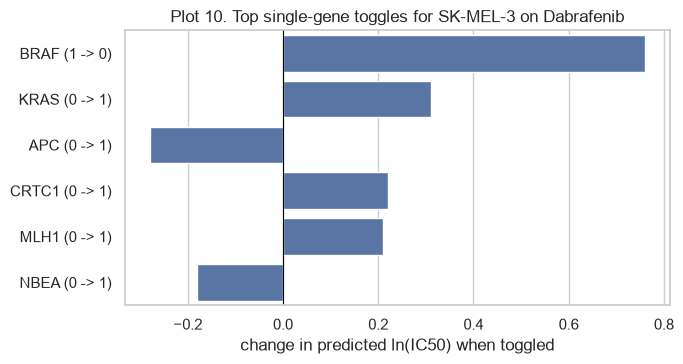

In [22]:
# fit the centered LightGBM model on the training set so we can query it on modified inputs
centered_model = lgb.LGBMRegressor(random_state=42, verbose=-1)
centered_model.fit(X_train, train["LN_IC50"] - train["DRUG_ID"].map(drug_avg))
drug_tissue_lookup = train.groupby(["DRUG_ID", "tissue"])["LN_IC50"].mean()

def predict_final(rows):
    # 50/50 blend of the per-drug + tissue average and the centered LightGBM prediction
    base = rows["DRUG_ID"].map(drug_avg).values
    p_dt = rows.set_index(["DRUG_ID", "tissue"]).index.map(drug_tissue_lookup).to_numpy(dtype=float)
    p_dt = np.where(np.isnan(p_dt), base, p_dt)
    p_centered = base + centered_model.predict(make_features(train, rows))
    return 0.5 * p_dt + 0.5 * p_centered

assert np.allclose(predict_final(test), pred_final)

def gene_toggle_row(model_id, drug_id, gene):
    # flip one gene (0 -> 1 or 1 -> 0) for a single test cell line and drug
    row = test[(test["SANGER_MODEL_ID"] == model_id) & (test["DRUG_ID"] == drug_id)].iloc[[0]].copy()
    orig_val = int(row[gene].iloc[0])
    pred_before = float(predict_final(row)[0])
    row[gene] = 1 - orig_val
    pred_after = float(predict_final(row)[0])
    tissue_name = row["tissue"].iloc[0]
    t_avg = drug_tissue_lookup.get((drug_id, tissue_name), drug_avg[drug_id])
    return {
        "cell line": row["CELL_LINE_NAME"].iloc[0],
        "tissue": tissue_name,
        "drug": row["DRUG_NAME"].iloc[0],
        "gene": gene,
        "toggle": f"{orig_val} -> {1 - orig_val}",
        "actual": round(float(row["LN_IC50"].iloc[0]), 2),
        "drug avg": round(float(drug_avg[drug_id]), 2),
        "tissue avg": round(float(t_avg), 2),
        "20% cutoff": round(float(cutoff[drug_id]), 2),
        "pred before": round(pred_before, 2),
        "pred after": round(pred_after, 2),
        "change": round(pred_after - pred_before, 2),
    }

cases = [
    ("SIDM01105", 1373, "BRAF"),  # SK-MEL-3 (Skin, BRAF=1) on Dabrafenib
    ("SIDM00082", 1373, "BRAF"),  # SK-MEL-2 (Skin, BRAF=0) on Dabrafenib
    ("SIDM00738", 1047, "TP53"),  # NCI-H1755 (Lung, TP53=1) on Nutlin-3a (-)
    ("SIDM00237", 1010, "EGFR"),  # PC-14 (Lung, EGFR=1) on Gefitinib
]
toggle_table = pd.DataFrame([gene_toggle_row(*c) for c in cases])
print("Gene toggle test on four held-out test cases:")
print(toggle_table.to_string(index=False))

def top_gene_toggles(model_id, drug_id, n=6):
    # flip each of the 84 genes one at a time and rank by absolute change in predicted ln(IC50)
    row = test[(test["SANGER_MODEL_ID"] == model_id) & (test["DRUG_ID"] == drug_id)].iloc[[0]].copy()
    pred_before = float(predict_final(row)[0])
    shifts = []
    for g in GENES:
        modified = row.copy()
        orig_val = int(modified[g].iloc[0])
        modified[g] = 1 - orig_val
        pred_after = float(predict_final(modified)[0])
        shifts.append({
            "gene": g,
            "toggle": f"{orig_val} -> {1 - orig_val}",
            "pred before": round(pred_before, 2),
            "pred after": round(pred_after, 2),
            "change": round(pred_after - pred_before, 2),
        })
    return pd.DataFrame(shifts).sort_values("change", key=lambda s: s.abs(), ascending=False).head(n)

top_skmel3 = top_gene_toggles("SIDM01105", 1373, n=6)
print("\nTop 6 single-gene toggles for SK-MEL-3 (Skin) on Dabrafenib:")
print(top_skmel3.to_string(index=False))

plt.figure(figsize=(7, 3.8))
plot_df = top_skmel3.assign(label=top_skmel3["gene"] + " (" + top_skmel3["toggle"] + ")")
sns.barplot(data=plot_df, x="change", y="label")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("change in predicted ln(IC50) when toggled")
plt.ylabel("")
plt.title("Plot 10. Top single-gene toggles for SK-MEL-3 on Dabrafenib")
plt.tight_layout()
plt.savefig("figures/plot10_gene_toggles.png", dpi=150)
plt.show()

### What happens when we flip a mutation?
The table above shows how the final model's prediction moves when one gene is flipped on four held-out test cases. These shifts show what the model learned from the training data; they are not evidence that a mutation causes the response.

- **Dabrafenib and BRAF (skin).** For `SK-MEL-3` (BRAF mutated), the model predicts 1.75 (lab result 0.73). Switching BRAF off (1 -> 0) raises the prediction to 2.51 (+0.76, towards resistance), which fits what Dabrafenib does: it targets mutated BRAF. For `SK-MEL-2` (BRAF not mutated), switching BRAF on lowers the prediction from 2.48 to 1.72 (-0.76).
- **A false alarm.** Without a BRAF mutation, `SK-MEL-2` is still predicted at 2.48, below the 20% sensitivity cutoff of 3.10, so it is flagged as sensitive; the lab result was 5.46 (resistant). Half of the final model is the per-drug + tissue average, which is 1.01 for Dabrafenib in skin, and this pulls the prediction towards sensitive whatever the mutations are.
- **Nutlin-3a and TP53 (lung).** For `NCI-H1755` (TP53 mutated), switching TP53 off lowers the prediction from 5.21 to 4.88 (-0.33, towards sensitive). The direction matches Plot 4, but the shift is much smaller than the 2.40 difference between the median responses of TP53-mutant and non-mutant cell lines.
- **Gefitinib and EGFR (lung).** For `PC-14`, switching EGFR off changes the prediction by only +0.16 (3.24 to 3.40). With only 19 EGFR-mutant cell lines in training, the model has learned little about this gene.
- **Other genes (Plot 10).** For `SK-MEL-3` on Dabrafenib, BRAF gives the largest shift (+0.76), but flipping genes such as KRAS (+0.31) or APC (-0.28) also moves the prediction. These are patterns the model picked up from the training data and should not be read as biological effects.

## 18. How stable is the result?
Our test result comes from one split of the cell lines (random seed 42), with only 192 test cell lines. To check that the final model's gain over the per-drug + tissue average isn't luck of that split, we do two checks:
- **Repeated splits.** Split all 958 cell lines again 10 times with different random seeds (each time 20% of cell lines held out), refit everything on each training part, and compare the methods on each test part. We also refit the final model without gene features each time.
- **Bootstrap.** On our original 192 test cell lines, resample the cell lines with replacement 2,000 times and recompute the gain in within-drug R² each time. This gives a range for the gain.

The method (50/50 blend) was already fixed before these checks; nothing is tuned here.


In [23]:
if RUN_STABILITY_CHECKS:
    # repeat the comparison on 10 new random splits of all 958 cell lines
    split_rows = []
    splits = GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=0).split(data, groups=data["SANGER_MODEL_ID"])
    for split, (tr_idx, te_idx) in enumerate(splits, start=1):
        tr, te = data.iloc[tr_idx], data.iloc[te_idx]
        preds = predict_all(tr, te)  # every average and model is fitted on tr only

        # the same 50/50 blend, but its LightGBM half gets only drug and tissue (no genes)
        tr_drug_avg = tr.groupby("DRUG_ID")["LN_IC50"].mean()
        te_base = te["DRUG_ID"].map(tr_drug_avg).values
        no_gene_model = lgb.LGBMRegressor(random_state=42, verbose=-1)
        no_gene_model.fit(make_features(tr, tr)[["DRUG_ID", "tissue"]], tr["LN_IC50"] - tr["DRUG_ID"].map(tr_drug_avg))
        blend_no_genes = 0.5 * preds["Per-drug + tissue average"] + 0.5 * (te_base + no_gene_model.predict(make_features(tr, te)[["DRUG_ID", "tissue"]]))

        split_rows.append({
            "split": split,
            "per-drug + tissue average": within_drug_r2(te, preds["Per-drug + tissue average"]),
            "final model": within_drug_r2(te, preds[FINAL]),
            "final model without genes": within_drug_r2(te, blend_no_genes),
        })

    split_table = pd.DataFrame(split_rows).round(3)
    split_table["gain over baseline"] = split_table["final model"] - split_table["per-drug + tissue average"]
    print("Within-drug R2 on 10 repeated splits:")
    print(split_table.to_string(index=False))
    print("\naverage:", split_table.drop(columns="split").mean().round(3).to_dict())
    print("lowest / highest final model:", split_table["final model"].min(), "/", split_table["final model"].max())
    print("splits where the final model beats the per-drug + tissue average:", (split_table["gain over baseline"] > 0).sum(), "of 10")

    # bootstrap the 192 original test cell lines
    errors = pd.DataFrame({
        "cell line": test["SANGER_MODEL_ID"].values,
        "baseline": (y_test.values - pred_drug_tissue) ** 2,
        "final": (y_test.values - pred_final) ** 2,
        "total": (y_test.values - drug_mean_test.values) ** 2,
    }).groupby("cell line").sum()  # squared errors added up per cell line

    rng = np.random.default_rng(42)
    gains = []
    for _ in range(2000):
        sample = errors.iloc[rng.integers(0, len(errors), len(errors))]  # 192 cell lines drawn with replacement
        gains.append((sample["baseline"].sum() - sample["final"].sum()) / sample["total"].sum())
    gains = np.array(gains)

    print("\nBootstrap on the original test set:")
    print("gain in within-drug R2:", round(float((errors["baseline"].sum() - errors["final"].sum()) / errors["total"].sum()), 3))
    print("95% range of the gain:", np.percentile(gains, [2.5, 97.5]).round(3))
    print("test cell lines where the final model has lower error than the baseline:", int((errors["final"] < errors["baseline"]).sum()), "of", len(errors))
else:
    print("Skipped (RUN_STABILITY_CHECKS = False). The results from our full run are described below.")


Within-drug R2 on 10 repeated splits:
 split  per-drug + tissue average  final model  final model without genes  gain over baseline
     1                      0.227        0.238                      0.235               0.011
     2                      0.201        0.213                      0.208               0.012
     3                      0.175        0.187                      0.182               0.012
     4                      0.209        0.230                      0.218               0.021
     5                      0.205        0.215                      0.212               0.010
     6                      0.201        0.226                      0.210               0.025
     7                      0.221        0.245                      0.230               0.024
     8                      0.180        0.187                      0.190               0.007
     9                      0.160        0.179                      0.169               0.019
    10                

**Repeated splits.** The final model beats the per-drug + tissue average on all 10 splits. On average its within-drug R² is 0.212 against 0.196, a gain of 0.016 (between 0.007 and 0.025 depending on the split). Our original split's gain (0.027) is at the lucky end of that range, so **0.016 is the more realistic size of the improvement**. The final model itself ranges from 0.179 to 0.245 depending on which cell lines end up in the test set, which shows how much a single 192-line test set can move the score.

**What the genes add.** The same blend without gene features averages 0.204. So of the 0.016 gain, about half (0.008) comes from LightGBM combining drug and tissue information and about half (0.008) from the 84 gene features. The genes help on 9 of the 10 splits. On our original split they added almost nothing (Section 13), so that split understated them.

**Bootstrap.** On the original 192 test cell lines the gain is 0.027, with a 95% range of 0.012 to 0.044. The range stays above zero, so the improvement is unlikely to be chance. But it is not an improvement for every cell line: the final model has lower error than the baseline for 117 of the 192.

In short, the improvement over the simple baseline is real and repeatable, but small.


## 19. Finding more sensitive cases
Section 14 showed the final model misses about 7 in 10 sensitive results. One reason is that its predictions are pulled towards the middle (Section 12), so they rarely fall below the strict 20% cutoff. A researcher looking for drugs to test may prefer to see more candidates, even if some turn out to be false alarms.

So we keep the definition of a sensitive result the same (lowest 20% for each drug) but **flag** a result as likely sensitive when its prediction falls below a looser cutoff: the drug's 25%, 30%, ... or 50% level in the training data. We fixed the rule for choosing the cutoff before looking at any result: **use the loosest cutoff whose false alarm rate stays at or below 10% in cross-validation on the training cell lines.** Only then do we apply it to the test set.


In [24]:
flag_levels = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
cv_flag_rows = []
cv_parts = []  # out-of-fold predictions, reused for per-drug confidence in Section 20
for fit_idx, val_idx in GroupKFold(n_splits=3).split(train, groups=train["SANGER_MODEL_ID"]):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    pred = predict_all(fit_part, val_part)[FINAL]
    cv_parts.append(pd.DataFrame({"DRUG_ID": val_part["DRUG_ID"].values,
                                  "actual": val_part["LN_IC50"].values, "pred": pred}))

    # "sensitive" keeps its definition (lowest 20%); only the flagging cutoff changes
    sensitive_cut = val_part["DRUG_ID"].map(fit_part.groupby("DRUG_ID")["LN_IC50"].quantile(0.20)).values
    actual = val_part["LN_IC50"].values <= sensitive_cut
    for level in flag_levels:
        flag_cut = val_part["DRUG_ID"].map(fit_part.groupby("DRUG_ID")["LN_IC50"].quantile(level)).values
        flagged = pred <= flag_cut
        cv_flag_rows.append({"flag level": level,
                             "found (%)": 100 * (flagged & actual).sum() / actual.sum(),
                             "false alarm rate (%)": 100 * (flagged & ~actual).sum() / (~actual).sum()})

cv_flags = pd.DataFrame(cv_flag_rows).groupby("flag level").mean().round(1)
print("Cross-validation on training cell lines (average of 3 folds):")
print(cv_flags.to_string())
FLAG_LEVEL = cv_flags[cv_flags["false alarm rate (%)"] <= 10].index.max()
print("\nchosen flag level:", FLAG_LEVEL)

flag_cutoff = train.groupby("DRUG_ID")["LN_IC50"].quantile(FLAG_LEVEL)
actual = actual_sensitive == 1

def flag_row(name, pred, level_cutoff):
    flagged = np.asarray(pred) <= test["DRUG_ID"].map(level_cutoff).values
    return {"method": name, "found": int((flagged & actual).sum()), "missed": int((~flagged & actual).sum()),
            "false alarms": int((flagged & ~actual).sum()),
            "found (%)": round(100 * (flagged & actual).sum() / actual.sum(), 1),
            "false alarm rate (%)": round(100 * (flagged & ~actual).sum() / (~actual).sum(), 1),
            "flags that are right (%)": round(100 * (flagged & actual).sum() / flagged.sum(), 1)}

flag_table = pd.DataFrame([
    flag_row("Per-drug + tissue average, 20% cutoff", pred_drug_tissue, cutoff),
    flag_row("Final model, 20% cutoff", pred_final, cutoff),
    flag_row(f"Per-drug + tissue average, {FLAG_LEVEL:.0%} cutoff", pred_drug_tissue, flag_cutoff),
    flag_row(f"Final model, {FLAG_LEVEL:.0%} cutoff", pred_final, flag_cutoff),
])
print("\nTest cell lines (", int(actual.sum()), "sensitive results ):")
flag_table


Cross-validation on training cell lines (average of 3 folds):
            found (%)  false alarm rate (%)
flag level                                 
0.20             30.3                   5.7
0.25             39.8                   8.3
0.30             45.3                  10.5
0.35             50.1                  13.3
0.40             55.1                  17.3
0.45             60.7                  23.3
0.50             67.8                  32.6

chosen flag level: 0.25

Test cell lines ( 9634 sensitive results ):


,method,found,missed,false alarms,found (%),false alarm rate (%),flags that are right (%)
0,"Per-drug + tissue average, 20% cutoff",2824,6810,1566,29.3,4.1,64.3
1,"Final model, 20% cutoff",2800,6834,1476,29.1,3.9,65.5
2,"Per-drug + tissue average, 25% cutoff",3641,5993,2334,37.8,6.2,60.9
3,"Final model, 25% cutoff",3589,6045,2166,37.3,5.7,62.4


In cross-validation, loosening the cutoff finds more sensitive results but also raises false alarms. The 25% level keeps false alarms at 8.3% (finding 39.8%), while 30% already goes over our 10% limit (10.5%), so **25% is the level we use**.

On the 192 test cell lines, flagging at the 25% level finds **3,589 of 9,634 sensitive results (37.3%)** instead of 2,800 (29.1%), so about 790 more sensitive results are found. The price is more false alarms: 2,166 (5.7% of not-sensitive results) instead of 1,476 (3.9%). Of all the results the final model flags, 62.4% are truly sensitive (65.5% with the strict cutoff).

To be honest about where this comes from: the per-drug + tissue average gains just as much from the looser cutoff (37.8% found, 6.2% false alarms). So this is a **better trade-off for a researcher who wants more candidates, not a better model**. The final model still has fewer false alarms than the average at the same cutoff (2,166 vs 2,334), and it still misses about 6 in 10 sensitive results.


## 20. Drug shortlist
A researcher's real question is which drugs to test first for a given cell line. Sentinel predicts every drug for the cell line, converts each prediction to a **percentile within that drug's own training results**, and ranks the drugs. A percentile of 5 means the cell line is predicted to respond better than 95% of screened cell lines to that drug. Percentiles are used because each drug is tested at its own doses, so raw ln(IC50) values cannot be compared across drugs.

Each drug also gets a **confidence** level based on how well the model predicted that drug in cross-validation on the training cell lines: High (within-drug R² ≥ 0.30), Medium (0.15 to 0.30) or Low (below 0.15). These bands were fixed before looking at any shortlist.

To test the shortlist honestly, we rank each test cell line's tested drugs and check how many of its top 10 were truly sensitive (lowest 20% for that drug).


In [25]:
DRUGS = sorted(drug_avg.index)
drug_info = data.drop_duplicates("DRUG_ID").set_index("DRUG_ID")[["DRUG_NAME", "PUTATIVE_TARGET"]].fillna("not listed")
names = drug_info["DRUG_NAME"]
# a few drugs were screened under two IDs; show the ID only for those
drug_info["label"] = names.where(~names.duplicated(keep=False), names + " (" + names.index.astype(str) + ")")
train_sorted = {d: np.sort(v.values) for d, v in train.groupby("DRUG_ID")["LN_IC50"]}

def drug_percentile(drug_ids, preds):
    return np.array([100 * np.searchsorted(train_sorted[d], p) / len(train_sorted[d])
                     for d, p in zip(drug_ids, preds)])

cv_pred = pd.concat(cv_parts)
cv_pred["sq_err"] = (cv_pred["actual"] - cv_pred["pred"]) ** 2
cv_pred["sq_dev"] = (cv_pred["actual"] - cv_pred.groupby("DRUG_ID")["actual"].transform("mean")) ** 2
sums = cv_pred.groupby("DRUG_ID")[["sq_err", "sq_dev"]].sum()
drug_r2 = 1 - sums["sq_err"] / sums["sq_dev"]
confidence = pd.cut(drug_r2, [-np.inf, 0.15, 0.30, np.inf], labels=["Low", "Medium", "High"], right=False).astype(str)
print("drugs by confidence:", confidence.value_counts().to_dict())

# facts about the training cell lines, used to warn about inputs the model knows little about
train_lines = train.drop_duplicates("SANGER_MODEL_ID")
lines_per_tissue = train_lines["tissue"].value_counts()
lines_per_gene = train_lines[GENES].sum()
max_genes = int(train_lines[GENES].sum(axis=1).max())

def short_list(genes, n=5):
    # "A, B, C, D, E and 3 more" keeps long gene lists readable
    return ", ".join(genes[:n]) + (f" and {len(genes) - n} more" if len(genes) > n else "")

def input_warnings(tissue, mutated_genes):
    notes = []
    n_tissue = int(lines_per_tissue.get(tissue, 0))
    if n_tissue == 0:
        notes.append(f"No training cell lines come from {tissue}, so the model can only use each drug's average and the gene features.")
    elif n_tissue < 10:
        notes.append(f"Only {n_tissue} training cell line(s) come from {tissue}, so this shortlist is unreliable.")
    rare = [g for g in mutated_genes if lines_per_gene[g] < 20]
    if rare:
        notes.append(f"Fewer than 20 training cell lines have a mutation in {short_list(rare)}, so the model has learned little about these mutations.")
    tissue_lines = train_lines[train_lines["tissue"] == tissue]
    unseen = [g for g in mutated_genes if tissue_lines[g].sum() == 0]
    if unseen and n_tissue > 0:
        notes.append(f"No {tissue} training cell line has a mutation in {short_list(unseen)}.")
    if len(mutated_genes) > max_genes:
        notes.append(f"{len(mutated_genes)} mutated genes is more than any training cell line has ({max_genes}).")
    return notes

def make_profile(tissue, mutated_genes, drug_ids):
    profile = pd.DataFrame({"DRUG_ID": drug_ids, "tissue": tissue})
    for gene in GENES:
        profile[gene] = int(gene in mutated_genes)
    return profile

def rank_drugs(pred, top=10):
    # turn one prediction per drug (in DRUGS order) into a ranked table
    table = pd.DataFrame({
        "DRUG_ID": DRUGS,
        "name": drug_info.loc[DRUGS, "DRUG_NAME"].values,
        "Drug": drug_info.loc[DRUGS, "label"].values,
        "Target": drug_info.loc[DRUGS, "PUTATIVE_TARGET"].values,
        "Percentile": drug_percentile(DRUGS, pred),
        # flagged when the prediction is in the drug's lowest FLAG_LEVEL share (Section 19, rechecked in Section 22)
        "Predicted sensitive": np.where(pred <= flag_cutoff.reindex(DRUGS).values, "Yes", "No"),
        "Confidence": confidence.reindex(DRUGS).values,
    })
    # sort before rounding so that ties keep the real order
    table = table.sort_values("Percentile", kind="stable")
    # a drug screened under two IDs is shown once, using its better-ranked ID
    table = table.drop_duplicates("name").drop(columns="name")
    table = table.head(top).reset_index(drop=True)
    table["Percentile"] = table["Percentile"].round().astype(int)
    table.insert(0, "Rank", range(1, len(table) + 1))
    return table

def shortlist(tissue, mutated_genes, top=10):
    return rank_drugs(predict_final(make_profile(tissue, mutated_genes, DRUGS)), top)

def gene_effects(tissue, mutated_genes, drug_id, top=5):
    base = make_profile(tissue, mutated_genes, [drug_id])
    flipped = pd.concat([base] * len(GENES), ignore_index=True)
    for i, gene in enumerate(GENES):
        flipped.loc[i, gene] = 1 - flipped.loc[i, gene]
    before = int(round(drug_percentile([drug_id], predict_final(base))[0]))
    after = drug_percentile([drug_id] * len(GENES), predict_final(flipped)).round().astype(int)
    table = pd.DataFrame({
        "Gene": GENES,
        "Change": ["mutated → not mutated" if g in mutated_genes else "not mutated → mutated" for g in GENES],
        "Percentile after": after,
        "Shift": after - before,
    })
    table = table[table["Shift"] != 0]  # leave out genes that move the percentile by less than 1
    table["Effect"] = np.where(table["Shift"] < 0, "more sensitive", "less sensitive")
    table = table.sort_values("Shift", key=lambda s: s.abs(), ascending=False, kind="stable")
    return table.head(top).reset_index(drop=True)

def test_line_profile(name):
    row = test[test["CELL_LINE_NAME"] == name].iloc[0]
    return row["tissue"], [g for g in GENES if row[g] == 1]

def add_lab_result(table, name):
    measured = test[test["CELL_LINE_NAME"] == name].set_index("DRUG_ID")["LN_IC50"]
    result, lab_percentile = [], []
    for drug_id in table["DRUG_ID"]:
        # if this ID wasn't tested on the line, use the same drug's other ID when that one was
        same_drug = drug_info.index[drug_info["DRUG_NAME"] == drug_info.loc[drug_id, "DRUG_NAME"]]
        tested = [d for d in [drug_id] + list(same_drug) if d in measured.index]
        if not tested:
            result.append("not tested")
            lab_percentile.append("")
        else:
            d = tested[0]
            result.append("sensitive" if measured[d] <= cutoff[d] else "not sensitive")  # lowest 20%
            lab_percentile.append(str(int(round(drug_percentile([d], [measured[d]])[0]))))
    return table.assign(**{"Lab result": result, "Lab percentile": lab_percentile})

# Top-10 check on the test cell lines, using only drugs each line was actually tested with
ranked = pd.DataFrame({
    "cell line": test["SANGER_MODEL_ID"].values,
    "sensitive": actual_sensitive,
    "Final model": drug_percentile(test["DRUG_ID"], pred_final),
    "Per-drug + tissue average": drug_percentile(test["DRUG_ID"], pred_drug_tissue),
})
top10_rows = []
for method in ["Final model", "Per-drug + tissue average"]:
    top10 = ranked.sort_values(method, kind="stable").groupby("cell line").head(10)
    per_line = top10.groupby("cell line")["sensitive"].mean()
    top10_rows.append({"method": method, "truly sensitive in top 10 (%)": round(100 * per_line.mean(), 1)})
top10_rows.append({"method": "Random 10 drugs", "truly sensitive in top 10 (%)": round(100 * ranked["sensitive"].mean(), 1)})
pd.DataFrame(top10_rows)


drugs by confidence: {'Medium': 165, 'Low': 98, 'High': 32}


,method,truly sensitive in top 10 (%)
0,Final model,44.3
1,Per-drug + tissue average,41.6
2,Random 10 drugs,20.3


SK-MEL-3 | Skin | mutated: TP53, BRAF, ZFHX3


,Rank,Drug,Target,Percentile,Predicted sensitive,Confidence,Lab result,Lab percentile
0,1,PLX-4720,BRAF,8,Yes,Medium,sensitive,6
1,2,Dabrafenib,BRAF,8,Yes,High,sensitive,4
2,3,Selumetinib (1062),"MEK1, MEK2",10,Yes,Medium,sensitive,15
3,4,ERK_2440,"ERK1,ERK2",11,Yes,Low,not tested,
4,5,Refametinib,"MEK1, MEK2",12,Yes,Medium,not sensitive,32
5,6,ERK_6604,"ERK1,ERK2",12,Yes,Medium,not tested,
6,7,Trametinib,"MEK1, MEK2",12,Yes,Medium,not sensitive,32
7,8,SCH772984,"ERK1, ERK2",12,Yes,Medium,not sensitive,21
8,9,PD0325901,"MEK1, MEK2",12,Yes,Medium,not sensitive,36
9,10,SB590885,BRAF,13,Yes,Medium,sensitive,10


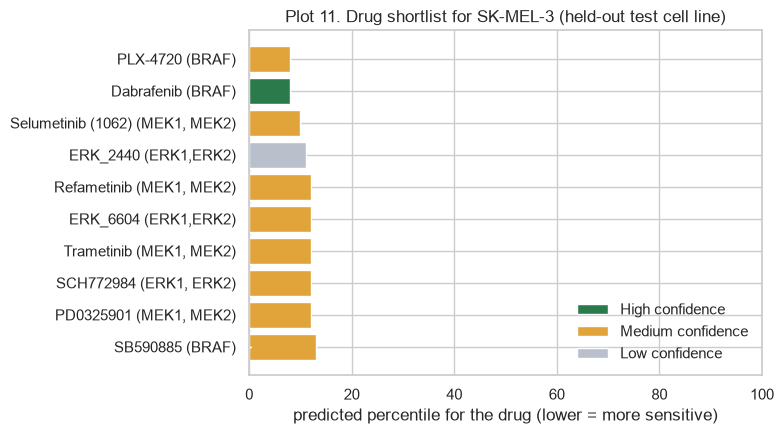

Genes that move PLX-4720 most for SK-MEL-3:


,Gene,Change,Percentile after,Shift,Effect
0,BRAF,mutated → not mutated,16,8,less sensitive
1,KRAS,not mutated → mutated,11,3,less sensitive
2,CRTC1,not mutated → mutated,11,3,less sensitive
3,KMT2D,not mutated → mutated,10,2,less sensitive
4,RB1,not mutated → mutated,10,2,less sensitive


In [26]:
def plot_shortlist(table, title):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    colors = table["Confidence"].map({"High": "#2b7a4b", "Medium": "#e0a43a", "Low": "#b9c0cc"})
    labels = table["Drug"] + " (" + table["Target"].str.slice(0, 22) + ")"
    ax.barh(labels[::-1], table["Percentile"][::-1], color=colors[::-1])
    ax.set_xlim(0, 100)
    ax.set_xlabel("predicted percentile for the drug (lower = more sensitive)")
    ax.set_title(title)
    for level, color in [("High", "#2b7a4b"), ("Medium", "#e0a43a"), ("Low", "#b9c0cc")]:
        ax.bar(0, 0, color=color, label=f"{level} confidence")
    ax.legend(loc="lower right", frameon=False)
    fig.tight_layout()
    return fig

tissue_name, genes = test_line_profile("SK-MEL-3")
print("SK-MEL-3 |", tissue_name, "| mutated:", ", ".join(genes))
example = add_lab_result(shortlist(tissue_name, genes), "SK-MEL-3")
display(example.drop(columns="DRUG_ID"))

fig = plot_shortlist(example, "Plot 11. Drug shortlist for SK-MEL-3 (held-out test cell line)")
fig.savefig("figures/plot11_drug_shortlist.png", dpi=150)
plt.show()

top_drug = example.loc[0, "DRUG_ID"]
print("Genes that move", example.loc[0, "Drug"], "most for SK-MEL-3:")
gene_effects(tissue_name, genes, top_drug)


Across the 192 test cell lines, **44.3% of the drugs in Sentinel's top 10 were truly sensitive**, against 41.6% for a shortlist ranked by the per-drug + tissue average and 20.3% for 10 drugs picked at random. So a Sentinel shortlist is about twice as useful as testing drugs at random, and slightly better than the simple average. Of the 295 drugs, 32 have High confidence, 165 Medium and 98 Low.

For SK-MEL-3, a BRAF-mutant melanoma line, the top two drugs are the BRAF inhibitors PLX-4720 and Dabrafenib, and both were sensitive in the lab. The rest of the list is made up of MEK and ERK inhibitors, which act further down the same signalling pathway, and a third BRAF inhibitor (SB590885). All ten reach the 25% flag level from Section 19. Of the eight top-10 drugs that were tested on this line, four were sensitive and four were not. Drugs that were screened under two IDs, such as Selumetinib, appear only once in the shortlist (the evaluation above still counts every drug ID). Removing the BRAF mutation moves PLX-4720 from the 8th to the 16th percentile, the largest shift of any gene.


## 21. Stress-testing the app
Before trusting the shortlist, we tried the kinds of questions a researcher might ask, including some awkward ones: a melanoma line with and without a BRAF mutation, a lung line with and without an EGFR mutation, a TP53 change for Nutlin-3a, a tissue with almost no training data, and a profile with all 84 genes mutated. For the gene questions we put the app's answer next to what the lab data show for real cell lines of that tissue with and without the mutation (all 958 cell lines).


In [27]:
cases = [
    ("Skin", "BRAF", 1373),
    ("Lung", "EGFR", 1010),
    ("Lung", "TP53", 1047),  # expected sensitive when TP53 is not mutated
]
all_lines = data.drop_duplicates("SANGER_MODEL_ID").set_index("SANGER_MODEL_ID")
stress_rows = []
for tissue, gene, drug_id in cases:
    for mutated in [0, 1]:
        full = shortlist(tissue, [gene] if mutated else [], top=len(DRUGS))
        hit = full[full["DRUG_ID"] == drug_id].iloc[0]
        ids = all_lines[(all_lines["tissue"] == tissue) & (all_lines[gene] == mutated)].index
        lab = data[(data["DRUG_ID"] == drug_id) & data["SANGER_MODEL_ID"].isin(ids)]
        n_sensitive = int((lab["LN_IC50"] <= cutoff[drug_id]).sum())
        stress_rows.append({
            "question": f"{tissue}, {gene} {'mutated' if mutated else 'not mutated'}",
            "drug": hit["Drug"],
            "app rank (of " + str(len(full)) + ")": int(hit["Rank"]),
            "app percentile": int(hit["Percentile"]),
            "lab sensitive": f"{n_sensitive} of {len(lab)}",
            "lab sensitive (%)": round(100 * n_sensitive / len(lab)),
        })
display(pd.DataFrame(stress_rows))
skin_train = train_lines[train_lines["tissue"] == "Skin"]
print(f"skin training cell lines with BRAF mutated: {int(skin_train['BRAF'].sum())} of {len(skin_train)}")

pairs = [("BRAF", "Dabrafenib"), ("KRAS", "Trametinib"), ("NRAS", "Trametinib"), ("PIK3CA", "Alpelisib"),
         ("EGFR", "Gefitinib"), ("EGFR", "Erlotinib"), ("TP53", "Nutlin-3a (-)"), ("BRCA2", "Olaparib"),
         ("PTEN", "AZD8186")]
pair_rows = []
for gene, drug_name in pairs:
    drug_id = drug_info.index[drug_info["DRUG_NAME"] == drug_name][0]
    # average over tissues with at least 3 mutant training lines
    tissues = [t for t in lines_per_tissue.index if train_lines.loc[train_lines["tissue"] == t, gene].sum() >= 3]
    shifts = []
    for t in tissues:
        without = drug_percentile([drug_id], predict_final(make_profile(t, [], [drug_id])))[0]
        with_gene = drug_percentile([drug_id], predict_final(make_profile(t, [gene], [drug_id])))[0]
        shifts.append(with_gene - without)
    lab = data[data["DRUG_ID"] == drug_id]
    lab_sensitive = lab["LN_IC50"] <= cutoff[drug_id]
    pair_rows.append({
        "gene": gene, "drug": drug_name, "tissues": len(tissues),
        "app shift (percentile)": round(np.mean(shifts), 1),
        "lab sensitive, mutated (%)": round(100 * lab_sensitive[lab[gene] == 1].mean()),
        "lab sensitive, not mutated (%)": round(100 * lab_sensitive[lab[gene] == 0].mean()),
        "mutated lines": int((lab[gene] == 1).sum()),
    })
display(pd.DataFrame(pair_rows))

print("Warnings the app shows:")
for tissue, genes in [("Testis", ["TP53"]), ("Adrenal Gland", ["TP53"]), ("Lung", ["EGFR"]), ("Lung", GENES)]:
    label = "all 84 genes" if len(genes) == len(GENES) else ", ".join(genes)
    print(f"- {tissue} + {label}:", input_warnings(tissue, genes))

tables = []
for name in sorted(test["CELL_LINE_NAME"].unique()):
    tables.append(add_lab_result(shortlist(*test_line_profile(name)), name).assign(line=name))
tops = pd.concat(tables)
no_flag = tops.groupby("line")["Predicted sensitive"].apply(lambda s: (s == "No").all()).sum()
print(f"\ntest cell lines with no drug predicted sensitive: {no_flag} of {tops['line'].nunique()}")
tested = tops[tops["Lab result"] != "not tested"]
for column in ["Predicted sensitive", "Confidence"]:
    share = tested.groupby(column)["Lab result"].apply(lambda s: round(100 * (s == "sensitive").mean(), 1))
    print(f"truly sensitive (%) by {column}:", share.to_dict())

ranked["tissue"] = test["tissue"].values
top10 = ranked.sort_values("Final model", kind="stable").groupby("cell line").head(10)
by_tissue = top10.groupby("tissue").agg(test_lines=("cell line", "nunique"), hit_rate=("sensitive", "mean"))
by_tissue = by_tissue[by_tissue["test_lines"] >= 5].sort_values("hit_rate")
by_tissue["hit_rate"] = (100 * by_tissue["hit_rate"]).round(1)
print("\ntruly sensitive in top 10 (%), by tissue:")
print(by_tissue.to_string())

# 90%-refit stability across a sample of every 12th test cell line
sample = sorted(test["CELL_LINE_NAME"].unique())[::12]
profiles = pd.concat([make_profile(*test_line_profile(name), DRUGS) for name in sample], ignore_index=True)
first_top = {name: set(shortlist(*test_line_profile(name))["Drug"]) for name in sample}
rng = np.random.default_rng(0)
train_ids = train["SANGER_MODEL_ID"].unique()
overlap = []
for repeat in range(3):
    keep = rng.choice(train_ids, int(0.9 * len(train_ids)), replace=False)
    pred = predict_all(train[train["SANGER_MODEL_ID"].isin(keep)], profiles)[FINAL]
    for k, name in enumerate(sample):
        new_top = set(rank_drugs(pred[k * len(DRUGS):(k + 1) * len(DRUGS)])["Drug"])
        overlap.append(len(first_top[name] & new_top))
print(f"\ntop-10 drugs kept after refitting on 90% of training lines: average {np.mean(overlap):.1f} of 10, "
      f"lowest {min(overlap)} ({len(sample)} cell lines x 3 refits)")


,question,drug,app rank (of 286),app percentile,lab sensitive,lab sensitive (%)
0,"Skin, BRAF not mutated",Dabrafenib,1,12,2 of 15,13
1,"Skin, BRAF mutated",Dabrafenib,1,7,32 of 40,80
2,"Lung, EGFR not mutated",Gefitinib,30,56,25 of 179,14
3,"Lung, EGFR mutated",Gefitinib,6,54,5 of 7,71
4,"Lung, TP53 not mutated",Nutlin-3a (-),39,57,10 of 42,24
5,"Lung, TP53 mutated",Nutlin-3a (-),45,57,0 of 146,0


skin training cell lines with BRAF mutated: 34 of 48


,gene,drug,tissues,app shift (percentile),"lab sensitive, mutated (%)","lab sensitive, not mutated (%)",mutated lines
0,BRAF,Dabrafenib,4,-7.7,74,15,80
1,KRAS,Trametinib,5,-4.9,40,17,124
2,NRAS,Trametinib,5,-5.3,41,19,58
3,PIK3CA,Alpelisib,11,-0.2,44,18,93
4,EGFR,Gefitinib,3,-1.1,52,21,21
5,EGFR,Erlotinib,3,-0.7,57,19,21
6,TP53,Nutlin-3a (-),22,1.3,4,53,643
7,BRCA2,Olaparib,4,0.0,8,21,38
8,PTEN,AZD8186,9,-2.8,31,20,104


Warnings the app shows:
- Testis + TP53: ['Only 1 training cell line(s) come from Testis, so this shortlist is unreliable.', 'No Testis training cell line has a mutation in TP53.']
- Adrenal Gland + TP53: ["No training cell lines come from Adrenal Gland, so the model can only use each drug's average and the gene features."]
- Lung + EGFR: ['Fewer than 20 training cell lines have a mutation in EGFR, so the model has learned little about these mutations.']
- Lung + all 84 genes: ['Fewer than 20 training cell lines have a mutation in RHOA, BRCA1, MSH2, PRDM2, EPHA3 and 10 more, so the model has learned little about these mutations.', 'No Lung training cell line has a mutation in BRCA2, ASXL1, ARID1B, CRTC1, PARP4 and 2 more.', '84 mutated genes is more than any training cell line has (40).']



test cell lines with no drug predicted sensitive: 82 of 192
truly sensitive (%) by Predicted sensitive: {'No': 31.1, 'Yes': 64.5}
truly sensitive (%) by Confidence: {'High': 61.0, 'Low': 40.5, 'Medium': 42.8}

truly sensitive in top 10 (%), by tissue:
                             test_lines  hit_rate
tissue                                           
Soft Tissue                           5      14.0
Pancreas                              6      18.3
Stomach                               5      20.0
Lung                                 39      29.5
Breast                               13      35.4
Central Nervous System                9      37.8
Bone                                  5      42.0
Ovary                                 7      44.3
Kidney                                9      45.6
Esophagus                             7      48.6
Large Intestine                      11      49.1
Peripheral Nervous System             7      61.4
Head and Neck                         9      68


top-10 drugs kept after refitting on 90% of training lines: average 7.9 of 10, lowest 2 (16 cell lines x 3 refits)


### What we found and what we changed
None of these checks changed the model or its cutoffs; they only changed what the app shows and how we describe it.

**What works.** The two labels the app adds are useful. Across the top 10 of all 192 test cell lines (tested drugs only), 64.5% of drugs marked *Predicted sensitive* were truly sensitive, against 31.1% of the others. For the confidence label, 61.0% of High-confidence drugs were truly sensitive, against 42.8% for Medium and 40.5% for Low.

**The main failure: the model hardly uses mutations.** The table of known drug-gene pairs shows that the lab data has strong mutation effects, but adding the mutation barely moves the app's prediction:
- **TP53 and Nutlin-3a.** In the lab, 53% of cell lines without a TP53 mutation were sensitive, against 4% of the 643 with one. Adding TP53 moves the app's prediction by only 1.3 percentiles. For lung, 10 of 42 TP53-normal lines were sensitive and none of the 146 TP53-mutant ones, yet the app puts Nutlin-3a at the 57th percentile either way.
- **EGFR, PIK3CA and BRCA2.** EGFR mutation goes with sensitivity to Gefitinib (52% against 21%) and Erlotinib (57% against 19%), but the app moves by about 1 percentile. PIK3CA with Alpelisib (44% against 18%) moves it by 0.2, and BRCA2 with Olaparib by 0.0.
- **BRAF, KRAS and NRAS.** These move the prediction the right way, but not by enough. For skin lines, Dabrafenib comes first with or without BRAF (7th against 12th percentile), although 32 of 40 BRAF-mutant and only 2 of 15 BRAF-normal skin lines were sensitive. One likely reason is that 34 of the 48 skin lines in training are BRAF-mutant, so the skin average already looks like a BRAF-mutant line.

So the "Why this drug?" tab mostly shows small, noisy gene effects, and the ranking is driven by the drug and the tissue. Half of the final model is the per-drug + tissue average, which ignores mutations, and the LightGBM half only uses common mutations a little. The next thing we would try is a separate model for each drug, so that each drug can lean on its own target gene.

**The shortlist is not very stable.** When we refit the final model on 90% of the training cell lines, an average of 7.9 of the 10 drugs stay in the top 10, but for one cell line only 2 do. Drugs with similar predictions swap places easily, so the exact order within a list should not be read too closely.

**Inputs the model knows little about.** A tissue with a single training cell line (Testis) or none (Adrenal Gland) still gave a confident-looking list, and so did a profile with all 84 genes mutated, although no training line has more than 40. Rare mutations such as EGFR have fewer than 20 mutant training lines. The app now shows a caution in each of these cases.

**Weak candidates.** For 82 of the 192 test cell lines, no drug reaches the 25% flag level from Section 19, yet the app used to show their top 10 the same way as a strong list. The shortlist now has a *Predicted sensitive* column, and the app says how many of the top 10 reach the level, or that none do.

**Trust depends on the tissue.** The share of truly sensitive drugs in the top 10 ranges from 14.0% for soft tissue and 29.5% for lung to 75.7% for blood cancers.

**Smaller problems we fixed.**
- Leaving the gene box or the cell line box empty crashed the app; it now asks for the missing input.
- Drugs screened under two IDs (such as Selumetinib) could take two places in the top 10; they now appear once. If the ID shown was not tested on a cell line but the other ID was, the lab result now uses the other ID instead of saying "not tested".
- Percentiles were rounded before sorting, so tied drugs were ordered by drug ID instead of by their prediction.
- The lab result now also shows the real result's percentile. A drug can be flagged at the flag level and still count as "not sensitive" at the stricter 20% level, and the percentile makes those borderline cases visible.
- The "Why this drug?" table now says whether each change makes the cell line more or less sensitive, and leaves out genes that move the percentile by less than 1.


## 22. Fixing what the stress test found
The stress test showed that our final model hardly uses mutations: half of it is the per-drug + tissue average, which ignores genes, and LightGBM, which looks at all drugs at once, probably rarely splits on a gene that matters for only a few drugs.

Our fix is to give **every drug its own small model**. For each drug we fit a ridge regression (Hoerl and Kennard 1970; a linear regression that keeps its weights small, so it doesn't overfit the roughly 650 training cell lines per drug) on the tissue and the 84 gene flags. A BRAF inhibitor can then learn a large weight for BRAF without affecting any other drug.

We try three ways of adding it to the final model, each with three ridge strengths (alpha 10, 30 and 100; larger means weights are held back more):
- **(a)** half the previous final model, half the per-drug model
- **(b)** equal thirds of the per-drug + tissue average, the centered LightGBM and the per-drug model
- **(c)** half the centered LightGBM, half the per-drug + tissue average plus per-drug gene effects (a ridge on genes only, fitted to what the average leaves unexplained)

As in Section 13, the choice is made by 3-fold cross-validation on the training cell lines only, using the same folds. We pick the version with the highest within-drug R², and also report the top-10 hit rate.


In [28]:
from sklearn.linear_model import Ridge

def drug_tissue_average(fit_part, part):
    base = part["DRUG_ID"].map(fit_part.groupby("DRUG_ID")["LN_IC50"].mean()).values
    avg = fit_part.groupby(["DRUG_ID", "tissue"])["LN_IC50"].mean()
    pred = part.set_index(["DRUG_ID", "tissue"]).index.map(avg).to_numpy(dtype=float)
    return np.where(np.isnan(pred), base, pred)

def ridge_inputs(part, tissues, genes_only):
    genes = part[GENES].values.astype(float)
    if genes_only:
        return genes
    tissue_columns = np.column_stack([part["tissue"].values == t for t in tissues]).astype(float)
    return np.hstack([tissue_columns, genes])

def fit_ridges(fit_part, alpha, genes_only=False):
    # genes_only fits residuals left over by the drug + tissue average
    tissues = sorted(fit_part["tissue"].unique())
    target = fit_part["LN_IC50"].values
    if genes_only:
        target = target - drug_tissue_average(fit_part, fit_part)
    X = ridge_inputs(fit_part, tissues, genes_only)
    ridges = {}
    for drug_id, rows in fit_part.groupby("DRUG_ID").indices.items():
        ridges[drug_id] = Ridge(alpha=alpha).fit(X[rows], target[rows])
    return {"ridges": ridges, "tissues": tissues, "genes_only": genes_only}

def predict_ridges(fitted, part):
    X = ridge_inputs(part, fitted["tissues"], fitted["genes_only"])
    pred = np.zeros(len(part))
    for drug_id, ridge in fitted["ridges"].items():
        rows = part["DRUG_ID"].values == drug_id
        if rows.any():
            pred[rows] = ridge.predict(X[rows])
    return pred

def combine(form, p_tissue, p_centered, p_ridge):
    if form == "a":
        return 0.5 * (0.5 * p_tissue + 0.5 * p_centered) + 0.5 * p_ridge
    if form == "b":
        return (p_tissue + p_centered + p_ridge) / 3
    return 0.5 * p_centered + 0.5 * (p_tissue + p_ridge)

def top10_hit_rate(fit_part, part, pred):
    sorted_values = {d: np.sort(v.values) for d, v in fit_part.groupby("DRUG_ID")["LN_IC50"]}
    percentile = [np.searchsorted(sorted_values[d], p) / len(sorted_values[d]) for d, p in zip(part["DRUG_ID"], pred)]
    sensitive = part["LN_IC50"].values <= part["DRUG_ID"].map(fit_part.groupby("DRUG_ID")["LN_IC50"].quantile(0.20)).values
    ranking = pd.DataFrame({"line": part["SANGER_MODEL_ID"].values, "percentile": percentile, "sensitive": sensitive})
    top = ranking.sort_values("percentile", kind="stable").groupby("line").head(10)
    return 100 * top.groupby("line")["sensitive"].mean().mean()

CANDIDATES = {}
for form in ["a", "b", "c"]:
    for alpha in [10, 30, 100]:
        CANDIDATES[f"({form}) alpha {alpha}"] = (form, alpha)

flag_levels = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
new_cv_rows, new_cv_parts = [], []
folds = GroupKFold(n_splits=3).split(train, groups=train["SANGER_MODEL_ID"])
for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    previous = predict_all(fit_part, val_part)
    p_tissue, p_centered = previous["Per-drug + tissue average"], previous["LightGBM (centered by drug)"]
    preds = {"Previous final model": previous[FINAL]}
    for alpha in [10, 30, 100]:
        p_full = predict_ridges(fit_ridges(fit_part, alpha), val_part)
        p_genes = predict_ridges(fit_ridges(fit_part, alpha, genes_only=True), val_part)
        for form in ["a", "b", "c"]:
            preds[f"({form}) alpha {alpha}"] = combine(form, p_tissue, p_centered, p_genes if form == "c" else p_full)
    for name, pred in preds.items():
        rmse = np.sqrt(mean_squared_error(val_part["LN_IC50"], pred))
        new_cv_rows.append({"method": name, "RMSE": rmse, "within-drug R2": within_drug_r2(val_part, pred),
                            "top-10 hit rate (%)": top10_hit_rate(fit_part, val_part, pred)})
    part_table = pd.DataFrame({"DRUG_ID": val_part["DRUG_ID"].values, "actual": val_part["LN_IC50"].values})
    for level in flag_levels:
        part_table[f"cut {level}"] = val_part["DRUG_ID"].map(fit_part.groupby("DRUG_ID")["LN_IC50"].quantile(level)).values
    for name, pred in preds.items():
        part_table[name] = pred
    new_cv_parts.append(part_table)

new_cv_table = pd.DataFrame(new_cv_rows).groupby("method", sort=False).mean().round(3)
print("Cross-validation on training cell lines (average of 3 folds):")
print(new_cv_table.to_string())

NEW = new_cv_table.drop(index="Previous final model")["within-drug R2"].idxmax()
NEW_FORM, NEW_ALPHA = CANDIDATES[NEW]
print("\nchosen from cross-validation:", NEW)


Cross-validation on training cell lines (average of 3 folds):
                       RMSE  within-drug R2  top-10 hit rate (%)
method                                                          
Previous final model  1.310           0.202               39.725
(a) alpha 10          1.309           0.204               41.436
(b) alpha 10          1.307           0.207               41.487
(c) alpha 10          1.319           0.192               40.614
(a) alpha 30          1.306           0.207               41.631
(b) alpha 30          1.305           0.209               41.462
(c) alpha 30          1.311           0.202               41.370
(a) alpha 100         1.316           0.195               41.175
(b) alpha 100         1.310           0.203               40.939
(c) alpha 100         1.308           0.205               40.939

chosen from cross-validation: (b) alpha 30


In cross-validation, all three ways of adding the per-drug model beat the previous final model on the top-10 hit rate (about 41% against 39.7%), and most also beat it on within-drug R². The best is **(b) with alpha 30**: equal thirds of the per-drug + tissue average, the centered LightGBM and the per-drug model, with a within-drug R² of 0.209 against 0.202 and a top-10 hit rate of 41.5% against 39.7%. For (a) and (b) alpha 30 scored best, and for (c) alpha 100; the differences between strengths are small.

The overall gain is small, probably because most drugs have no single gene that matters much. The real test is whether the new model now responds to the drug-gene pairs from Section 21, which we check next.


### Does the new model respond to mutations?
We fit the chosen model on all training cell lines and repeat the drug-gene check from Section 21 for the previous and the new model. These pairs are well-known drug-gene links (for example Hauschild et al. 2012; Vassilev et al. 2004; Lynch et al. 2004; André et al. 2019). We set the pass rule before running it:
- for each of the 9 pairs, adding the mutation must move the drug's percentile by at least 0.5 in the same direction as the lab data (lab direction from the **training** cell lines only);
- the three clearest pairs (BRAF with Dabrafenib, TP53 with Nutlin-3a, KRAS with Trametinib) must move by at least 5 percentiles;
- the new model's cross-validation within-drug R² must be at least the previous model's.

If the new model fails, the app keeps the previous model.


,gene,drug,"lab sensitive, mutated (%)","lab sensitive, not mutated (%)",expected,previous shift,new shift,passes
0,BRAF,Dabrafenib,79,15,more sensitive,-7.7,-13.8,True
1,KRAS,Trametinib,38,17,more sensitive,-4.9,-9.0,True
2,NRAS,Trametinib,46,18,more sensitive,-5.3,-9.4,True
3,PIK3CA,Alpelisib,44,17,more sensitive,-0.2,-7.3,True
4,EGFR,Gefitinib,47,19,more sensitive,-1.1,-7.5,True
5,EGFR,Erlotinib,53,19,more sensitive,-0.7,-6.0,True
6,TP53,Nutlin-3a (-),4,51,less sensitive,1.3,13.5,True
7,BRCA2,Olaparib,3,21,less sensitive,0.0,0.9,True
8,PTEN,AZD8186,30,19,more sensitive,-2.8,-5.7,True


cross-validation at least as good: True | all pairs pass: True
PASS: True


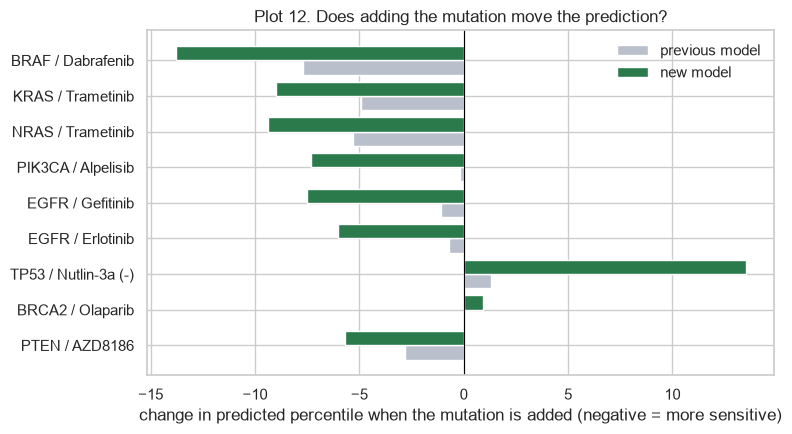

In [29]:
def make_predictor(fit_part, form, alpha):
    d_avg = fit_part.groupby("DRUG_ID")["LN_IC50"].mean()
    centered = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(
        make_features(fit_part, fit_part), fit_part["LN_IC50"] - fit_part["DRUG_ID"].map(d_avg))
    ridges = fit_ridges(fit_part, alpha, genes_only=(form == "c"))
    def predict(rows):
        p_tissue = drug_tissue_average(fit_part, rows)
        p_centered = rows["DRUG_ID"].map(d_avg).values + centered.predict(make_features(fit_part, rows))
        return combine(form, p_tissue, p_centered, predict_ridges(ridges, rows))
    return predict

predict_previous = predict_final
predict_new = make_predictor(train, NEW_FORM, NEW_ALPHA)

def mean_shift(predict, gene, drug_id, tissues):
    shifts = []
    for t in tissues:
        without = drug_percentile([drug_id], predict(make_profile(t, [], [drug_id])))[0]
        with_gene = drug_percentile([drug_id], predict(make_profile(t, [gene], [drug_id])))[0]
        shifts.append(with_gene - without)
    return np.mean(shifts)

clearest = [("BRAF", "Dabrafenib"), ("TP53", "Nutlin-3a (-)"), ("KRAS", "Trametinib")]
check_rows = []
for gene, drug_name in pairs:
    drug_id = drug_info.index[drug_info["DRUG_NAME"] == drug_name][0]
    tissues = [t for t in lines_per_tissue.index if train_lines.loc[train_lines["tissue"] == t, gene].sum() >= 3]
    lab = train[train["DRUG_ID"] == drug_id]  # training lines only
    sensitive = lab["LN_IC50"] <= cutoff[drug_id]
    lab_mutated, lab_not = 100 * sensitive[lab[gene] == 1].mean(), 100 * sensitive[lab[gene] == 0].mean()
    expected = -1 if lab_mutated > lab_not else 1  # -1 means the mutation should lower percentile
    old_shift = mean_shift(predict_previous, gene, drug_id, tissues)
    new_shift = mean_shift(predict_new, gene, drug_id, tissues)
    needed = 5 if (gene, drug_name) in clearest else 0.5
    check_rows.append({
        "gene": gene, "drug": drug_name,
        "lab sensitive, mutated (%)": round(lab_mutated), "lab sensitive, not mutated (%)": round(lab_not),
        "expected": "more sensitive" if expected < 0 else "less sensitive",
        "previous shift": round(old_shift, 1), "new shift": round(new_shift, 1),
        "passes": bool(expected * new_shift >= needed),
    })
check_table = pd.DataFrame(check_rows)
display(check_table)

cv_ok = new_cv_table.loc[NEW, "within-drug R2"] >= new_cv_table.loc["Previous final model", "within-drug R2"]
PASS = bool(check_table["passes"].all() and cv_ok)
print("cross-validation at least as good:", bool(cv_ok), "| all pairs pass:", bool(check_table["passes"].all()))
print("PASS:", PASS)

plt.figure(figsize=(8, 4.5))
labels = check_table["gene"] + " / " + check_table["drug"]
y = np.arange(len(labels))
plt.barh(y + 0.2, check_table["previous shift"], height=0.4, color="#b9c0cc", label="previous model")
plt.barh(y - 0.2, check_table["new shift"], height=0.4, color="#2b7a4b", label="new model")
plt.yticks(y, labels)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("change in predicted percentile when the mutation is added (negative = more sensitive)")
plt.title("Plot 12. Does adding the mutation move the prediction?")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/plot12_new_vs_old.png", dpi=150)
plt.show()


### Results of the improved model on the test cell lines
The new model passed, so from here on it is Sentinel's final model and the app uses it. We recompute the per-drug confidence from its cross-validation predictions, recheck the flag level with the rule from Section 19, and then repeat the main checks on the 192 test cell lines.


In [30]:
assert PASS

predict_final = predict_new
pred_new = predict_final(test)

cv_new = pd.concat(new_cv_parts)
sq_err = ((cv_new["actual"] - cv_new[NEW]) ** 2).groupby(cv_new["DRUG_ID"]).sum()
sq_dev = ((cv_new["actual"] - cv_new.groupby("DRUG_ID")["actual"].transform("mean")) ** 2).groupby(cv_new["DRUG_ID"]).sum()
drug_r2 = 1 - sq_err / sq_dev
confidence = pd.cut(drug_r2, [-np.inf, 0.15, 0.30, np.inf], labels=["Low", "Medium", "High"], right=False).astype(str)
print("drugs by confidence:", confidence.value_counts().to_dict())

# Section 19 rule: loosest level with <= 10% CV false alarms
level_rows = []
for part in new_cv_parts:
    really_sensitive = part["actual"] <= part["cut 0.2"]
    for level in flag_levels:
        flagged = part[NEW] <= part[f"cut {level}"]
        level_rows.append({"flag level": level,
                           "found (%)": 100 * (flagged & really_sensitive).sum() / really_sensitive.sum(),
                           "false alarm rate (%)": 100 * (flagged & ~really_sensitive).sum() / (~really_sensitive).sum()})
new_flags = pd.DataFrame(level_rows).groupby("flag level").mean().round(1)
print(new_flags.to_string())
FLAG_LEVEL = new_flags[new_flags["false alarm rate (%)"] <= 10].index.max()
flag_cutoff = train.groupby("DRUG_ID")["LN_IC50"].quantile(FLAG_LEVEL)
print("chosen flag level:", FLAG_LEVEL)

display(pd.DataFrame([score("Per-drug + tissue average", pred_drug_tissue),
                      score("Previous final model", pred_final),
                      score("Improved final model", pred_new)]))

display(pd.DataFrame([flag_row("Previous final model, 20% cutoff", pred_final, cutoff),
                      flag_row("Improved final model, 20% cutoff", pred_new, cutoff),
                      flag_row(f"Improved final model, {FLAG_LEVEL:.0%} cutoff", pred_new, flag_cutoff)]))

check["pred"] = pred_new
check["sq_error"] = (check["LN_IC50"] - check["pred"]) ** 2
check["found"] = actual_sensitive * (pred_new <= test_cutoff).astype(int)
print(group_table("sex", ["Female", "Male", "Unknown"]).to_string(index=False), "\n")
print(group_table("age group", ["under 18", "18-65", "over 65", "Unknown"]).to_string(index=False))
solid = check[check["tissue"] != "Haematopoietic and Lymphoid"]
for column in ["sex", "age group"]:
    found = (solid.groupby(column)["found"].sum() / solid.groupby(column)["actual_sensitive"].sum() * 100).round(1)
    print(f"\nsensitive found (%) without blood cancers, by {column}:", found.to_dict())

ranked["Improved final model"] = drug_percentile(test["DRUG_ID"], pred_new)
for method in ["Previous final model", "Improved final model"]:
    column = "Final model" if method == "Previous final model" else method
    top10 = ranked.sort_values(column, kind="stable").groupby("cell line").head(10)
    print(f"{method}: truly sensitive in top 10 (%) = {100 * top10.groupby('cell line')['sensitive'].mean().mean():.1f}")


drugs by confidence: {'Medium': 167, 'Low': 89, 'High': 39}
            found (%)  false alarm rate (%)
flag level                                 
0.20             22.5                   3.8
0.25             35.4                   7.0
0.30             42.8                   9.4
0.35             48.0                  11.9
0.40             53.6                  15.6
0.45             59.8                  21.9
0.50             68.0                  32.4
chosen flag level: 0.3


,method,RMSE,R2,within-drug R2
0,Per-drug + tissue average,1.324,0.768,0.177
1,Previous final model,1.302,0.775,0.204
2,Improved final model,1.297,0.777,0.210


,method,found,missed,false alarms,found (%),false alarm rate (%),flags that are right (%)
0,"Previous final model, 20% cutoff",2800,6834,1476,29.1,3.9,65.5
1,"Improved final model, 20% cutoff",2233,7401,1051,23.2,2.8,68.0
2,"Improved final model, 30% cutoff",3885,5749,2598,40.3,6.9,59.9


    sex  test cell lines  RMSE  within-drug R2  sensitive found (%)  blood cancer lines
 Female               66 1.314           0.211                 19.3                   7
   Male              122 1.273           0.211                 25.5                  21
Unknown                4 1.688           0.191                  4.3                   0 

age group  test cell lines  RMSE  within-drug R2  sensitive found (%)  blood cancer lines
 under 18               23 1.192           0.407                 40.4                  10
    18-65              101 1.331           0.193                 21.0                  14
  over 65               22 1.245           0.146                  5.6                   0
  Unknown               46 1.298           0.158                 14.0                   4

sensitive found (%) without blood cancers, by sex: {'Female': 2.0, 'Male': 3.3, 'Unknown': 4.3}

sensitive found (%) without blood cancers, by age group: {'18-65': 2.5, 'Unknown': 2.8, 'over 65':

The improved model is a little better on RMSE, R² and within-drug R²: test RMSE 1.297 against 1.302, and within-drug R² 0.210 against 0.204 (0.177 for the per-drug + tissue average). In its shortlists, **45.2% of the top 10 drugs were truly sensitive**, against 44.3% before. The gain is small; Section 23 checks it on repeated splits. 32 drugs had High confidence before and 39 now.

**Missed cases and false alarms.** At the strict 20% cutoff the new model is more careful: it finds fewer sensitive results (2,233, or 23.2%, against 2,800) but also raises fewer false alarms (1,051, or 2.8%, against 1,476), and 68.0% of its flags are right. Because it is more careful, the Section 19 rule (the loosest level with cross-validation false alarms at or below 10%) now allows a 30% flag level instead of 25%. At that level it finds **3,885 of 9,634 sensitive results (40.3%)** with 2,598 false alarms (6.9%), so it still misses about 6 in 10.

**Groups.** The pattern from Section 15 stays the same: 25.5% of sensitive results found for male and 19.3% for female cell lines, and 40.4% for donors under 18 against 5.6% for over 65. Without blood cancers, every group is between 2.0% and 5.6%, so the gaps still follow the share of blood cancers rather than sex or age.


### The stress test again, with the improved model
We repeat the questions from Section 21 with the improved model: the same mutation checks, the shortlist for SK-MEL-3, how useful the flag and confidence labels are, and how stable the shortlist is.


In [31]:
again_rows = []
for tissue, gene, drug_id in cases:
    for mutated in [0, 1]:
        full = shortlist(tissue, [gene] if mutated else [], top=len(DRUGS))
        hit = full[full["DRUG_ID"] == drug_id].iloc[0]
        again_rows.append({"question": f"{tissue}, {gene} {'mutated' if mutated else 'not mutated'}",
                           "drug": hit["Drug"], "app rank (of " + str(len(full)) + ")": int(hit["Rank"]),
                           "app percentile": int(hit["Percentile"])})
display(pd.DataFrame(again_rows))

tissue_name, genes = test_line_profile("SK-MEL-3")
display(add_lab_result(shortlist(tissue_name, genes), "SK-MEL-3").drop(columns="DRUG_ID"))

tables = [add_lab_result(shortlist(*test_line_profile(name)), name).assign(line=name)
          for name in sorted(test["CELL_LINE_NAME"].unique())]
tops = pd.concat(tables)
no_flag = tops.groupby("line")["Predicted sensitive"].apply(lambda s: (s == "No").all()).sum()
print(f"test cell lines with no drug predicted sensitive: {no_flag} of {tops['line'].nunique()}")
tested = tops[tops["Lab result"] != "not tested"]
for column in ["Predicted sensitive", "Confidence"]:
    share = tested.groupby(column)["Lab result"].apply(lambda s: round(100 * (s == "sensitive").mean(), 1))
    print(f"truly sensitive (%) by {column}:", share.to_dict())

first_top = {name: set(shortlist(*test_line_profile(name))["Drug"]) for name in sample}
rng = np.random.default_rng(0)
overlap = []
for repeat in range(3):
    keep = rng.choice(train_ids, int(0.9 * len(train_ids)), replace=False)
    predict_refit = make_predictor(train[train["SANGER_MODEL_ID"].isin(keep)], NEW_FORM, NEW_ALPHA)
    pred = predict_refit(profiles)
    for k, name in enumerate(sample):
        new_top = set(rank_drugs(pred[k * len(DRUGS):(k + 1) * len(DRUGS)])["Drug"])
        overlap.append(len(first_top[name] & new_top))
print(f"\ntop-10 drugs kept after refitting on 90% of training lines: average {np.mean(overlap):.1f} of 10, "
      f"lowest {min(overlap)} ({len(sample)} cell lines x 3 refits)")


,question,drug,app rank (of 286),app percentile
0,"Skin, BRAF not mutated",Dabrafenib,1,14
1,"Skin, BRAF mutated",Dabrafenib,1,6
2,"Lung, EGFR not mutated",Gefitinib,25,54
3,"Lung, EGFR mutated",Gefitinib,3,46
4,"Lung, TP53 not mutated",Nutlin-3a (-),2,46
5,"Lung, TP53 mutated",Nutlin-3a (-),108,60


,Rank,Drug,Target,Percentile,Predicted sensitive,Confidence,Lab result,Lab percentile
0,1,Dabrafenib,BRAF,7,Yes,High,sensitive,4
1,2,PLX-4720,BRAF,8,Yes,Medium,sensitive,6
2,3,Selumetinib (1062),"MEK1, MEK2",11,Yes,Medium,sensitive,15
3,4,Trametinib,"MEK1, MEK2",12,Yes,High,not sensitive,32
4,5,PD0325901,"MEK1, MEK2",12,Yes,High,not sensitive,36
5,6,SCH772984,"ERK1, ERK2",13,Yes,Medium,not sensitive,21
6,7,Refametinib,"MEK1, MEK2",13,Yes,Medium,not sensitive,32
7,8,SB590885,BRAF,13,Yes,High,sensitive,10
8,9,ERK_6604,"ERK1,ERK2",13,Yes,Medium,not tested,
9,10,ERK_2440,"ERK1,ERK2",13,Yes,Medium,not tested,


test cell lines with no drug predicted sensitive: 71 of 192
truly sensitive (%) by Predicted sensitive: {'No': 32.8, 'Yes': 59.8}
truly sensitive (%) by Confidence: {'High': 60.0, 'Low': 41.1, 'Medium': 42.0}



top-10 drugs kept after refitting on 90% of training lines: average 8.5 of 10, lowest 5 (16 cell lines x 3 refits)


**What changed for a researcher using the app:**
- **TP53 and Nutlin-3a (lung).** Without a TP53 mutation, Nutlin-3a is now ranked 2nd of 286 drugs (46th percentile); with one it falls to 108th (60th percentile). Before, it was 39th against 45th and at the 57th percentile either way. The ranking now goes the same way as the lab, where 10 of 42 TP53-normal and none of 146 TP53-mutant lung lines were sensitive.
- **EGFR and Gefitinib (lung).** With an EGFR mutation, Gefitinib is ranked 3rd instead of 25th (before: 6th against 30th), but at the 46th percentile it is still not flagged. Only 7 EGFR-mutant lung lines exist, so the model still learns little about them.
- **BRAF and Dabrafenib (skin).** Still ranked first with or without BRAF (6th against 14th percentile; before, 7th against 12th). The gap is wider, but, likely because most skin training lines are BRAF-mutant, the skin average still pulls BRAF-normal melanoma lines towards Dabrafenib. **This is the main failure that remains.**
- **SK-MEL-3.** Dabrafenib and PLX-4720 are still the top two and both were sensitive; of the eight top-10 drugs tested on this line, four were sensitive, as before.
- **Labels.** 59.8% of flagged drugs were truly sensitive against 32.8% of the others, and 60.0% of High-confidence drugs against 41.1% of Low. For 71 of 192 test cell lines no drug is flagged (82 before, partly because the flag level is now 30%).
- **Stability.** After refitting on 90% of the training cell lines, 8.5 of the top 10 drugs stay on average (lowest 5), against 7.9 (lowest 2) before.


## 23. Checking the improved model on repeated splits
As Section 18 did for the first model, we repeat the comparison on the same 10 random splits of all 958 cell lines. On each split, the per-drug + tissue average, the first final model and the Section 22 model are refit on that split's training lines with the settings already chosen; nothing is tuned.


In [32]:
if RUN_STABILITY_CHECKS:
    recheck_rows = []
    splits = GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=0).split(data, groups=data["SANGER_MODEL_ID"])
    for split, (tr_idx, te_idx) in enumerate(splits, start=1):
        tr, te = data.iloc[tr_idx], data.iloc[te_idx]
        preds = predict_all(tr, te)
        improved_pred = make_predictor(tr, "b", 30)(te)  # Section 22 winner: equal thirds, alpha 30
        recheck_rows.append({
            "split": split,
            "per-drug + tissue average": within_drug_r2(te, preds["Per-drug + tissue average"]),
            "first final model": within_drug_r2(te, preds[FINAL]),
            "improved model": within_drug_r2(te, improved_pred),
        })

    recheck_table = pd.DataFrame(recheck_rows)
    recheck_table["gain over baseline"] = recheck_table["improved model"] - recheck_table["per-drug + tissue average"]
    recheck_table["gain over first model"] = recheck_table["improved model"] - recheck_table["first final model"]

    print("Within-drug R2 on 10 repeated splits:")
    print(recheck_table.round(3).to_string(index=False))

    print("\naverage:", recheck_table.drop(columns="split").mean().round(3).to_dict())
    print("improved model range:", round(float(recheck_table["improved model"].min()), 3), "to", round(float(recheck_table["improved model"].max()), 3))
    print("gain over baseline (avg, min to max):",
          round(float(recheck_table["gain over baseline"].mean()), 3), "|",
          round(float(recheck_table["gain over baseline"].min()), 3), "to",
          round(float(recheck_table["gain over baseline"].max()), 3))
    print("gain over first model (avg, min to max):",
          round(float(recheck_table["gain over first model"].mean()), 3), "|",
          round(float(recheck_table["gain over first model"].min()), 3), "to",
          round(float(recheck_table["gain over first model"].max()), 3))
    print("splits where improved model beats baseline:", int((recheck_table["gain over baseline"] > 0).sum()), "of 10")
    print("splits where improved model beats first model:", int((recheck_table["gain over first model"] > 0).sum()), "of 10")
else:
    print("Skipped (RUN_STABILITY_CHECKS = False). The results from our full run are described below.")


Within-drug R2 on 10 repeated splits:
 split  per-drug + tissue average  first final model  improved model  gain over baseline  gain over first model
     1                      0.227              0.238           0.248               0.021                  0.010
     2                      0.201              0.213           0.226               0.025                  0.013
     3                      0.175              0.187           0.196               0.021                  0.009
     4                      0.209              0.230           0.234               0.025                  0.004
     5                      0.205              0.215           0.219               0.014                  0.004
     6                      0.201              0.226           0.229               0.028                  0.003
     7                      0.221              0.245           0.248               0.027                  0.003
     8                      0.180              0.187           0.2

**Result.** The Section 22 model averages a within-drug R² of 0.220 (range 0.189 to 0.248), against 0.212 for the first final model and 0.196 for the per-drug + tissue average. It beats both on all 10 splits, by 0.024 on average over the baseline (range 0.014 to 0.029) and by 0.007 over the first model (range 0.003 to 0.013). The gain is small but consistent.


## 24. Adding gene expression
Even with a model for each drug, Sentinel only sees tissue and 84 yes/no mutations, so it still misses about 6 in 10 sensitive results and struggles on solid tumors. Cell Model Passports (van der Meer et al. 2019) also provides RNA-seq gene expression, merged from Sanger and Broad Institute CCLE data (Ghandi et al. 2019), which measures how strongly each gene is switched on.

To avoid leakage, every step below is fitted on training lines only (and, inside cross-validation, on the fit part only):
- convert expression to log2(TPM + 1);
- keep the 1,500 most variable genes, standardize them and compress them into 20 or 50 summary features with principal component analysis (PCA; Jolliffe and Cadima 2016);
- fill cell lines without expression with their tissue's training average, plus a 0/1 "has expression" flag. New cell lines entered in the app are handled the same way.

We add the expression features to the per-drug ridge only, or to both the ridge and LightGBM, with 20 or 50 features and three ridge strengths, and compare them by the same 3-fold cross-validation as before.

**Pass rule (set before running):** cross-validation within-drug R² must beat the Section 22 model (0.209), and all 9 drug–gene pairs must still pass the mutation check from Section 22, with each tissue's average expression held fixed.


In [33]:
import zipfile
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

kept_ids = set(data["SANGER_MODEL_ID"].unique())
with zipfile.ZipFile("data/raw/rnaseq_merged_20260323.zip") as zf:
    with zf.open("rnaseq_merged_rsem_tpm_20260323.csv") as f:
        header = pd.read_csv(f, nrows=0).columns.tolist()
        keep_cols = ["Unnamed: 2"] + [c for c in header[3:] if c in kept_ids]
        f.seek(0)
        tpm_raw = pd.read_csv(f, skiprows=[1, 2, 3], usecols=keep_cols, index_col="Unnamed: 2", low_memory=False)

expr_log = np.log2(tpm_raw.T + 1.0)
train_ids_all = set(train["SANGER_MODEL_ID"].unique())
test_ids_all = set(test["SANGER_MODEL_ID"].unique())
print(f"cell lines with RNA-seq expression: {len(kept_ids & set(expr_log.index))} of {len(kept_ids)} "
      f"({len(kept_ids - set(expr_log.index))} missing)")
print(f"train with expression: {len(train_ids_all & set(expr_log.index))} of {len(train_ids_all)} | "
      f"test with expression: {len(test_ids_all & set(expr_log.index))} of {len(test_ids_all)}")

def fit_expression(fit_part, n_components, n_top=1500):
    fit_lines = fit_part.drop_duplicates("SANGER_MODEL_ID")
    has_ids = [m for m in fit_lines["SANGER_MODEL_ID"] if m in expr_log.index]
    X_fit = expr_log.loc[has_ids].dropna(axis=1)
    top_genes = X_fit.var(axis=0).nlargest(n_top).index
    scaler = StandardScaler().fit(X_fit[top_genes].values)
    pca = PCA(n_components=n_components, random_state=42).fit(scaler.transform(X_fit[top_genes].values))
    pc_cols = [f"expr_PC{k + 1}" for k in range(n_components)]
    pcs_fit = pd.DataFrame(pca.transform(scaler.transform(X_fit[top_genes].values)), index=has_ids, columns=pc_cols)
    tissues_fit = fit_lines.set_index("SANGER_MODEL_ID").loc[has_ids, "tissue"]
    return {
        "top_genes": top_genes, "scaler": scaler, "pca": pca, "pc_cols": pc_cols,
        "tissue_means": pcs_fit.groupby(tissues_fit).mean(), "global_mean": pcs_fit.mean(),
    }

def expr_features(expr_fit, rows):
    pc_cols = expr_fit["pc_cols"]
    cols = pc_cols + ["has_expression"]
    has_id_col = "SANGER_MODEL_ID" in rows.columns
    ids = rows["SANGER_MODEL_ID"].unique() if has_id_col else []
    real_ids = [m for m in ids if m in expr_log.index]
    if real_ids:
        vals = expr_log.loc[real_ids, expr_fit["top_genes"]].fillna(
            pd.Series(expr_fit["scaler"].mean_, index=expr_fit["top_genes"])).values
        real_pcs = expr_fit["pca"].transform(expr_fit["scaler"].transform(vals))
        pc_map = {m: np.append(vec, 1.0) for m, vec in zip(real_ids, real_pcs)}
    else:
        pc_map = {}
    tissue_means, global_mean = expr_fit["tissue_means"], expr_fit["global_mean"].values
    tissue_fill = {t: np.append(tissue_means.loc[t].values, 0.0) for t in tissue_means.index}
    global_fill = np.append(global_mean, 0.0)
    # fill missing lines and new profiles with that tissue's training-mean PCs
    row_ids = rows["SANGER_MODEL_ID"].values if has_id_col else [None] * len(rows)
    mat = np.vstack([pc_map[m] if m in pc_map else tissue_fill.get(t, global_fill)
                     for m, t in zip(row_ids, rows["tissue"].values)])
    return pd.DataFrame(mat, index=rows.index, columns=cols)

def make_lgbm_features(fit_part, part, expr_df=None):
    X = make_features(fit_part, part)
    return pd.concat([X, expr_df], axis=1) if expr_df is not None else X

def fit_expr_ridges(fit_part, expr_df, alpha):
    tissues = sorted(fit_part["tissue"].unique())
    X = np.hstack([ridge_inputs(fit_part, tissues, False), expr_df.values])
    y = fit_part["LN_IC50"].values
    ridges = {d: Ridge(alpha=alpha).fit(X[rows], y[rows])
              for d, rows in fit_part.groupby("DRUG_ID").indices.items()}
    return {"ridges": ridges, "tissues": tissues}

def predict_expr_ridges(fitted, part, expr_df):
    X = np.hstack([ridge_inputs(part, fitted["tissues"], False), expr_df.values])
    pred = np.zeros(len(part))
    for d, ridge in fitted["ridges"].items():
        rows = part["DRUG_ID"].values == d
        if rows.any():
            pred[rows] = ridge.predict(X[rows])
    return pred

EXPR_CANDIDATES = {}
for n_comp in [20, 50]:
    for mode in ["ridge", "ridge+lgbm"]:
        for alpha in [10, 30, 100]:
            EXPR_CANDIDATES[f"{n_comp} PCs, {mode}, alpha {alpha}"] = (n_comp, mode, alpha)

expr_cv_rows = []
folds = GroupKFold(n_splits=3).split(train, groups=train["SANGER_MODEL_ID"])
for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    d_avg = fit_part.groupby("DRUG_ID")["LN_IC50"].mean()
    y_centered = fit_part["LN_IC50"] - fit_part["DRUG_ID"].map(d_avg)
    val_base = val_part["DRUG_ID"].map(d_avg).values
    p_tissue = drug_tissue_average(fit_part, val_part)
    lgb_base = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(
        make_features(fit_part, fit_part), y_centered)
    p_centered_base = val_base + lgb_base.predict(make_features(fit_part, val_part))
    p_ridge_base = predict_ridges(fit_ridges(fit_part, 30), val_part)
    preds = {"Current model (no expression)": (p_tissue + p_centered_base + p_ridge_base) / 3}

    for n_comp in [20, 50]:
        expr_fit = fit_expression(fit_part, n_comp)
        ex_fit = expr_features(expr_fit, fit_part)
        ex_val = expr_features(expr_fit, val_part)
        lgb_expr = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(
            make_lgbm_features(fit_part, fit_part, ex_fit), y_centered)
        p_centered_expr = val_base + lgb_expr.predict(make_lgbm_features(fit_part, val_part, ex_val))
        for alpha in [10, 30, 100]:
            p_ridge_expr = predict_expr_ridges(fit_expr_ridges(fit_part, ex_fit, alpha), val_part, ex_val)
            preds[f"{n_comp} PCs, ridge, alpha {alpha}"] = (p_tissue + p_centered_base + p_ridge_expr) / 3
            preds[f"{n_comp} PCs, ridge+lgbm, alpha {alpha}"] = (p_tissue + p_centered_expr + p_ridge_expr) / 3

    for name, pred in preds.items():
        rmse = np.sqrt(mean_squared_error(val_part["LN_IC50"], pred))
        expr_cv_rows.append({"method": name, "RMSE": rmse,
                             "within-drug R2": within_drug_r2(val_part, pred),
                             "top-10 hit rate (%)": top10_hit_rate(fit_part, val_part, pred)})

expr_cv_table = pd.DataFrame(expr_cv_rows).groupby("method", sort=False).mean().round(3)
print("Cross-validation on training cell lines (average of 3 folds):")
print(expr_cv_table.to_string())

EXPR_BEST = expr_cv_table.drop(index="Current model (no expression)")["within-drug R2"].idxmax()
BEST_NC, BEST_MODE, BEST_ALPHA = EXPR_CANDIDATES[EXPR_BEST]
print("\nchosen from cross-validation:", EXPR_BEST)

cell lines with RNA-seq expression: 933 of 958 (25 missing)
train with expression: 746 of 766 | test with expression: 187 of 192


Cross-validation on training cell lines (average of 3 folds):
                                RMSE  within-drug R2  top-10 hit rate (%)
method                                                                   
Current model (no expression)  1.305           0.209               41.462
20 PCs, ridge, alpha 10        1.271           0.250               44.869
20 PCs, ridge+lgbm, alpha 10   1.254           0.270               46.017
20 PCs, ridge, alpha 30        1.268           0.253               45.025
20 PCs, ridge+lgbm, alpha 30   1.252           0.272               46.030
20 PCs, ridge, alpha 100       1.268           0.253               44.986
20 PCs, ridge+lgbm, alpha 100  1.253           0.271               45.794
50 PCs, ridge, alpha 10        1.261           0.261               45.691
50 PCs, ridge+lgbm, alpha 10   1.245           0.280               46.135
50 PCs, ridge, alpha 30        1.258           0.265               45.717
50 PCs, ridge+lgbm, alpha 30   1.243           0.2

In [34]:
def make_expr_predictor(fit_part, n_comp, mode, alpha):
    d_avg = fit_part.groupby("DRUG_ID")["LN_IC50"].mean()
    y_centered = fit_part["LN_IC50"] - fit_part["DRUG_ID"].map(d_avg)
    expr_fit = fit_expression(fit_part, n_comp)
    ex_fit = expr_features(expr_fit, fit_part)
    lgb_ex = ex_fit if mode == "ridge+lgbm" else None
    centered = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(
        make_lgbm_features(fit_part, fit_part, lgb_ex), y_centered)
    ridges = fit_expr_ridges(fit_part, ex_fit, alpha)
    def predict(rows):
        p_tissue = drug_tissue_average(fit_part, rows)
        ex_rows = expr_features(expr_fit, rows)
        lgb_rows = ex_rows if mode == "ridge+lgbm" else None
        p_centered = rows["DRUG_ID"].map(d_avg).values + centered.predict(make_lgbm_features(fit_part, rows, lgb_rows))
        p_ridge = predict_expr_ridges(ridges, rows, ex_rows)
        return (p_tissue + p_centered + p_ridge) / 3
    return predict

predict_expr = make_expr_predictor(train, BEST_NC, BEST_MODE, BEST_ALPHA)

expr_check_rows = []
for gene, drug_name in pairs:
    drug_id = drug_info.index[drug_info["DRUG_NAME"] == drug_name][0]
    tissues = [t for t in lines_per_tissue.index if train_lines.loc[train_lines["tissue"] == t, gene].sum() >= 3]
    lab = train[train["DRUG_ID"] == drug_id]
    sensitive = lab["LN_IC50"] <= cutoff[drug_id]
    lab_mutated, lab_not = 100 * sensitive[lab[gene] == 1].mean(), 100 * sensitive[lab[gene] == 0].mean()
    expected = -1 if lab_mutated > lab_not else 1
    prev_shift = mean_shift(predict_final, gene, drug_id, tissues)
    new_shift = mean_shift(predict_expr, gene, drug_id, tissues)
    needed = 5 if (gene, drug_name) in clearest else 0.5
    expr_check_rows.append({
        "gene": gene, "drug": drug_name,
        "expected": "more sensitive" if expected < 0 else "less sensitive",
        "previous shift": round(prev_shift, 1), "new shift": round(new_shift, 1),
        "passes": bool(expected * new_shift >= needed),
    })
expr_check_table = pd.DataFrame(expr_check_rows)
display(expr_check_table)

expr_cv_ok = expr_cv_table.loc[EXPR_BEST, "within-drug R2"] > expr_cv_table.loc["Current model (no expression)", "within-drug R2"]
EXPR_PASS = bool(expr_check_table["passes"].all() and expr_cv_ok)
print("cross-validation strictly higher:", bool(expr_cv_ok), "| all pairs pass:", bool(expr_check_table["passes"].all()))
print("PASS:", EXPR_PASS)

,gene,drug,expected,previous shift,new shift,passes
0,BRAF,Dabrafenib,more sensitive,-13.8,-10.9,True
1,KRAS,Trametinib,more sensitive,-9.0,-3.3,False
2,NRAS,Trametinib,more sensitive,-9.4,-3.1,True
3,PIK3CA,Alpelisib,more sensitive,-7.3,-6.7,True
4,EGFR,Gefitinib,more sensitive,-7.5,-6.5,True
5,EGFR,Erlotinib,more sensitive,-6.0,-5.3,True
6,TP53,Nutlin-3a (-),less sensitive,13.5,11.2,True
7,BRCA2,Olaparib,less sensitive,0.9,0.9,True
8,PTEN,AZD8186,more sensitive,-5.7,-2.6,True


cross-validation strictly higher: True | all pairs pass: False
PASS: False


**Result: failed.** Expression raises cross-validation within-drug R² from 0.209 to 0.282, the biggest jump so far, but KRAS with Trametinib moves only 3.3 percentiles (5 needed), so this version fails our check and is not used. A likely reason: the 50 expression features share one ridge with the 0/1 mutation flags, and expression patterns linked to KRAS take over part of the KRAS effect. For a new cell line without expression data, that effect would then be lost.


## 25. Two-stage expression model
To keep the mutation effects, each drug's ridge is fitted in two stages: first on tissue and the 84 mutations (as in Section 22), then a second ridge on expression for whatever the first stage leaves unexplained. Expression can then add to the mutation effects but not replace them. We try three strengths for the second stage (alpha 30, 100 and 300), with LightGBM using the expression features as well, and keep the same pass rule as Section 24.


In [35]:
def fit_two_stage_ridges(fit_part, ex_fit, alpha_mut=30, alpha_expr=100):
    mut_ridges = fit_ridges(fit_part, alpha_mut, genes_only=False)
    fit_mut_pred = predict_ridges(mut_ridges, fit_part)
    residuals = fit_part["LN_IC50"].values - fit_mut_pred
    X_ex = ex_fit.values
    expr_ridges = {
        drug_id: Ridge(alpha=alpha_expr).fit(X_ex[rows], residuals[rows])
        for drug_id, rows in fit_part.groupby("DRUG_ID").indices.items()
    }
    return {"mut": mut_ridges, "expr": expr_ridges}

def predict_two_stage_ridges(fitted, part, ex_part):
    pred = predict_ridges(fitted["mut"], part)
    X_ex = ex_part.values
    for drug_id, ridge in fitted["expr"].items():
        rows = part["DRUG_ID"].values == drug_id
        if rows.any():
            pred[rows] += ridge.predict(X_ex[rows])
    return pred

EX2_ALPHAS = [30, 100, 300]
ex2_cv_rows = []
cached_folds = []  # reuse 3-fold splits and fitted expression PCs in Sections 26 and 27

folds = GroupKFold(n_splits=3).split(train, groups=train["SANGER_MODEL_ID"])
for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    d_avg = fit_part.groupby("DRUG_ID")["LN_IC50"].mean()
    y_centered = fit_part["LN_IC50"] - fit_part["DRUG_ID"].map(d_avg)
    val_base = val_part["DRUG_ID"].map(d_avg).values
    p_tissue = drug_tissue_average(fit_part, val_part)

    lgb_base = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(
        make_features(fit_part, fit_part), y_centered)
    p_lgb_base = val_base + lgb_base.predict(make_features(fit_part, val_part))
    p_ridge_base = predict_ridges(fit_ridges(fit_part, 30), val_part)

    expr_fit = fit_expression(fit_part, 50)
    ex_fit = expr_features(expr_fit, fit_part)
    ex_val = expr_features(expr_fit, val_part)
    lgb_expr = lgb.LGBMRegressor(random_state=42, verbose=-1).fit(
        make_lgbm_features(fit_part, fit_part, ex_fit), y_centered)
    p_lgb_expr = val_base + lgb_expr.predict(make_lgbm_features(fit_part, val_part, ex_val))

    preds = {"Section 22 model (no expression)": (p_tissue + p_lgb_base + p_ridge_base) / 3}
    ridges_by_alpha = {}
    for alpha_expr in EX2_ALPHAS:
        p_ridge_2s = predict_two_stage_ridges(
            fit_two_stage_ridges(fit_part, ex_fit, 30, alpha_expr), val_part, ex_val)
        ridges_by_alpha[alpha_expr] = p_ridge_2s
        preds[f"Two-stage expression, alpha_expr {alpha_expr}"] = (p_tissue + p_lgb_expr + p_ridge_2s) / 3

    for name, pred in preds.items():
        rmse = np.sqrt(mean_squared_error(val_part["LN_IC50"], pred))
        ex2_cv_rows.append({
            "method": name, "RMSE": rmse,
            "within-drug R2": within_drug_r2(val_part, pred),
            "top-10 hit rate (%)": top10_hit_rate(fit_part, val_part, pred),
        })

    cached_folds.append({
        "fold": fold, "fit_idx": fit_idx, "val_idx": val_idx,
        "ex_fit": ex_fit, "ex_val": ex_val, "p_tissue": p_tissue,
        "p_lgb_def": p_lgb_expr, "ridges_by_alpha": ridges_by_alpha,
    })

ex2_cv_table = pd.DataFrame(ex2_cv_rows).groupby("method", sort=False).mean().round(3)
print("Cross-validation on training cell lines (average of 3 folds):")
print(ex2_cv_table.to_string())

BEST_EX2_LABEL = ex2_cv_table.drop(index="Section 22 model (no expression)")["within-drug R2"].idxmax()
BEST_EX2_ALPHA = int(BEST_EX2_LABEL.split()[-1])
print("\nchosen from cross-validation:", BEST_EX2_LABEL)

Cross-validation on training cell lines (average of 3 folds):
                                       RMSE  within-drug R2  top-10 hit rate (%)
method                                                                          
Section 22 model (no expression)      1.305           0.209               41.462
Two-stage expression, alpha_expr 30   1.249           0.275               46.070
Two-stage expression, alpha_expr 100  1.249           0.275               45.952
Two-stage expression, alpha_expr 300  1.250           0.274               45.874

chosen from cross-validation: Two-stage expression, alpha_expr 30


In [36]:
def make_ex2_predictor(fit_part, alpha_expr, lgb_params=None, drug_weights=None):
    d_avg = fit_part.groupby("DRUG_ID")["LN_IC50"].mean()
    y_centered = fit_part["LN_IC50"] - fit_part["DRUG_ID"].map(d_avg)
    expr_fit = fit_expression(fit_part, 50)
    ex_fit = expr_features(expr_fit, fit_part)
    params = {"random_state": 42, "verbose": -1}
    if lgb_params:
        params.update(lgb_params)
    centered = lgb.LGBMRegressor(**params).fit(make_lgbm_features(fit_part, fit_part, ex_fit), y_centered)
    ridges = fit_two_stage_ridges(fit_part, ex_fit, 30, alpha_expr)
    def predict(rows):
        p_tissue = drug_tissue_average(fit_part, rows)
        ex_rows = expr_features(expr_fit, rows)
        p_centered = rows["DRUG_ID"].map(d_avg).values + centered.predict(
            make_lgbm_features(fit_part, rows, ex_rows))
        p_ridge = predict_two_stage_ridges(ridges, rows, ex_rows)
        if drug_weights is None:
            return (p_tissue + p_centered + p_ridge) / 3
        w = rows["DRUG_ID"].map(drug_weights).fillna(1 / 3).values
        return (1 - w) / 2 * (p_tissue + p_centered) + w * p_ridge
    return predict

predict_ex2 = make_ex2_predictor(train, BEST_EX2_ALPHA)

ex2_check_rows = []
for gene, drug_name in pairs:
    drug_id = drug_info.index[drug_info["DRUG_NAME"] == drug_name][0]
    tissues = [t for t in lines_per_tissue.index if train_lines.loc[train_lines["tissue"] == t, gene].sum() >= 3]
    lab = train[train["DRUG_ID"] == drug_id]
    sensitive = lab["LN_IC50"] <= cutoff[drug_id]
    expected = -1 if sensitive[lab[gene] == 1].mean() > sensitive[lab[gene] == 0].mean() else 1
    prev_shift = mean_shift(predict_final, gene, drug_id, tissues)
    new_shift = mean_shift(predict_ex2, gene, drug_id, tissues)
    needed = 5 if (gene, drug_name) in clearest else 0.5
    ex2_check_rows.append({
        "gene": gene, "drug": drug_name,
        "expected": "more sensitive" if expected < 0 else "less sensitive",
        "Section 22 shift": round(prev_shift, 1), "new shift": round(new_shift, 1),
        "passes": bool(expected * new_shift >= needed),
    })
ex2_check_table = pd.DataFrame(ex2_check_rows)
display(ex2_check_table)

ex2_cv_ok = ex2_cv_table.loc[BEST_EX2_LABEL, "within-drug R2"] > ex2_cv_table.loc["Section 22 model (no expression)", "within-drug R2"]
EX2_PASS = bool(ex2_check_table["passes"].all() and ex2_cv_ok)
print("cross-validation strictly higher:", bool(ex2_cv_ok), "| all pairs pass:", bool(ex2_check_table["passes"].all()))
print("PASS:", EX2_PASS)

,gene,drug,expected,Section 22 shift,new shift,passes
0,BRAF,Dabrafenib,more sensitive,-13.8,-12.4,True
1,KRAS,Trametinib,more sensitive,-9.0,-7.0,True
2,NRAS,Trametinib,more sensitive,-9.4,-5.9,True
3,PIK3CA,Alpelisib,more sensitive,-7.3,-7.1,True
4,EGFR,Gefitinib,more sensitive,-7.5,-6.7,True
5,EGFR,Erlotinib,more sensitive,-6.0,-5.2,True
6,TP53,Nutlin-3a (-),less sensitive,13.5,13.3,True
7,BRCA2,Olaparib,less sensitive,0.9,0.9,True
8,PTEN,AZD8186,more sensitive,-5.7,-4.2,True


cross-validation strictly higher: True | all pairs pass: True
PASS: True


**Result: passed.** The best version (alpha 30) reaches a cross-validation within-drug R² of 0.275, and all 9 drug–gene pairs pass, with KRAS and Trametinib back at 7.0 percentiles. It gives up a little of Section 24's score (0.275 against 0.282) in exchange for keeping the mutation effects.


## 26. Tuning LightGBM
LightGBM still used its default settings, which were chosen before the 50 expression features were added. We compare the defaults with three larger, slower-learning settings inside the Section 25 model. Pass rule: cross-validation must improve and all 9 drug–gene pairs must still pass.


In [37]:
LGB_CANDIDATES = {
    "Default (leaves=31, min_child=20, trees=100, lr=0.1)": {"num_leaves": 31, "min_child_samples": 20, "n_estimators": 100, "learning_rate": 0.1},
    "leaves=31, min_child=50, trees=200, lr=0.05": {"num_leaves": 31, "min_child_samples": 50, "n_estimators": 200, "learning_rate": 0.05},
    "leaves=63, min_child=50, trees=200, lr=0.05": {"num_leaves": 63, "min_child_samples": 50, "n_estimators": 200, "learning_rate": 0.05},
    "leaves=63, min_child=50, trees=300, lr=0.05": {"num_leaves": 63, "min_child_samples": 50, "n_estimators": 300, "learning_rate": 0.05},
}

lgb_tune_rows = []
for f in cached_folds:
    fit_part, val_part = train.iloc[f["fit_idx"]], train.iloc[f["val_idx"]]
    d_avg = fit_part.groupby("DRUG_ID")["LN_IC50"].mean()
    y_centered = fit_part["LN_IC50"] - fit_part["DRUG_ID"].map(d_avg)
    val_base = val_part["DRUG_ID"].map(d_avg).values
    p_ridge = f["ridges_by_alpha"][BEST_EX2_ALPHA]
    f["lgb_by_cfg"] = {}

    for label, params in LGB_CANDIDATES.items():
        if label.startswith("Default"):
            p_lgb = f["p_lgb_def"]
        else:
            m = lgb.LGBMRegressor(random_state=42, verbose=-1, **params).fit(
                make_lgbm_features(fit_part, fit_part, f["ex_fit"]), y_centered)
            p_lgb = val_base + m.predict(make_lgbm_features(fit_part, val_part, f["ex_val"]))
        f["lgb_by_cfg"][label] = p_lgb
        blend = (f["p_tissue"] + p_lgb + p_ridge) / 3
        lgb_tune_rows.append({
            "config": label,
            "LightGBM R2": within_drug_r2(val_part, p_lgb),
            "blend RMSE": np.sqrt(mean_squared_error(val_part["LN_IC50"], blend)),
            "blend within-drug R2": within_drug_r2(val_part, blend),
            "blend top-10 (%)": top10_hit_rate(fit_part, val_part, blend),
        })

lgb_tune_table = pd.DataFrame(lgb_tune_rows).groupby("config", sort=False).mean().round(3)
print("LightGBM tuning CV (average of 3 folds):")
print(lgb_tune_table.to_string())

BEST_LGB_LABEL = lgb_tune_table["blend within-drug R2"].idxmax()
BEST_LGB_PARAMS = LGB_CANDIDATES[BEST_LGB_LABEL]
print("\nchosen LightGBM config:", BEST_LGB_LABEL)

LightGBM tuning CV (average of 3 folds):
                                                      LightGBM R2  blend RMSE  blend within-drug R2  blend top-10 (%)
config                                                                                                               
Default (leaves=31, min_child=20, trees=100, lr=0.1)        0.242       1.249                 0.275            46.070
leaves=31, min_child=50, trees=200, lr=0.05                 0.244       1.249                 0.275            46.305
leaves=63, min_child=50, trees=200, lr=0.05                 0.257       1.246                 0.278            46.370
leaves=63, min_child=50, trees=300, lr=0.05                 0.263       1.245                 0.280            46.618

chosen LightGBM config: leaves=63, min_child=50, trees=300, lr=0.05


In [38]:
predict_ex2_tuned = make_ex2_predictor(train, BEST_EX2_ALPHA, BEST_LGB_PARAMS)

lgb_check_rows = []
for gene, drug_name in pairs:
    drug_id = drug_info.index[drug_info["DRUG_NAME"] == drug_name][0]
    tissues = [t for t in lines_per_tissue.index if train_lines.loc[train_lines["tissue"] == t, gene].sum() >= 3]
    lab = train[train["DRUG_ID"] == drug_id]
    sensitive = lab["LN_IC50"] <= cutoff[drug_id]
    expected = -1 if sensitive[lab[gene] == 1].mean() > sensitive[lab[gene] == 0].mean() else 1
    new_shift = mean_shift(predict_ex2_tuned, gene, drug_id, tissues)
    needed = 5 if (gene, drug_name) in clearest else 0.5
    lgb_check_rows.append({
        "gene": gene, "drug": drug_name,
        "expected": "more sensitive" if expected < 0 else "less sensitive",
        "shift": round(new_shift, 1),
        "passes": bool(expected * new_shift >= needed),
    })
lgb_check_table = pd.DataFrame(lgb_check_rows)
display(lgb_check_table)

def_label = "Default (leaves=31, min_child=20, trees=100, lr=0.1)"
lgb_cv_ok = lgb_tune_table.loc[BEST_LGB_LABEL, "blend within-drug R2"] > lgb_tune_table.loc[def_label, "blend within-drug R2"]
LGB_PASS = bool(lgb_check_table["passes"].all() and lgb_cv_ok)
print("cross-validation strictly higher:", bool(lgb_cv_ok), "| all pairs pass:", bool(lgb_check_table["passes"].all()))
print("PASS:", LGB_PASS)

ACTIVE_LGB_PARAMS = BEST_LGB_PARAMS if LGB_PASS else LGB_CANDIDATES[def_label]
ACTIVE_LGB_LABEL = BEST_LGB_LABEL if LGB_PASS else def_label

,gene,drug,expected,shift,passes
0,BRAF,Dabrafenib,more sensitive,-14.2,True
1,KRAS,Trametinib,more sensitive,-8.8,True
2,NRAS,Trametinib,more sensitive,-8.8,True
3,PIK3CA,Alpelisib,more sensitive,-9.0,True
4,EGFR,Gefitinib,more sensitive,-8.7,True
5,EGFR,Erlotinib,more sensitive,-6.4,True
6,TP53,Nutlin-3a (-),less sensitive,15.7,True
7,BRCA2,Olaparib,less sensitive,0.8,True
8,PTEN,AZD8186,more sensitive,-4.6,True


cross-validation strictly higher: True | all pairs pass: True
PASS: True


**Result: passed.** The largest setting (63 leaves, at least 50 cell lines per leaf, 300 trees, learning rate 0.05) raises the blend's cross-validation within-drug R² from 0.275 to 0.280, and all 9 pairs still pass.


## 27. Per-drug blend weights and final test
Equal thirds treat every drug the same, but for a drug driven by one gene the per-drug ridge may deserve more weight. For each drug we try ridge weights of 1/3, 1/2 and 2/3, keeping 1/3 unless a larger weight cuts that drug's cross-validation error by at least 1%. To score this rule fairly, weights chosen on two folds are tested on the third (nested cross-validation). Pass rule: the nested score must beat equal thirds, and all 9 pairs must still pass.


In [39]:
def fit_drug_weights(oof_df, ridge_weights=(1 / 3, 0.50, 2 / 3), min_gain=0.01):
    weights = {}
    for drug_id, grp in oof_df.groupby("DRUG_ID"):
        y = grp["actual"].values
        pt, pc, pr = grp["pt"].values, grp["pc"].values, grp["pr"].values
        mse_default = np.mean((y - (pt + pc + pr) / 3) ** 2)
        best_w, best_mse = 1 / 3, mse_default
        for w in ridge_weights:
            if w <= 1 / 3:
                continue
            p = (1 - w) / 2 * (pt + pc) + w * pr
            mse = np.mean((y - p) ** 2)
            if mse < best_mse:
                best_w, best_mse = w, mse
        weights[drug_id] = best_w if (mse_default - best_mse) / mse_default >= min_gain else 1 / 3
    return weights

oof_parts = []
for f in cached_folds:
    val_part = train.iloc[f["val_idx"]]
    oof_parts.append(pd.DataFrame({
        "fold": f["fold"],
        "DRUG_ID": val_part["DRUG_ID"].values,
        "actual": val_part["LN_IC50"].values,
        "pt": f["p_tissue"],
        "pc": f["lgb_by_cfg"][ACTIVE_LGB_LABEL],
        "pr": f["ridges_by_alpha"][BEST_EX2_ALPHA],
        "cut_0.2": val_part["DRUG_ID"].map(train.iloc[f["fit_idx"]].groupby("DRUG_ID")["LN_IC50"].quantile(0.20)).values,
    }))
oof_all = pd.concat(oof_parts, ignore_index=True)

nested_pred = np.zeros(len(oof_all))
for val_fold in [1, 2, 3]:
    fold_weights = fit_drug_weights(oof_all[oof_all["fold"] != val_fold])
    mask = oof_all["fold"].values == val_fold
    sub = oof_all.loc[mask]
    w_vec = sub["DRUG_ID"].map(fold_weights).values
    nested_pred[mask] = (1 - w_vec) / 2 * (sub["pt"].values + sub["pc"].values) + w_vec * sub["pr"].values

eq_oof = (oof_all["pt"].values + oof_all["pc"].values + oof_all["pr"].values) / 3
oof_dm = oof_all.groupby("DRUG_ID")["actual"].transform("mean").values
eq_oof_r2 = 1 - ((oof_all["actual"].values - eq_oof) ** 2).sum() / ((oof_all["actual"].values - oof_dm) ** 2).sum()
nested_r2 = 1 - ((oof_all["actual"].values - nested_pred) ** 2).sum() / ((oof_all["actual"].values - oof_dm) ** 2).sum()
eq_oof_rmse = np.sqrt(mean_squared_error(oof_all["actual"].values, eq_oof))
nested_rmse = np.sqrt(mean_squared_error(oof_all["actual"].values, nested_pred))
print(f"Nested 3-fold OOF — Equal thirds: RMSE {eq_oof_rmse:.3f}, within-drug R2 {eq_oof_r2:.3f}")
print(f"Nested 3-fold OOF — Per-drug weights: RMSE {nested_rmse:.3f}, within-drug R2 {nested_r2:.3f}")

FINAL_WEIGHTS = fit_drug_weights(oof_all)
print("Full-CV per-drug ridge weights:", pd.Series(FINAL_WEIGHTS).round(2).value_counts().sort_index().to_dict())

predict_weighted = make_ex2_predictor(train, BEST_EX2_ALPHA, ACTIVE_LGB_PARAMS, FINAL_WEIGHTS)
w_check_rows = []
for gene, drug_name in pairs:
    drug_id = drug_info.index[drug_info["DRUG_NAME"] == drug_name][0]
    tissues = [t for t in lines_per_tissue.index if train_lines.loc[train_lines["tissue"] == t, gene].sum() >= 3]
    lab = train[train["DRUG_ID"] == drug_id]
    sensitive = lab["LN_IC50"] <= cutoff[drug_id]
    expected = -1 if sensitive[lab[gene] == 1].mean() > sensitive[lab[gene] == 0].mean() else 1
    new_shift = mean_shift(predict_weighted, gene, drug_id, tissues)
    needed = 5 if (gene, drug_name) in clearest else 0.5
    w_check_rows.append({"gene": gene, "drug": drug_name, "shift": round(new_shift, 1),
                         "passes": bool(expected * new_shift >= needed)})
w_check_table = pd.DataFrame(w_check_rows)
display(w_check_table)

WEIGHT_PASS = bool(nested_r2 > eq_oof_r2 and w_check_table["passes"].all())
print("nested OOF strictly higher:", bool(nested_r2 > eq_oof_r2), "| all pairs pass:", bool(w_check_table["passes"].all()))
print("PASS:", WEIGHT_PASS)
assert EX2_PASS and (WEIGHT_PASS or LGB_PASS or EX2_PASS)

Nested 3-fold OOF — Equal thirds: RMSE 1.245, within-drug R2 0.281
Nested 3-fold OOF — Per-drug weights: RMSE 1.242, within-drug R2 0.286
Full-CV per-drug ridge weights: {0.33: 221, 0.5: 2, 0.67: 72}


,gene,drug,shift,passes
0,BRAF,Dabrafenib,-19.7,True
1,KRAS,Trametinib,-12.4,True
2,NRAS,Trametinib,-11.5,True
3,PIK3CA,Alpelisib,-15.2,True
4,EGFR,Gefitinib,-15.3,True
5,EGFR,Erlotinib,-11.0,True
6,TP53,Nutlin-3a (-),25.3,True
7,BRCA2,Olaparib,2.1,True
8,PTEN,AZD8186,-4.6,True


nested OOF strictly higher: True | all pairs pass: True
PASS: True


**Result: passed.** Per-drug weights raise the nested cross-validation within-drug R² from 0.281 to 0.286. 72 drugs get a ridge weight of 2/3, 2 get 1/2 and the other 221 keep 1/3. All 9 pairs pass with larger shifts than before; for example, TP53 now moves Nutlin-3a by 25.3 percentiles.


### The final model on the test cell lines
Every setting is now fixed. We recompute the confidence levels and the flag level (Section 19 rule) from cross-validation, score the 192 test cell lines once, and switch the app to this model. Held-out example lines use their real expression; new lines use their tissue's average.


In [40]:
CHOSEN_WEIGHTS = FINAL_WEIGHTS if WEIGHT_PASS else None
predict_final = make_ex2_predictor(train, BEST_EX2_ALPHA, ACTIVE_LGB_PARAMS, CHOSEN_WEIGHTS)
pred_expr_final = predict_final(test)

# Update confidence and FLAG_LEVEL strictly from training cross-validation
oof_pred = nested_pred if WEIGHT_PASS else eq_oof
oof_df = pd.DataFrame({"DRUG_ID": oof_all["DRUG_ID"].values, "actual": oof_all["actual"].values, "pred": oof_pred})
sq_err = ((oof_df["actual"] - oof_df["pred"]) ** 2).groupby(oof_df["DRUG_ID"]).sum()
sq_dev = ((oof_df["actual"] - oof_df.groupby("DRUG_ID")["actual"].transform("mean")) ** 2).groupby(oof_df["DRUG_ID"]).sum()
drug_r2 = 1 - sq_err / sq_dev
confidence = pd.cut(drug_r2, [-np.inf, 0.15, 0.30, np.inf], labels=["Low", "Medium", "High"], right=False).astype(str)
print("drugs by confidence:", confidence.value_counts().to_dict())

flag_cv_rows = []
for f in cached_folds:
    fit_part, val_part = train.iloc[f["fit_idx"]], train.iloc[f["val_idx"]]
    fold_mask = oof_all["fold"].values == f["fold"]
    fold_pred = oof_pred[fold_mask]
    really_sensitive = val_part["LN_IC50"].values <= val_part["DRUG_ID"].map(fit_part.groupby("DRUG_ID")["LN_IC50"].quantile(0.20)).values
    for level in flag_levels:
        cut = val_part["DRUG_ID"].map(fit_part.groupby("DRUG_ID")["LN_IC50"].quantile(level)).values
        flagged = fold_pred <= cut
        flag_cv_rows.append({
            "flag level": level,
            "found (%)": 100 * (flagged & really_sensitive).sum() / really_sensitive.sum(),
            "false alarm rate (%)": 100 * (flagged & ~really_sensitive).sum() / (~really_sensitive).sum(),
        })
expr_flags = pd.DataFrame(flag_cv_rows).groupby("flag level").mean().round(1)
print(expr_flags.to_string())
FLAG_LEVEL = expr_flags[expr_flags["false alarm rate (%)"] <= 10].index.max()
flag_cutoff = train.groupby("DRUG_ID")["LN_IC50"].quantile(FLAG_LEVEL)
print("chosen flag level:", FLAG_LEVEL)

display(pd.DataFrame([
    score("Per-drug + tissue average", pred_drug_tissue),
    score("First final model (Section 13)", pred_final),
    score("Improved model (Section 22)", pred_new),
    score("Final expression model (Section 27)", pred_expr_final),
]))

display(pd.DataFrame([
    flag_row("Section 22 model, 30% cutoff", pred_new, train.groupby("DRUG_ID")["LN_IC50"].quantile(0.30)),
    flag_row("Final expression model, 20% cutoff", pred_expr_final, cutoff),
    flag_row(f"Final expression model, {FLAG_LEVEL:.0%} cutoff", pred_expr_final, flag_cutoff),
]))

check["pred"] = pred_expr_final
check["sq_error"] = (check["LN_IC50"] - check["pred"]) ** 2
check["found"] = actual_sensitive * (pred_expr_final <= test_cutoff).astype(int)
print(group_table("sex", ["Female", "Male", "Unknown"]).to_string(index=False), "\n")
print(group_table("age group", ["under 18", "18-65", "over 65", "Unknown"]).to_string(index=False))
solid = check[check["tissue"] != "Haematopoietic and Lymphoid"]
for column in ["sex", "age group"]:
    found = (solid.groupby(column)["found"].sum() / solid.groupby(column)["actual_sensitive"].sum() * 100).round(1)
    print(f"\nsensitive found (%) without blood cancers, by {column}:", found.to_dict())

ranked["Final expression model"] = drug_percentile(test["DRUG_ID"], pred_expr_final)
for method in ["Per-drug + tissue average", "Improved model", "Final expression model"]:
    col = "Improved final model" if method == "Improved model" else method
    top10 = ranked.sort_values(col, kind="stable").groupby("cell line").head(10)
    print(f"{method}: truly sensitive in top 10 (%) = {100 * top10.groupby('cell line')['sensitive'].mean().mean():.1f}")

# Compare R2 on solid vs blood test cell lines
for label, sub_mask in [("Blood cancers", test["tissue"] == "Haematopoietic and Lymphoid"),
                        ("Solid tumors", test["tissue"] != "Haematopoietic and Lymphoid")]:
    r2_s22 = within_drug_r2(test[sub_mask], pred_new[sub_mask])
    r2_fin = within_drug_r2(test[sub_mask], pred_expr_final[sub_mask])
    print(f"{label} within-drug R2: Section 22 = {r2_s22:.3f} -> Final = {r2_fin:.3f}")

drugs by confidence: {'Medium': 141, 'High': 118, 'Low': 36}
            found (%)  false alarm rate (%)
flag level                                 
0.20             32.7                   5.2
0.25             42.3                   8.0
0.30             48.8                  10.6
0.35             54.8                  13.8
0.40             61.0                  18.3
0.45             67.7                  24.6
0.50             75.1                  33.8
chosen flag level: 0.25


,method,RMSE,R2,within-drug R2
0,Per-drug + tissue average,1.324,0.768,0.177
1,First final model (Section 13),1.302,0.775,0.204
2,Improved model (Section 22),1.297,0.777,0.210
3,Final expression model (Section 27),1.235,0.798,0.284


,method,found,missed,false alarms,found (%),false alarm rate (%),flags that are right (%)
0,"Section 22 model, 30% cutoff",3885,5749,2598,40.3,6.9,59.9
1,"Final expression model, 20% cutoff",3030,6604,1438,31.5,3.8,67.8
2,"Final expression model, 25% cutoff",3833,5801,2302,39.8,6.1,62.5


    sex  test cell lines  RMSE  within-drug R2  sensitive found (%)  blood cancer lines
 Female               66 1.250           0.285                 26.3                   7
   Male              122 1.212           0.284                 34.2                  21
Unknown                4 1.621           0.254                 25.2                   0 

age group  test cell lines  RMSE  within-drug R2  sensitive found (%)  blood cancer lines
 under 18               23 1.169           0.429                 50.2                  10
    18-65              101 1.263           0.274                 29.2                  14
  over 65               22 1.190           0.220                  7.5                   0
  Unknown               46 1.229           0.245                 22.7                   4

sensitive found (%) without blood cancers, by sex: {'Female': 5.0, 'Male': 6.2, 'Unknown': 25.2}

sensitive found (%) without blood cancers, by age group: {'18-65': 4.7, 'Unknown': 8.3, 'over 65'

In [41]:
# Update profile and app helpers so held-out cell lines use real expression when available
def make_profile(tissue, mutated_genes, drug_ids, model_id=None):
    profile = pd.DataFrame({"DRUG_ID": drug_ids, "tissue": tissue})
    if model_id is not None:
        profile["SANGER_MODEL_ID"] = model_id
    for gene in GENES:
        profile[gene] = int(gene in mutated_genes)
    return profile

def input_warnings(tissue, mutated_genes, model_id=None):
    notes = []
    n_tissue = int(lines_per_tissue.get(tissue, 0))
    if n_tissue == 0:
        notes.append(f"No training cell lines come from {tissue}, so the model can only use each drug's average and the gene features.")
    elif n_tissue < 10:
        notes.append(f"Only {n_tissue} training cell line(s) come from {tissue}, so this shortlist is unreliable.")
    rare = [g for g in mutated_genes if lines_per_gene[g] < 20]
    if rare:
        notes.append(f"Fewer than 20 training cell lines have a mutation in {short_list(rare)}, so the model has learned little about these mutations.")
    tissue_lines = train_lines[train_lines["tissue"] == tissue]
    unseen = [g for g in mutated_genes if tissue_lines[g].sum() == 0]
    if unseen and n_tissue > 0:
        notes.append(f"No {tissue} training cell line has a mutation in {short_list(unseen)}.")
    if len(mutated_genes) > max_genes:
        notes.append(f"{len(mutated_genes)} mutated genes is more than any training cell line has ({max_genes}).")
    if model_id is None:
        notes.append("Expression not provided, so the tissue average is used.")
    elif model_id not in expr_log.index:
        notes.append("RNA-seq expression is missing for this cell line, so the tissue average is used.")
    return notes

def shortlist(tissue, mutated_genes, top=10, model_id=None):
    return rank_drugs(predict_final(make_profile(tissue, mutated_genes, DRUGS, model_id=model_id)), top)

def gene_effects(tissue, mutated_genes, drug_id, top=5, model_id=None):
    base = make_profile(tissue, mutated_genes, [drug_id], model_id=model_id)
    flipped = pd.concat([base] * len(GENES), ignore_index=True)
    for i, gene in enumerate(GENES):
        flipped.loc[i, gene] = 1 - flipped.loc[i, gene]
    before = int(round(drug_percentile([drug_id], predict_final(base))[0]))
    after = drug_percentile([drug_id] * len(GENES), predict_final(flipped)).round().astype(int)
    table = pd.DataFrame({
        "Gene": GENES,
        "Change": ["mutated → not mutated" if g in mutated_genes else "not mutated → mutated" for g in GENES],
        "Percentile after": after,
        "Shift": after - before,
    })
    table = table[table["Shift"] != 0]
    table["Effect"] = np.where(table["Shift"] < 0, "more sensitive", "less sensitive")
    table = table.sort_values("Shift", key=lambda s: s.abs(), ascending=False, kind="stable")
    return table.head(top).reset_index(drop=True)

def test_line_model_id(name):
    return test.loc[test["CELL_LINE_NAME"] == name, "SANGER_MODEL_ID"].iloc[0]

# Repeat Section 21/22 mutation checks, SK-MEL-3 shortlist (using real expression), labels, and 90%-refit stability
again_rows = []
for tissue, gene, drug_id in cases:
    for mutated in [0, 1]:
        full = shortlist(tissue, [gene] if mutated else [], top=len(DRUGS))
        hit = full[full["DRUG_ID"] == drug_id].iloc[0]
        again_rows.append({"question": f"{tissue}, {gene} {'mutated' if mutated else 'not mutated'}",
                           "drug": hit["Drug"], "app rank (of " + str(len(full)) + ")": int(hit["Rank"]),
                           "app percentile": int(hit["Percentile"])})
display(pd.DataFrame(again_rows))

tissue_name, genes = test_line_profile("SK-MEL-3")
sk_mid = test_line_model_id("SK-MEL-3")
display(add_lab_result(shortlist(tissue_name, genes, model_id=sk_mid), "SK-MEL-3").drop(columns="DRUG_ID"))

tables = [add_lab_result(shortlist(*test_line_profile(name), model_id=test_line_model_id(name)), name).assign(line=name)
          for name in sorted(test["CELL_LINE_NAME"].unique())]
tops = pd.concat(tables)
no_flag = tops.groupby("line")["Predicted sensitive"].apply(lambda s: (s == "No").all()).sum()
print(f"test cell lines with no drug predicted sensitive: {no_flag} of {tops['line'].nunique()}")
tested = tops[tops["Lab result"] != "not tested"]
for column in ["Predicted sensitive", "Confidence"]:
    share = tested.groupby(column)["Lab result"].apply(lambda s: round(100 * (s == "sensitive").mean(), 1))
    print(f"truly sensitive (%) by {column}:", share.to_dict())

sample_profiles = pd.concat(
    [make_profile(*test_line_profile(name), DRUGS, model_id=test_line_model_id(name)) for name in sample],
    ignore_index=True)
first_top = {name: set(shortlist(*test_line_profile(name), model_id=test_line_model_id(name))["Drug"]) for name in sample}
rng = np.random.default_rng(0)
overlap = []
for repeat in range(3):
    keep = rng.choice(train_ids, int(0.9 * len(train_ids)), replace=False)
    predict_refit = make_ex2_predictor(train[train["SANGER_MODEL_ID"].isin(keep)], BEST_EX2_ALPHA, ACTIVE_LGB_PARAMS, CHOSEN_WEIGHTS)
    pred = predict_refit(sample_profiles)
    for k, name in enumerate(sample):
        new_top = set(rank_drugs(pred[k * len(DRUGS):(k + 1) * len(DRUGS)])["Drug"])
        overlap.append(len(first_top[name] & new_top))
print(f"\ntop-10 drugs kept after refitting on 90% of training lines: average {np.mean(overlap):.1f} of 10, "
      f"lowest {min(overlap)} ({len(sample)} cell lines x 3 refits)")

,question,drug,app rank (of 286),app percentile
0,"Skin, BRAF not mutated",Dabrafenib,2,11
1,"Skin, BRAF mutated",Dabrafenib,1,4
2,"Lung, EGFR not mutated",Gefitinib,41,58
3,"Lung, EGFR mutated",Gefitinib,4,43
4,"Lung, TP53 not mutated",Nutlin-3a (-),2,37
5,"Lung, TP53 mutated",Nutlin-3a (-),144,67


,Rank,Drug,Target,Percentile,Predicted sensitive,Confidence,Lab result,Lab percentile
0,1,Dabrafenib,BRAF,4,Yes,High,sensitive,4
1,2,PLX-4720,BRAF,6,Yes,Medium,sensitive,6
2,3,Selumetinib (1062),"MEK1, MEK2",8,Yes,High,sensitive,15
3,4,PD0325901,"MEK1, MEK2",9,Yes,High,not sensitive,36
4,5,Trametinib,"MEK1, MEK2",9,Yes,High,not sensitive,32
5,6,SB590885,BRAF,9,Yes,High,sensitive,10
6,7,SCH772984,"ERK1, ERK2",10,Yes,High,not sensitive,21
7,8,ERK_6604,"ERK1,ERK2",11,Yes,High,not tested,
8,9,Refametinib,"MEK1, MEK2",11,Yes,High,not sensitive,32
9,10,ERK_2440,"ERK1,ERK2",12,Yes,Medium,not tested,


test cell lines with no drug predicted sensitive: 37 of 192
truly sensitive (%) by Predicted sensitive: {'No': 36.4, 'Yes': 65.0}
truly sensitive (%) by Confidence: {'High': 55.7, 'Low': 42.8, 'Medium': 49.8}



top-10 drugs kept after refitting on 90% of training lines: average 8.2 of 10, lowest 5 (16 cell lines x 3 refits)


**Results on the 192 test cell lines.** The final model scores RMSE 1.235 and within-drug R² 0.284, against 1.297 and 0.210 for the Section 22 model and 0.177 for the per-drug + tissue average. In its top 10 drugs per cell line, 52.1% were truly sensitive (45.2% for Section 22). Within solid tumors alone, within-drug R² rises from 0.084 to 0.170 (blood cancers from −0.089 to 0.010); these are measured against each drug's average within that group, so they are stricter than the per-tissue numbers in Section 16.
- **Missed cases and false alarms.** The flag level is now 25%. It finds 3,833 of 9,634 sensitive results (39.8%) and misses 5,801, with 2,302 false alarms (6.1%); 62.5% of its flags are right. At the strict 20% level it finds 31.5% with 3.8% false alarms.
- **Sex and age.** At the 20% level, recall is 34.2% for male and 26.3% for female lines, and 50.2% for donors under 18 against 7.5% for over 65. Without blood cancers every known group is between 4.7% and 7.5%, so the gaps still follow the share of blood cancers.
- **In the app.** Without a TP53 mutation, Nutlin-3a ranks 2nd for a lung line; with one it falls to 144th. With an EGFR mutation, Gefitinib rises from 41st to 4th, although at the 43rd percentile it is not flagged. BRAF-normal melanoma still gets Dabrafenib ranked 2nd (11th percentile, against 1st and 4th with BRAF), the main failure that remains. 65.0% of flagged drugs were truly sensitive against 36.4% of the others, 37 of 192 test lines have no flagged drug (71 before), and refitting on 90% of the training lines keeps 8.2 of the top 10 drugs on average (lowest 5).
- **How many settings we tried.** Across Sections 24–27 we compared 19 settings in cross-validation. The test result (0.284) matches the cross-validation scores (0.280 to 0.286), so these choices do not seem to have overfit the training folds.


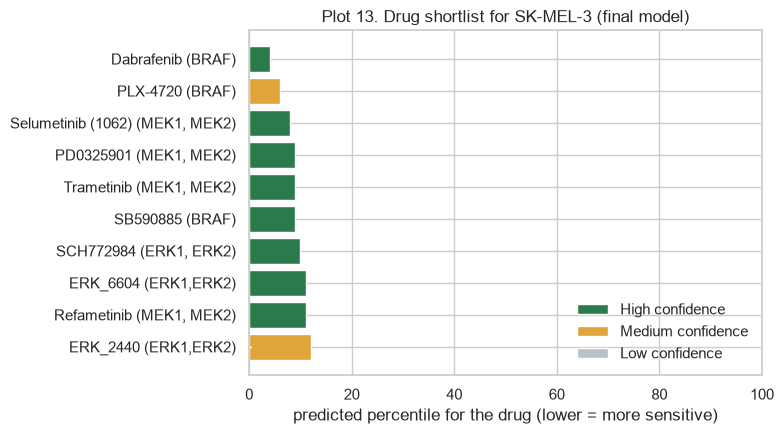

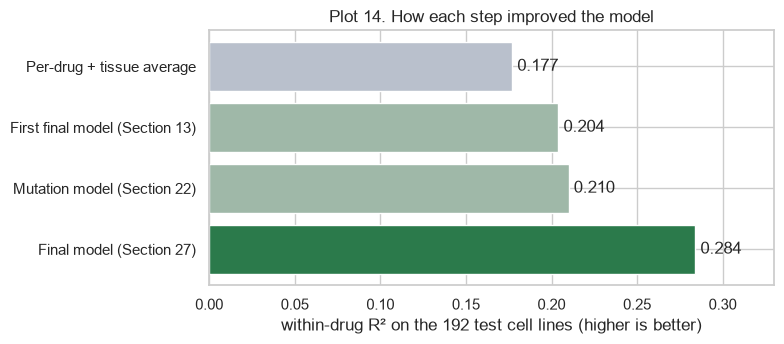

In [42]:
sk_table = add_lab_result(shortlist(tissue_name, genes, model_id=sk_mid), "SK-MEL-3")
fig = plot_shortlist(sk_table, "Plot 13. Drug shortlist for SK-MEL-3 (final model)")
fig.savefig("figures/plot13_final_shortlist.png", dpi=150)
plt.show()

journey = pd.DataFrame({
    "model": ["Per-drug + tissue average", "First final model (Section 13)", "Mutation model (Section 22)", "Final model (Section 27)"],
    "within-drug R2": [score("", p)["within-drug R2"] for p in [pred_drug_tissue, pred_final, pred_new, pred_expr_final]],
})
plt.figure(figsize=(8, 3.6))
plt.barh(journey["model"][::-1], journey["within-drug R2"][::-1], color=["#2b7a4b", "#9fb8a8", "#9fb8a8", "#b9c0cc"])
for k, value in enumerate(journey["within-drug R2"][::-1]):
    plt.text(value + 0.003, k, f"{value:.3f}", va="center")
plt.xlim(0, 0.33)
plt.xlabel("within-drug R² on the 192 test cell lines (higher is better)")
plt.title("Plot 14. How each step improved the model")
plt.tight_layout()
plt.savefig("figures/plot14_model_journey.png", dpi=150)
plt.show()


Plot 13 shows the final model's shortlist for SK-MEL-3, a held-out melanoma line, and Plot 14 shows how within-drug R² grew from the simple tissue average to the final model.


## 28. Checking the final model on repeated splits
As in Sections 18 and 23, we refit the per-drug + tissue average, the Section 22 model and the final model on each of the same 10 random splits, with every setting fixed; nothing is tuned.


In [43]:
if RUN_STABILITY_CHECKS:
    expr_recheck_rows = []
    splits = GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=0).split(data, groups=data["SANGER_MODEL_ID"])
    for split, (tr_idx, te_idx) in enumerate(splits, start=1):
        tr, te = data.iloc[tr_idx], data.iloc[te_idx]
        tissue_pred = drug_tissue_average(tr, te)
        s22_pred = make_predictor(tr, "b", 30)(te)
        s27_pred = make_ex2_predictor(tr, BEST_EX2_ALPHA, ACTIVE_LGB_PARAMS, CHOSEN_WEIGHTS)(te)
        expr_recheck_rows.append({
            "split": split,
            "per-drug + tissue average": within_drug_r2(te, tissue_pred),
            "Section 22 model": within_drug_r2(te, s22_pred),
            "final expression model": within_drug_r2(te, s27_pred),
        })

    expr_recheck_table = pd.DataFrame(expr_recheck_rows)
    expr_recheck_table["gain over baseline"] = expr_recheck_table["final expression model"] - expr_recheck_table["per-drug + tissue average"]
    expr_recheck_table["gain over Section 22"] = expr_recheck_table["final expression model"] - expr_recheck_table["Section 22 model"]

    print("Within-drug R2 on 10 repeated splits:")
    print(expr_recheck_table.round(3).to_string(index=False))

    print("\naverage:", expr_recheck_table.drop(columns="split").mean().round(3).to_dict())
    print("final expression model range:",
          round(float(expr_recheck_table["final expression model"].min()), 3), "to",
          round(float(expr_recheck_table["final expression model"].max()), 3))
    print("gain over baseline (avg, min to max):",
          round(float(expr_recheck_table["gain over baseline"].mean()), 3), "|",
          round(float(expr_recheck_table["gain over baseline"].min()), 3), "to",
          round(float(expr_recheck_table["gain over baseline"].max()), 3))
    print("gain over Section 22 (avg, min to max):",
          round(float(expr_recheck_table["gain over Section 22"].mean()), 3), "|",
          round(float(expr_recheck_table["gain over Section 22"].min()), 3), "to",
          round(float(expr_recheck_table["gain over Section 22"].max()), 3))
    print("splits beating baseline:", int((expr_recheck_table["gain over baseline"] > 0).sum()), "of 10")
    print("splits beating Section 22:", int((expr_recheck_table["gain over Section 22"] > 0).sum()), "of 10")
else:
    print("Skipped (RUN_STABILITY_CHECKS = False). The results from our full run are described below.")


Within-drug R2 on 10 repeated splits:
 split  per-drug + tissue average  Section 22 model  final expression model  gain over baseline  gain over Section 22
     1                      0.227             0.248                   0.324               0.096                 0.075
     2                      0.201             0.226                   0.299               0.098                 0.073
     3                      0.175             0.196                   0.282               0.107                 0.087
     4                      0.209             0.234                   0.304               0.095                 0.070
     5                      0.205             0.219                   0.296               0.090                 0.077
     6                      0.201             0.229                   0.313               0.112                 0.083
     7                      0.221             0.248                   0.325               0.105                 0.078
     8            

**Result.** The final model beats both on all 10 splits. It averages a within-drug R² of 0.298 (range 0.263 to 0.325), against 0.220 for the Section 22 model and 0.196 for the per-drug + tissue average. The gain over the Section 22 model averages 0.078 (range 0.070 to 0.093), much larger than the earlier improvements and just as consistent.


## 29. Sentinel app
The first cell below saves the fitted final model for the hosted version of the app (it only runs inside our repository). The second starts the app here.

Run the cell below and open the link it prints. Pick one of the test cell lines, or describe your own cell line by its tissue and mutated genes, then press **Find drugs**.

The link only works while the notebook is running. If you are only viewing the notebook, Section 27 shows the shortlist the app gives for SK-MEL-3 with the improved model, and our demo video shows the app in use.

In [44]:
# Save the fitted final model for the hosted app in the repo's app/ folder.
# Only fitted models and summaries are saved, never the raw Sanger data.
import joblib
if os.path.isdir("../app"):
    final_parts = dict(zip(predict_final.__code__.co_freevars, [c.cell_contents for c in predict_final.__closure__]))
    examples = test.drop_duplicates("CELL_LINE_NAME")[["CELL_LINE_NAME", "SANGER_MODEL_ID", "tissue"]].reset_index(drop=True)
    example_expr = expr_features(final_parts["expr_fit"], examples)
    levels = np.linspace(0, 100, 101)  # 1% steps: a summary of each drug's results, not the raw values
    bundle = {
        "GENES": GENES, "DRUGS": DRUGS, "TISSUES": sorted(train["tissue"].unique()),
        "drug_info": drug_info,
        "lgb_categories": {col: sorted(train[col].unique()) for col in ["DRUG_ID", "tissue"]},
        "drug_avg": final_parts["d_avg"],
        "drug_tissue_avg": train.groupby(["DRUG_ID", "tissue"])["LN_IC50"].mean(),
        "centered": final_parts["centered"], "ridges": final_parts["ridges"],
        "expr_fit": final_parts["expr_fit"], "drug_weights": final_parts["drug_weights"],
        "percentile_levels": levels,
        "percentile_values": {d: np.percentile(v, levels) for d, v in train_sorted.items()},
        "flag_cutoff": flag_cutoff, "FLAG_LEVEL": FLAG_LEVEL, "confidence": confidence,
        "lines_per_tissue": lines_per_tissue, "lines_per_gene": lines_per_gene,
        "tissue_gene_counts": train_lines.groupby("tissue")[GENES].sum(), "max_genes": max_genes,
        "examples": {row.CELL_LINE_NAME: {"tissue": row.tissue, "genes": test_line_profile(row.CELL_LINE_NAME)[1],
                                          "expr": example_expr.loc[i].values,
                                          "has_rnaseq": row.SANGER_MODEL_ID in expr_log.index}
                     for i, row in examples.iterrows()},
        "lab_results": {name: dict(zip(DRUGS, add_lab_result(pd.DataFrame({"DRUG_ID": DRUGS}), name)["Lab result"]))
                        for name in examples["CELL_LINE_NAME"]},
    }
    joblib.dump(bundle, "../app/model_bundle.joblib", compress=3)
    print("saved app/model_bundle.joblib:", round(os.path.getsize("../app/model_bundle.joblib") / 1e6, 1), "MB")


saved app/model_bundle.joblib: 2.4 MB


In [ ]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"])  # not preinstalled in Colab
import gradio as gr

TISSUES = sorted(train["tissue"].unique())
TEST_LINES = sorted(test["CELL_LINE_NAME"].unique())
LOGO = "figures/Sentinel_Logo.png"
EXAMPLE, NEW_LINE = "Example: held-out cell line", "Enter a new cell line"
LOGO_URL = "https://raw.githubusercontent.com/Mika1904/sentinel/main/Project_Code/figures/Sentinel_Logo.png"
if not os.path.exists(LOGO):  # a fresh Colab session has no figures folder
    try:
        logo_bytes = urllib.request.urlopen(LOGO_URL, timeout=10).read()
        with open(LOGO, "wb") as f:  # only written once the whole download has succeeded
            f.write(logo_bytes)
    except Exception:
        print("Logo could not be downloaded; the app runs without it.")

def ask_for(text):
    # shown instead of results when an input is missing
    return text, None, None, gr.update(choices=[], value=None), None

def find_drugs(mode, line_name, tissue, genes):
    genes = genes or []  # an emptied gene box gives None
    if mode == EXAMPLE and not line_name:
        return ask_for("Please pick a held-out cell line.")
    if mode == NEW_LINE and not tissue:
        return ask_for("Please pick a tissue.")
    if mode == EXAMPLE:
        tissue, genes = test_line_profile(line_name)
        model_id = test_line_model_id(line_name)
        name = line_name
    else:
        model_id = None
        name = "Your cell line"
    table = shortlist(tissue, genes, model_id=model_id)
    if mode == EXAMPLE:
        table = add_lab_result(table, line_name)
    summary = f"### {name}\n{tissue} · mutated: {', '.join(genes) if genes else 'none of the 84 genes'}"
    n_flagged = int((table["Predicted sensitive"] == "Yes").sum())
    if n_flagged > 0:
        summary += f"\n\n**{n_flagged} of the top 10** are predicted sensitive (in the lowest {FLAG_LEVEL:.0%} for that drug)."
    else:
        summary += f"\n\n**No drug is predicted sensitive** for this profile (none reaches the lowest {FLAG_LEVEL:.0%}), so treat the list as weak candidates."
    for note in input_warnings(tissue, genes, model_id=model_id):
        summary += f"\n\n**Caution:** {note}"
    choices = [(drug, int(drug_id)) for drug, drug_id in zip(table["Drug"], table["DRUG_ID"])]
    profile = {"tissue": tissue, "genes": list(genes), "model_id": model_id}
    fig = plot_shortlist(table, "Top 10 drugs")
    plt.close(fig)  # keep the figure out of the notebook output; Gradio still renders it
    return (summary, table.drop(columns="DRUG_ID"), fig,
            gr.update(choices=choices, value=choices[0][1]), profile)

def why(profile, drug_id):
    if not profile or drug_id is None:
        return None
    return gene_effects(profile["tissue"], profile["genes"], int(drug_id), model_id=profile.get("model_id"))

def switch_mode(mode):
    test_mode = mode == EXAMPLE
    return gr.update(visible=test_mode), gr.update(visible=not test_mode), gr.update(visible=not test_mode)

FONT = gr.themes.GoogleFont("Inter")  # one font for all text, including tables
THEME = gr.themes.Soft(font=FONT, font_mono=FONT)
CSS = ".gradio-container {width: 100%; max-width: 960px !important; margin: 0 auto !important} #header, #footer {text-align: center}"

with gr.Blocks(title="Sentinel") as app:
    if os.path.exists(LOGO):
        gr.Image(LOGO, show_label=False, container=False, buttons=[], interactive=False, height=110)
    gr.Markdown("# Sentinel", elem_id="header")
    profile_state = gr.State()
    with gr.Column(variant="panel"):
        with gr.Row():
            mode = gr.Radio([EXAMPLE, NEW_LINE], value=EXAMPLE, label="Input")
            line_box = gr.Dropdown(TEST_LINES, value="SK-MEL-3", label="Held-out cell line")
            tissue_box = gr.Dropdown(TISSUES, value="Skin", label="Tissue", visible=False)
            gene_box = gr.Dropdown(GENES, value=["BRAF"], multiselect=True, label="Mutated genes", visible=False)
        find_button = gr.Button("Find drugs", variant="primary")
    summary_box = gr.Markdown()
    with gr.Tabs():
        with gr.Tab("Top 10 drugs"):
            table_box = gr.Dataframe(interactive=False, buttons=[], label="Lower percentile = more sensitive")
        with gr.Tab("Chart"):
            plot_box = gr.Plot(show_label=False)
        with gr.Tab("Why this drug?"):
            drug_box = gr.Dropdown(label="Pick a drug", choices=[])
            genes_box = gr.Dataframe(interactive=False, buttons=[], label="Genes that move this prediction most (negative shift = more sensitive)")
    gr.Markdown("*Research prototype on lab cell lines, not medical advice.*", elem_id="footer")

    inputs = [mode, line_box, tissue_box, gene_box]
    outputs = [summary_box, table_box, plot_box, drug_box, profile_state]
    mode.change(switch_mode, mode, [line_box, tissue_box, gene_box])
    # refresh the gene table after every search, even when the top drug stays the same
    find_button.click(find_drugs, inputs, outputs).then(why, [profile_state, drug_box], genes_box)
    app.load(find_drugs, inputs, outputs).then(why, [profile_state, drug_box], genes_box)
    drug_box.change(why, [profile_state, drug_box], genes_box)

app.launch(theme=THEME, css=CSS, footer_links=[], inline=False, share=True)  # share=True gives a public link, which Colab needs

## 30. Summary
- **Data.** 958 cancer cell lines from 28 tissues, 286 drugs (295 drug IDs) and 239,081 results, with 84 mutation features and RNA-seq expression for 933 lines. Split by cell line into 766 training and 192 test lines; the test lines were never used to choose anything.
- **Baseline.** Knowing the drug alone gives R² = 0.716, so we compare methods by within-drug R². The per-drug + tissue average scores 0.177 and was hard to beat.
- **First model (Sections 8–20).** A blend of that average with LightGBM: within-drug R² 0.204, and 44.3% of its top 10 drugs were truly sensitive (20.3% at random). It missed about 7 in 10 sensitive results, and its gain over the baseline held on 10 repeated splits but was small.
- **Stress test (Section 21).** It barely used mutations: adding TP53 moved Nutlin-3a by 1.3 percentiles, although 53% of TP53-normal and 4% of TP53-mutant cell lines were sensitive in the lab.
- **Fix (Sections 22–23).** A ridge regression for each drug made all 9 drug–gene pairs we checked move in the lab's direction (within-drug R² 0.210, better than the first model on all 10 repeated splits).
- **Gene expression (Sections 24–28).** A first attempt raised cross-validation within-drug R² to 0.282 but failed our mutation check, so we did not use it. A two-stage design, tuned LightGBM and per-drug weights passed, with 19 settings compared in total. On the test lines the final model scores within-drug R² 0.284 (RMSE 1.235), 52.1% of its top 10 drugs were truly sensitive, and it beat the Section 22 model on all 10 repeated splits (average 0.298 against 0.220).
- **Missed cases and false alarms.** At the 25% flag level it finds 39.8% of sensitive results with 6.1% false alarms, so it still misses about 6 in 10: it can rank drugs but not rule them out.
- **Groups.** Recall differs by sex (34.2% male, 26.3% female) and age (50.2% under 18, 7.5% over 65), but without blood cancers every known group is between 4.7% and 7.5%, so the gaps follow the share of blood cancers.
- **Remaining failures.** BRAF-normal melanoma still gets Dabrafenib ranked 2nd; rare mutations such as EGFR (21 cell lines) are learned poorly; new cell lines without expression data use their tissue's average.
- **Limitations.** All results come from lab cell lines, not patients. The mutation features cover 84 driver genes only and may include some inherited variants, and 71.8% of IC50 values lie above the highest tested dose.

With more time we would work with a lab to test Sentinel's top-ranked drugs on new cell lines, test it on an independent panel outside GDSC2, and add copy-number data.


## 31. Sources

**Data** (Wellcome Sanger Institute, downloaded automatically by Section 2)
- GDSC2 drug response, release 8.5 (`GDSC2_fitted_dose_response_27Oct23.xlsx`), via [Cell Model Passports downloads](https://cellmodelpassports.sanger.ac.uk/downloads). The original GDSC site ([cancerrxgene.org](https://www.cancerrxgene.org/)) now points there.
- Cell Model Passports: cell line annotations (`model_list_20261013.csv`), driver mutations (`mutations_summary_20260724.zip`) and sequencing availability (`model_dataset_availability_20260727.csv`) ([downloads](https://cellmodelpassports.sanger.ac.uk/downloads)).
- Cell Model Passports RNA-seq expression (`rnaseq_merged_20260323.zip`, file `rnaseq_merged_rsem_tpm_20260323.csv`, "RNA-Seq processed data"). It combines Sanger and Broad Institute (CCLE) RNA-seq; where a cell line was sequenced by both, the Sanger data is used.
- Used under the [Sanger DepMap Data Usage Policy](https://depmap.sanger.ac.uk/documentation/data-usage-policy/) (academic and educational use; raw files are not redistributed). File details in `data/DATA_SOURCES.md`.

**Data papers**
1. Yang W, et al. Genomics of Drug Sensitivity in Cancer (GDSC): a resource for therapeutic biomarker discovery in cancer cells. *Nucleic Acids Research* 41(D1):D955–D961, 2013. https://doi.org/10.1093/nar/gks1111
2. Iorio F, et al. A Landscape of Pharmacogenomic Interactions in Cancer. *Cell* 166(3):740–754, 2016. https://doi.org/10.1016/j.cell.2016.06.017
3. van der Meer D, et al. Cell Model Passports — a hub for clinical, genetic and functional datasets of preclinical cancer models. *Nucleic Acids Research* 47(D1):D923–D929, 2019. https://doi.org/10.1093/nar/gky872
4. Ghandi M, et al. Next-generation characterization of the Cancer Cell Line Encyclopedia. *Nature* 569:503–508, 2019. https://doi.org/10.1038/s41586-019-1186-3 (Broad Institute RNA-seq in the merged expression file)

**Methods**
5. Ke G, et al. LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *Advances in Neural Information Processing Systems* 30, 2017. [Link](https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)
6. Friedman JH. Greedy function approximation: a gradient boosting machine. *Annals of Statistics* 29(5):1189–1232, 2001. https://doi.org/10.1214/aos/1013203451
7. Hoerl AE, Kennard RW. Ridge Regression: Biased Estimation for Nonorthogonal Problems. *Technometrics* 12(1):55–67, 1970. https://doi.org/10.1080/00401706.1970.10488634
8. Jolliffe IT, Cadima J. Principal component analysis: a review and recent developments. *Philosophical Transactions of the Royal Society A* 374:20150202, 2016. https://doi.org/10.1098/rsta.2015.0202
9. Pedregosa F, et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12:2825–2830, 2011. [Link](https://jmlr.org/papers/v12/pedregosa11a.html) (cross-validation by group: [scikit-learn guide](https://scikit-learn.org/stable/modules/cross_validation.html))

**Biology behind the drug–gene checks**
10. Hauschild A, et al. Dabrafenib in BRAF-mutated metastatic melanoma: a multicentre, open-label, phase 3 randomised controlled trial. *The Lancet* 380(9839):358–365, 2012. https://doi.org/10.1016/S0140-6736(12)60868-X
11. Vassilev LT, et al. In Vivo Activation of the p53 Pathway by Small-Molecule Antagonists of MDM2. *Science* 303(5659):844–848, 2004. https://doi.org/10.1126/science.1092472
12. Lynch TJ, et al. Activating Mutations in the Epidermal Growth Factor Receptor Underlying Responsiveness of Non–Small-Cell Lung Cancer to Gefitinib. *New England Journal of Medicine* 350:2129–2139, 2004. https://doi.org/10.1056/NEJMoa040938
13. André F, et al. Alpelisib for PIK3CA-Mutated, Hormone Receptor–Positive Advanced Breast Cancer. *New England Journal of Medicine* 380:1929–1940, 2019. https://doi.org/10.1056/NEJMoa1813904

**Software**
14. McKinney W. Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61, 2010. https://doi.org/10.25080/Majora-92bf1922-00a ([pandas](https://pandas.pydata.org))
15. Harris CR, et al. Array programming with NumPy. *Nature* 585:357–362, 2020. https://doi.org/10.1038/s41586-020-2649-2 ([NumPy](https://numpy.org))
16. Hunter JD. Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering* 9(3):90–95, 2007. https://doi.org/10.1109/MCSE.2007.55 ([Matplotlib](https://matplotlib.org))
17. Waskom ML. seaborn: statistical data visualization. *Journal of Open Source Software* 6(60):3021, 2021. https://doi.org/10.21105/joss.03021 ([Seaborn](https://seaborn.pydata.org))
18. Abid A, et al. Gradio: Hassle-Free Sharing and Testing of ML Models in the Wild. arXiv:1906.02569, 2019. https://arxiv.org/abs/1906.02569 ([Gradio](https://www.gradio.app))
- Also used: [Python](https://www.python.org), [scikit-learn](https://scikit-learn.org), [LightGBM](https://lightgbm.readthedocs.io), [Google Colab](https://colab.research.google.com).

**AI tools**
[Claude](https://claude.ai) (Anthropic) and [Gemini](https://gemini.google.com) (Google) were used to help write and review code, check data merges, find the download URLs and edit text. The team reviewed and ran all code, and every number in this notebook comes from its own output.